# Imputation of Missing Values in a Synthetic Asset Dataset

**Team 19** · University of Adelaide · in partnership with SA Power Networks<br>
Final version · November 2026

---

**Abstract.** Asset registers are rarely complete: location, installation date, equipment model and condition readings are often missing or recorded with error. This study evaluates how well a missing attribute can be recovered from the other attributes of the same record, and identifies the conditions under which recovery degrades, the form the degradation takes, and its causes. A synthetic register of 10,000 assets is used, in which measurement noise, missingness and the relationships between columns are set in advance, so every imputed value can be scored against its true value. Eleven imputation models are evaluated under one protocol in fifteen scenarios, and two main models are compared with the baseline throughout.

**Models compared**

| Role | Model | Type |
|:---|:---|:---|
| Baseline | Median and mode | One value per column |
| Main model | **Random Forest** | Tree-based, chained |
| Main model | **GMM** (Gaussian mixture model) | Probabilistic, joint |

**Protocol**

- **Scenarios:** 15 in total. Nine combine completion 0.9, 0.8 and 0.7 with noise 0, 5% and 10%; six add other missingness mechanisms, recording errors and heavier missingness.
- **Validation:** five folds; every hidden cell is predicted by a model that has not seen its record.
- **Information:** models receive measured data only; the truth is used for scoring only.
- **Measure:** skill, the share of the baseline's error removed on the same cells (section 3.4).

**Contents**

1. Setup
2. Data
3. Experimental design
4. Models, one section per model
5. Overview of results for all eleven models
6. Conditions of degradation
7. Characteristics of failure
8. Causes of failure
9. Value for downstream analysis
10. Limitations

Appendix: pairwise comparisons, stability, runtime, exported tables and references.

Chapters 6 to 9 compare Random Forest and GMM with the baseline.

**Conventions.** Tables and figures are numbered by section (Table 6.3a, Figure 6.3a); table captions stand above the table and figure captions below it. The design document, `docs/DESIGN.md`, describes the workflow, the code, the libraries, the design decisions and the tests.

**Scope.** The notebook documents the experiments and explains how to read each result; their interpretation is reported separately. The results describe this synthetic dataset and do not establish performance on real SA Power Networks assets.


## 1. Setup

**Environment.** Create it once, select the kernel **Python (imputation)** and use Restart and Run All.

```
conda create -n imputation python=3.12
conda activate imputation
pip install -r requirements.txt
python -m ipykernel install --user --name imputation --display-name "Python (imputation)"
```

**Run options.** The next cell loads the study code and sets the run options.

| Option | Effect |
|---|---|
| `RUN_ID` | Run folder in `outputs/imputation-study/runs`. Tasks already saved there are skipped and the rest are fitted. `None` starts a new folder and fits every model. |
| `EVALUATION_RUN_ID` | Evaluates a finished run without entering the task lists of the model sections. |
| `QUICK` | Runs every stage on a small sample with small models to check the code. Its numbers are not results. |

**Saved results.** Results are reused at two levels. The predictions of each task are saved when the task finishes, and the evaluation tables built from them are saved in the run folder. Saved predictions are reused only while the data, the settings and the prediction code are unchanged; saved tables are rebuilt whenever the evaluation code or the set of finished tasks changes. The notebook is set to the final run, `20261115-121714`; Run All reads its saved results, refits no model and completes in under a minute.


In [1]:
# Study code, run options and the study object that holds the run folder.
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src/synthetic_imputation").is_dir():
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
# A kernel left open keeps earlier versions of these modules, so they are always reloaded.
for name in [m for m in sys.modules if m.startswith("synthetic_imputation")]:
    del sys.modules[name]

from synthetic_imputation import evaluation as ev
from synthetic_imputation import failure as fl
from synthetic_imputation import figures as fg
from synthetic_imputation import relationships as rel
from synthetic_imputation.columns import NUMERIC_TARGETS, TARGETS, column_table
from synthetic_imputation.data import (
    audit_design, audit_fields, audit_files, discover, read_truth, relationship_residuals,
)
from synthetic_imputation.mechanisms import DESCRIPTIONS
from synthetic_imputation.names import CATEGORY_METHODS, NUMERIC_METHODS
from synthetic_imputation.runner import (
    StudyConfig, default_workers, plan_table, quick_config,
)
from synthetic_imputation.study import Study
from synthetic_imputation.miceforest_compat import require_supported_version

QUICK = False                # True: small sample and small models, to check the code only
RUN_ID = "20261115-121714"   # saved tasks in this run are skipped; None starts a new run
EVALUATION_RUN_ID = None     # a finished run to evaluate without entering the model sections
WORKERS = default_workers()

CONFIG = quick_config() if QUICK else StudyConfig()
ALL_SCENARIOS = discover(ROOT / CONFIG.data_directory)
SCENARIOS = {name: ALL_SCENARIOS[name] for name in (CONFIG.scenarios or sorted(ALL_SCENARIOS))}
REPRESENTATIVE = CONFIG.representative
NOISE_FREE, HIGH_NOISE = CONFIG.noise_series[0], CONFIG.noise_series[-1]

require_supported_version()
fg.apply_style()
pd.set_option("display.max_columns", None, "display.max_colwidth", 140, "display.width", 200,
              "display.max_rows", 200)
print("Mode:", "QUICK CHECK, not findings" if QUICK else "full study")
print("Scenarios:", len(SCENARIOS), "| worker processes:", WORKERS)

STUDY = Study(ROOT, CONFIG, SCENARIOS, WORKERS, RUN_ID, EVALUATION_RUN_ID)
print("Run folder:", STUDY.directory)
print("Stage:", "evaluation of a finished run" if EVALUATION_RUN_ID
      else "saved tasks are skipped, missing tasks are fitted" if RUN_ID else "every model is fitted")


Mode: full study
Scenarios: 9 | worker processes: 12


Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\synthetic-imputation-final\outputs\imputation-study\runs\20261115-121714
Stage: saved tasks are skipped, missing tasks are fitted


## 2. Data

### 2.1 Generation

The dataset describes 10,000 assets on a 100 × 100 grid, generated row by row in grid order, so installation days increase along the grid. Each asset has an equipment model, environmental exposures, three gas readings, a leakage rate and a remaining-life value. Every scenario consists of two tables with the same rows and columns:

- **truth**: the values before measurement error and before any cell is hidden;
- **measured**: the table the models see, with measurement error and hidden cells.

Two controls are set in the file name. `completion`, $c$, is the probability that a cell remains visible: a cell is hidden when its mask draw $m \sim \mathcal{U}(0, 1)$ exceeds $c$, independently of every value, so values are missing completely at random (Rubin, 1976). `noise`, $\eta$, bounds a uniform multiplicative error on the measured columns,

$$\tilde{v} = v\,(1 + \eta\,u), \qquad u \sim \mathcal{U}(-1, 1),$$

so `noise0.05` allows a reading to deviate by up to ±5% of its true value $v$. The nine scenarios share the same assets, the same draws $u$ and $m$, and therefore nested masks, so a difference between two scenarios is attributable to the changed control and can be measured on identical cells.


### 2.2 Column definitions

Each column's meaning, type, valid range and error tolerance follow from what the column represents, not from patterns in the data (Table 2.2).


In [2]:
# Meaning, type, valid range and tolerance of every column, fixed before any data was read.
with pd.option_context("display.max_colwidth", None):
    fg.table("Table 2.2", "Column definitions: meaning, type, valid range and error tolerance.", column_table())


**Table 2.2.** Column definitions: meaning, type, valid range and error tolerance.

,column,meaning,family,unit,scale,noisy,valid range,tolerance,treatment
0,x,Grid row of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,"Numeric coordinate, not a category. Predictions stay on the grid (rounded, 0-99). The zero point is arbitrary, so tolerance is in cells rather than percent."
1,y,Grid column of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,Same treatment as x.
2,install_date,"Installation day, counted from the start of the sequence",location and date,days,interval,no,0 to -,±7 and ±30 days,"Whole-day counter with no calendar origin, so it stays a number and is not converted to age. The origin is arbitrary, so tolerance is in days rather than percent."
3,model_id,Equipment model,asset condition,category,nominal,no,- to -,exact class,"Nominal label: the numbers 0-3 have no order. One-hot encoded as a predictor, with missing as its own level, and classified as a target. Never regressed or rounded."
4,altitude,Ground altitude at the location,location and date,synthetic units,interval,no,100 to 298,±1 and ±5 synthetic units,"Whole-number field limited to the range the grid can produce (100-298). Its zero point does not compare assets, so tolerance is in units rather than percent."
5,measured_humid,Humidity exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,"Noisy reading between 0 and 1 with a true zero, so percent tolerance is valid. Predictions are limited to that range. Scored against the noise-free truth."
6,measured_salt,Salt exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,Same treatment as measured_humid.
7,measured_overgrowth,Vegetation overgrowth reading,field reading,index,ratio,yes,0 to 2,±10% and ±15%,"Floored at zero by definition, so exact zeros are real readings, not missing data. Percent tolerance cannot apply to a true zero; zero and positive cells are evaluated separately."
8,life,Remaining-life indicator,asset condition,synthetic units,ratio,no,0 to 100000,±100 and ±500 synthetic units,"Exact asset outcome. It sits in a narrow band just under its ceiling, where ±10% would accept almost any value, so tolerance is in units. Predictions cannot exceed the ceiling."
9,random_placebo,Random number unrelated to any other column,control,index,ratio,yes,0 to 1,±10% and ±15%,"Negative control, limited to 0-1. It is imputed and scored like any target, but any real gain over the median would be a false finding."


Tolerances differ by column:

- **Coordinates, days and altitude** have an arbitrary zero point, so absolute limits are used.
- **`life`** lies in a narrow band below its ceiling, where ±10% would accept almost any value, so absolute limits are used.
- **Humidity, salt, overgrowth and the placebo** have a true zero and a wide relative range, so percentage limits are used.
- **Gas columns and `leakage`** vary less and have tighter percentage limits; `total_gas` has the tightest.


### 2.3 File audit

The next three cells check each file pair against its definition. Table 2.3a and Figure 2.3 give the shape and the observed share of each column; `measurement MAE` is the error already present in observed cells. Table 2.3b gives the measurement error by column and noise level, and Table 2.3c tests it against the bound in the file name.


**Table 2.3a.** Shape, observed share and measurement error of each scenario's file pair.

,scenario,completion,noise,rows,columns,missing share,columns with missing cells
0,completion0.7-noise0.0,0.7,0.00,10000,15,0.2997,15
1,completion0.7-noise0.05,0.7,0.05,10000,15,0.2997,15
2,completion0.7-noise0.1,0.7,0.10,10000,15,0.2997,15
3,completion0.8-noise0.0,0.8,0.00,10000,15,0.1995,15
4,completion0.8-noise0.05,0.8,0.05,10000,15,0.1995,15
5,completion0.8-noise0.1,0.8,0.10,10000,15,0.1995,15
6,completion0.9-noise0.0,0.9,0.00,10000,15,0.0995,15
7,completion0.9-noise0.05,0.9,0.05,10000,15,0.0995,15
8,completion0.9-noise0.1,0.9,0.10,10000,15,0.0995,15


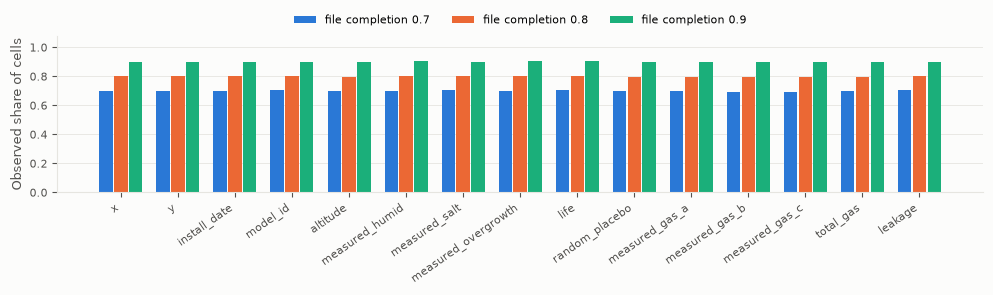

**Figure 2.3.** Observed share of each column at the three completion levels of the generator's files.

In [3]:
# Shape, observed share and measurement error of every file pair.
FILE_AUDIT = audit_files(ALL_SCENARIOS)
FIELD_AUDIT = audit_fields(ALL_SCENARIOS)
fg.table("Table 2.3a", "Shape, observed share and measurement error of each scenario's file pair.", FILE_AUDIT.round(4))
fg.plot_missingness(FIELD_AUDIT, None)
fg.caption("Figure 2.3", "Observed share of each column at the three completion levels of the generator's files.")


In [4]:
# Measurement error by column and noise level, and three checks against the file definitions.
noise_check = FIELD_AUDIT.groupby(["column", "noise"], sort=False).agg(
    changed=("changed share", "mean"),
    largest=("largest relative change", "max"),
    measurement_mae=("measurement MAE", "mean"),
).unstack("noise")
fg.table("Table 2.3b", "Share of observed cells changed by noise, largest relative change and measurement MAE, "
         "by column and noise level.", noise_check.round(4))

noise_free = FIELD_AUDIT[FIELD_AUDIT.noise.eq(0)]
inside_bound = (FIELD_AUDIT["largest relative change"] <= FIELD_AUDIT.noise + 1e-9).all()  # tolerance for rounding
never_noisy = FIELD_AUDIT[~FIELD_AUDIT["defined as noisy"]]["changed share"].eq(0).all()
checks = pd.DataFrame({
    "check": ["Noise-free files equal the truth in every observed cell",
              "Every measured value lies inside the bound in its file name",
              "Columns defined without noise are unchanged in every file"],
    "passed": [bool(noise_free["changed share"].eq(0).all()), bool(inside_bound), bool(never_noisy)],
})
fg.table("Table 2.3c", "Checks of the measured files against their definitions.", checks)


**Table 2.3b.** Share of observed cells changed by noise, largest relative change and measurement MAE, by column and noise level.

changed                 largest            measurement_mae                    
noise                  0.00    0.05    0.10    0.00  0.05 0.10            0.00      0.05      0.10
column                                                                                            
x                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
y                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
install_date            0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
model_id                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
altitude                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
measured_humid          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0083    0.0166
measured_salt           0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0104    0.0208
measured_overgrowth     0.0  0.6773  0.6773     0.0  0.05  0.1             0.0    0.0083    0.0167
life                    0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
random_placebo          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0125    0.0251
measured_gas_a          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.2870  466.5740
measured_gas_b          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  243.3178  486.6355
measured_gas_c          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.6805  467.3610
total_gas               0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
leakage                 0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000

**Table 2.3c.** Checks of the measured files against their definitions.

,check,passed
0,Noise-free files equal the truth in every observed cell,True
1,Every measured value lies inside the bound in its file name,True
2,Columns defined without noise are unchanged in every file,True


Table 2.3d confirms that scenarios can be compared cell by cell, and Table 2.3e that the truth satisfies the generator's definitions.


In [5]:
# Properties that make scenarios comparable, and the generator's definitions checked on the truth.
with pd.option_context("display.max_colwidth", None):
    fg.table("Table 2.3d", "Properties that make the scenarios comparable cell by cell.",
             audit_design(ALL_SCENARIOS))
fg.table("Table 2.3e", f"Largest deviation of the truth from the generator's definitions, `{REPRESENTATIVE}`.",
         relationship_residuals(read_truth(ALL_SCENARIOS[REPRESENTATIVE])))


**Table 2.3d.** Properties that make the scenarios comparable cell by cell.

,property,holds
0,Every file has the same truth,True
1,A completeness level hides the same cells at every noise level,True
2,Cells hidden at higher completeness are also hidden at lower completeness,True


**Table 2.3e.** Largest deviation of the truth from the generator's definitions, `completion0.8-noise0.05`.

,definition,largest residual
0,altitude = x + y + 100,0.000000e+00
1,"overgrowth = max(2 humid - salt, 0)",4.440892e-16
2,total_gas = gas a + b + c,1.273293e-11
3,life follows the formula of the row's model,4.365575e-11


### 2.4 Generator revisions

The dataset was regenerated after review with the generator's author; the first version is kept in `data/datasets_v1`.

- **Masking** covers all 15 columns; the first version covered only the first eight.
- **Noise** applies only to humidity, salt, overgrowth, the placebo and the three gas readings. `life`, `total_gas` and `leakage` are exact by design, so some columns stay reliable when others degrade.
- **Gas and `life`:** more gas reduces `life` for every equipment model. The scale `total_gas/300000` is kept from the first version, so this term is small.
- **Model 0** uses `day_count` in its overgrowth term, as the other models do; the first version used an undefined variable.
- **Missingness** in the generator's files is completely at random only.


### 2.5 Additional scenarios

The generator hides every cell with the same probability and stops at 0.7 completion. Six scenarios are derived from its files to cover other conditions. Each differs from a generator scenario in one respect, uses the generator's truth file, and keeps every visible value unchanged unless the scenario concerns wrong values.

| Scenario | Source file | Change |
|---|---|---|
| age | 0.9, reduced to 0.8 completion | Older assets lose more cells |
| value | 0.9, reduced to 0.8 completion | Higher values are hidden more often |
| group | 0.9, reduced to 0.8 completion | Related columns are hidden together: location, gas readings, environmental readings, and date with model |
| errors | 0.8, same mask | 5% of visible installation days shift by 60 days; 2% of visible `model_id` values become another model |
| completion 0.5 and 0.3 | 0.7 | Further cells hidden at random, nested within the 0.7 mask |

Table 2.5a reports, for each scenario, the hidden share overall, by age third and in the lowest and highest fifth of `life`; the share of rows in which `x`, `y` and `altitude` are all hidden; and the number of visible values that differ from the representative scenario. Table 2.5b states how each scenario is constructed.


In [6]:
# Hidden share by age and by value of `life`, and changed visible values, in each added scenario.
truth = read_truth(ALL_SCENARIOS[REPRESENTATIVE])
age_third = pd.qcut(truth.install_date.rank(method="first"), 3, labels=["oldest third", "middle third", "newest third"])
life = truth.life
reference = STUDY.measured[REPRESENTATIVE]
rows = []
for name, frame in {REPRESENTATIVE: reference, **{n: STUDY.measured[n] for n in STUDY.mechanisms}}.items():
    hidden = frame.isna()
    by_age = hidden.mean(axis=1).groupby(age_third.reindex(frame.index), observed=True).mean()
    # A visible value counts as changed only where both files show the cell.
    changed = (frame != reference) & frame.notna() & reference.reindex(frame.index).notna()
    rows.append({
        "scenario": name, "mechanism": STUDY.scenarios[name].mechanism, "hidden share": hidden.to_numpy().mean(),
        **by_age.to_dict(),
        "life: lowest fifth": hidden.life[life.reindex(frame.index) <= life.quantile(0.2)].mean(),
        "life: highest fifth": hidden.life[life.reindex(frame.index) >= life.quantile(0.8)].mean(),
        "x, y and altitude all hidden": (hidden.x & hidden.y & hidden.altitude).mean(),
        "visible values changed": int(changed.to_numpy().sum()),
    })
fg.table("Table 2.5a", "Hidden share overall, by age third and by fifth of `life`, and visible values changed "
         "relative to the representative scenario.", pd.DataFrame(rows).round(3))
construction = pd.Series(DESCRIPTIONS, name="construction").rename_axis("scenario").to_frame()
with pd.option_context("display.max_colwidth", None):
    fg.table("Table 2.5b", "Construction of each added scenario.", construction)


**Table 2.5a.** Hidden share overall, by age third and by fifth of `life`, and visible values changed relative to the representative scenario.

,scenario,mechanism,hidden share,oldest third,middle third,newest third,life: lowest fifth,life: highest fifth,"x, y and altitude all hidden",visible values changed
0,completion0.8-noise0.05,random,0.200,0.201,0.201,0.197,0.194,0.204,0.007,0
1,completion0.8-noise0.05-age,age,0.199,0.266,0.200,0.131,0.149,0.176,0.010,0
2,completion0.8-noise0.05-value,value,0.199,0.197,0.199,0.202,0.112,0.280,0.008,0
3,completion0.8-noise0.05-group,group,0.197,0.198,0.199,0.195,0.196,0.208,0.108,0
4,completion0.8-noise0.05-errors,errors,0.200,0.201,0.201,0.197,0.194,0.204,0.007,566
5,completion0.5-noise0.05-sparse,sparse,0.499,0.498,0.502,0.496,0.492,0.494,0.125,0
6,completion0.3-noise0.05-sparse,sparse,0.700,0.698,0.702,0.700,0.706,0.694,0.343,0


**Table 2.5b.** Construction of each added scenario.

,construction
scenario,
age,Older assets lose more cells: the hidden share falls from 30% for the oldest row to 10% for the newest.
value,Higher values are hidden more often: the hidden share rises from 10% for the lowest value of a column to 30% for the highest. model_id is nominal and is hidden at random.
group,"Related columns go missing together: location, gas readings, environment readings, and date with model are each hidden as a block. life, leakage and the placebo are hidden on their own."
errors,"The representative mask, with 5% of visible installation days shifted by 60 days and 2% of visible model_id values replaced by another model."
sparse,"More cells hidden completely at random than in any generator file, at the representative noise level."


## 3. Experimental design

### 3.1 Targets and predictors

All 15 columns contain hidden cells, so all are imputation targets: 14 numeric columns and the categorical `model_id`. For each target, every other column is a predictor. `random_placebo` is unrelated to every other column and serves as a negative control: no model should predict it better than the median.

### 3.2 Preprocessing

All fitted quantities, including means, scales and category levels, come from the training fold.

| Step | Decision | Reason |
|---|---|---|
| Missing predictors | Left missing at the start | Each method handles gaps natively, so no fixed value is invented; chained models then replace gaps with their own estimates |
| Missing indicators | Not used | Masks in the generator's files are random, so an indicator carries no information about the value |
| `model_id` as a predictor | One-hot for distance and linear models; a category or number for trees | The column is nominal, so distances and coefficients must not treat its codes as an order |
| Row position | Never a feature | It would reveal the grid position and is not a property of an asset |
| Predictions | Limited to the valid range; whole-number columns rounded | This follows from the column definitions; the raw value is kept, and section 7.2 reports how often the limit applied |

### 3.3 Hyperparameter selection

Settings were fixed before the evaluation, from a fixed list of candidates, by a rule set before any candidate was scored. The same settings apply in every scenario, so differences between scenarios are not caused by different settings.

- **Data:** the three scenarios at 0.7 completion. Masks are nested, so these cells are visible in every scenario; no cell hidden in any scenario and no truth file is read.
- **Score:** a further 10% of observed cells is hidden, and the error on those cells is compared with the median's error, excluding `random_placebo`.
- **Choice:** candidates more than 1% worse than the median on `random_placebo` are dropped; of the rest, those within 0.002 of the best score are kept, and the fastest is chosen.

The candidates included each chained model without a ridge base and with a linear base, and every chained model was offered the same range of passes. The second-order base scored best for every model; section 8.5 measures its effect again against the truth. The rule and all scores are in `outputs/imputation-study/optimisation/clean_selection`.

Five models run from the project's shared source code in `src/synthetic_imputation/vendor`. The source code of GMM and the masked MLP records default settings and a search space but no selected settings, so both were chosen with the same rule from the defaults and seven candidates drawn from that space. Two further rounds, each declared before it was scored, extended the candidates beyond the edges of the space, after which selection stopped. LightGBM chained, Predictive MissForest and MICE-PMM have fully documented settings and are used as documented. The rule, candidates and scores are in `outputs/imputation-study/optimisation/merge_selection`.

### 3.4 Evaluation metrics

Five folds are shared by all methods within a seed. Each hidden cell is predicted by a model that has not seen its row and is scored against the truth. For a model $f$ and a set of hidden cells $H$ of one column, with true values $v_i$ and estimates $\hat{v}_i$:

$$\mathrm{MAE}_f = \frac{1}{|H|} \sum_{i \in H} \lvert \hat{v}_i - v_i \rvert, \qquad \mathrm{skill}_f = 1 - \frac{\mathrm{MAE}_f}{\mathrm{MAE}_{\text{baseline}}},$$

where both errors are computed on the same cells $H$. Skill is 0 for the baseline, 1 for exact recovery and below 0 for a model worse than the baseline.

| Measure | Use |
|---|---|
| MAE, RMSE, R², bias | Size and direction of error, in the column's unit |
| Skill | Share of the baseline's error removed on the same cells |
| Relative change in error | $\mathrm{MAE}_{\text{after}} / \mathrm{MAE}_{\text{before}} - 1$ on the same cells, for a change of condition |
| Error in SD | Mean signed or absolute error divided by the column's standard deviation in the truth, to compare columns |
| Tolerance rate | Share within the column's tight and loose limits (section 2.2) |
| Exact rate | Share of whole-number columns recovered exactly |
| Accuracy, macro F1, balanced accuracy | `model_id`; log loss, Brier score and calibration gap for its probabilities |

MAE is never averaged across columns, because their units differ. Skill is unit-free and is therefore used to compare columns and conditions; section 5.1 defines the failure criterion in terms of skill.

### 3.5 Experiment plan

Table 3.5 lists the planned tasks; the experiments are described below it.


In [7]:
# Planned tasks of every experiment.
fg.table("Table 3.5", f"Planned tasks by experiment ({len(STUDY.plan):,} in total).", plan_table(STUDY.plan))


**Table 3.5.** Planned tasks by experiment (3,580 in total).

,experiment,tasks,scenarios,seeds,methods
0,main,1170,9,1,13
1,stability,260,1,2,13
2,spatial,130,1,1,13
3,budget,10,1,1,2
4,structure,20,1,1,4
5,calibration,10,1,1,1
6,ablation,750,3,1,10
7,importance,450,3,1,2
8,mechanism,780,6,1,13


- **main:** every model in each of the nine generator scenarios. A chained model is one task per fold, covering all its columns.
- **stability:** the representative scenario with two further fold seeds.
- **budget:** IterativeImputer at other pass limits.
- **structure:** the chained models refitted without the ridge base, in the representative scenario.
- **calibration:** the same forest with calibrated `model_id` probabilities, with all predictors and without the gas columns.
- **ablation:** refits without one block of predictors, at the three noise levels at 0.8 completion. Targets inside the removed block are skipped.
- **importance:** permutation importance on held-out observed labels, from single-target random forest and CatBoost models on all five folds.
- **mechanism:** every model in the six scenarios of section 2.5.
- **spatial:** every model in the representative scenario, with folds made of whole 10 × 10 blocks of the grid.


## 4. Models

Each section describes a model and its settings, then runs it and shows its results in the representative scenario, `completion0.8-noise0.05`, unless stated otherwise. The baseline runs first, because skill is measured against it. Each task is saved as soon as it finishes, and model code never reads truth.

Every model section shows the same outputs, lettered in order: error and skill on each numeric column (Table 4.*n*a), results on `model_id` (Table 4.*n*b, where the model predicts it), skill in each generator scenario (Figure 4.*n*), accuracy on `model_id` in each scenario, and fitting time.

**Model groups.** The models fall into three groups by structure and by the source of their settings. The main models, Random Forest and GMM, come from the first two groups: a tree-based chained model and a joint probabilistic model.

| Group | Models | Settings |
|---|---|---|
| Chained, selected settings | KNN, IterativeImputer, Random Forest, HistGradientBoosting, CatBoost, miceforest direct | Selection rule (section 3.3) |
| Joint models | GMM, Masked MLP | Selection rule (section 3.3) |
| Chained, documented settings | LightGBM chained, Predictive MissForest, MICE-PMM | As documented with the source code |

**Chained imputation with a ridge base.** KNN, Random Forest, HistGradientBoosting and CatBoost share one structure:

1. The first pass predicts each column in turn from the others, starting from the original gaps; each prediction is filled in immediately, so the next column can use it.
2. Later passes repeat this on complete rows, using the latest estimates.
3. In later passes, a ridge regression (Hoerl & Kennard, 1970) on the other columns and their second-order terms (squares and pairwise products) fits the smooth part of each column.
4. The local model, trees or neighbours, fits what the ridge leaves; the prediction is the sum of the two.
5. Every estimate is limited to its column's observed training range. Without this limit the ridge base can extrapolate at low completion, feed on its own estimates and diverge.

The ridge represents sums, which trees and neighbours approximate only with many small steps; the local model represents thresholds and interactions. Two models serve as references for this structure: IterativeImputer (section 4.3) is the ridge alone, and miceforest direct (section 4.7) is a boosted chain without the ridge. Section 8.5 compares them.

The models of the last two groups run their source code unchanged through an adapter, `models_external.py`, that gives them the same folds, inputs and outputs as every other model. Parts of that code that encode the generator's relationships are switched off, as each section states.

Where a model predicts `model_id`, the class comes from a separate classifier trained on the original gaps, because a filled-in estimate would otherwise be treated as a measurement.


### 4.1 Baseline: median and mode

The baseline fills each hidden cell with one value from the training fold: the median for numeric columns and the most frequent class for `model_id`. It uses no other column and therefore learns no relationship.

**Reading the results.** A model must beat the baseline to show that it has learned a relationship. On `random_placebo`, the median is the correct answer.


In [8]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("Median and Mode")
STUDY.show_model("Median and Mode", "4.1")


Tasks: 1350 | saved, skipped: 1350 | fitted now: 0


**Table 4.1a.** Median: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,24.8884,28.7428,-0.0006,0.1658,0.0,0.0302,0.1085,0.0116
1,y,25.3187,29.0652,-0.0009,0.0348,0.0,0.0268,0.1010,0.0071
2,install_date,343.3320,397.3921,-0.0005,3.2955,0.0,0.0127,0.0471,0.0010
3,altitude,33.8737,41.2782,-0.0022,1.8260,0.0,0.0269,0.0930,0.0094
4,measured_humid,0.1730,0.2083,-0.0066,-0.0169,0.0,0.1048,0.1562,NaN
5,measured_salt,0.2117,0.2475,-0.0022,-0.0116,0.0,0.1029,0.1501,NaN
6,measured_overgrowth,0.3008,0.3821,-0.0954,-0.1128,0.0,0.0467,0.0720,NaN
7,life,290.0439,392.9534,-0.0423,79.0972,0.0,0.2329,0.8304,NaN
8,random_placebo,0.2530,0.2911,-0.0021,0.0126,0.0,0.1034,0.1502,NaN
9,measured_gas_a,1247.7975,1450.9424,-0.0505,-317.5190,0.0,0.0597,0.3916,NaN


**Table 4.1b.** Mode: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
4,Mode,1965,0.2809,0.1774,0.2483


**Table 4.1c.** Median: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Median,630,6.073,0.841,0.011
1,Mode,45,0.470,0.057,0.012


### 4.2 K-nearest neighbours (KNN)

KNN averages the values of the rows most similar to the row being filled (Troyanskaya et al., 2001). It assumes no functional form but requires similar rows to exist.

**Settings.** Six passes with the ridge base and 80 neighbours weighted by distance. Columns are scaled so that no unit dominates the distance. The first pass compares only the cells two rows share; later passes compare complete rows. `model_id` enters as one-hot columns.

**Reading the results.** Every column counts equally in the distance, including unrelated ones such as `random_placebo`. Section 8.5 separates the contribution of the ridge base from that of the neighbours.


Tasks: 170 | saved, skipped: 170 | fitted now: 0


**Table 4.2a.** KNN imputer: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.6799,1.7814,0.9962,0.0638,0.9727,0.9106,0.9779,0.6186
1,y,4.8439,12.1859,0.8241,-0.6126,0.8087,0.7848,0.8212,0.5717
2,install_date,10.6092,24.6149,0.9962,0.3599,0.9691,0.6467,0.9377,0.0441
3,altitude,4.6927,12.0379,0.9148,-0.5604,0.8615,0.7827,0.8215,0.6271
4,measured_humid,0.0520,0.0799,0.8519,-0.0056,0.6996,0.4899,0.5675,NaN
5,measured_salt,0.1016,0.1462,0.6501,0.0034,0.5201,0.3392,0.4513,NaN
6,measured_overgrowth,0.0506,0.1053,0.9169,-0.0085,0.8318,0.6084,0.6874,NaN
7,life,42.4369,91.7416,0.9432,2.3959,0.8537,0.9295,0.9908,NaN
8,random_placebo,0.2564,0.2952,-0.0306,0.0125,-0.0133,0.0960,0.1492,NaN
9,measured_gas_a,151.5775,331.6418,0.9451,-3.1974,0.8785,0.9843,0.9863,NaN


**Table 4.2b.** KNN imputer: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,KNN imputer,1965,0.9781,0.9771,0.9773


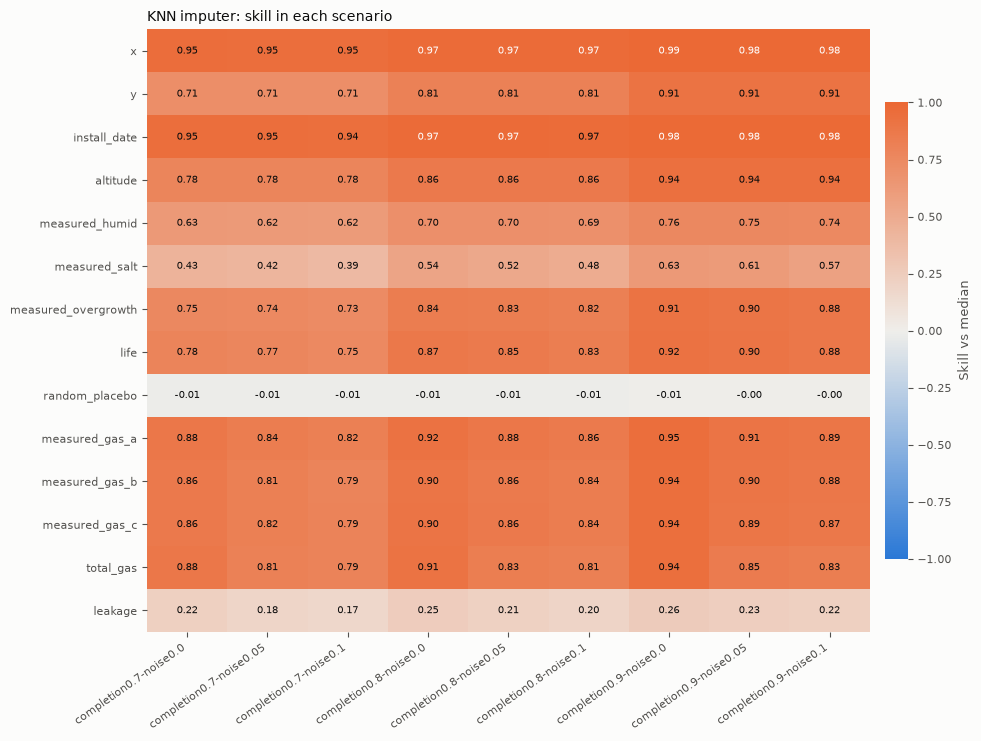

**Figure 4.2.** KNN imputer: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.2c.** KNN imputer: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
KNN imputer,0.9414,0.936,0.8966,0.9832,0.9781,0.945,0.997,0.996,0.9698


**Table 4.2d.** KNN imputer: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,KNN imputer,45,5481.886,6885.535,18.322


In [9]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("KNN")
STUDY.show_model("KNN", "4.2")


### 4.3 IterativeImputer

IterativeImputer (Pedregosa et al., 2011) predicts each numeric column from the others and repeats. Here it uses the ridge alone, with no local model.

**Settings.** Ten passes on scaled columns. Linear terms have a penalty of 30 and second-order terms a penalty of 1,000, because the many second-order terms need stronger shrinkage; without a penalty, near-duplicate columns such as `altitude` and `x + y + 100` make the chain unstable. `model_id` enters as one-hot columns that remain empty when it is missing, so the chain estimates them as well. Estimates are limited to the observed training range.

**Reading the results.** The penalties trade exact recovery of sums for stability. Second-order terms allow the model to represent `life` and the overgrowth threshold. The model does not predict `model_id`, so Table 4.3b gives its fitting time.


Tasks: 175 | saved, skipped: 175 | fitted now: 0


**Table 4.3a.** IterativeImputer: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.7482,1.9776,0.9953,0.0839,0.9699,0.9060,0.9794,0.5894
1,y,5.5323,13.9731,0.7687,-0.1798,0.7815,0.7778,0.8202,0.4904
2,install_date,11.3670,27.3045,0.9953,0.6057,0.9669,0.6158,0.9351,0.0380
3,altitude,5.3307,13.8548,0.8871,-0.1323,0.8426,0.7802,0.8235,0.5932
4,measured_humid,0.0583,0.0863,0.8273,-0.0057,0.6633,0.4370,0.5267,NaN
5,measured_salt,0.1132,0.1600,0.5811,0.0086,0.4655,0.3022,0.4148,NaN
6,measured_overgrowth,0.0584,0.1121,0.9058,-0.0076,0.8059,0.5594,0.6352,NaN
7,life,56.7300,102.6477,0.9289,4.7620,0.8044,0.8749,0.9918,NaN
8,random_placebo,0.2544,0.2925,-0.0122,0.0122,-0.0056,0.0980,0.1512,NaN
9,measured_gas_a,166.0035,295.5291,0.9564,-11.7370,0.8670,0.9501,0.9775,NaN


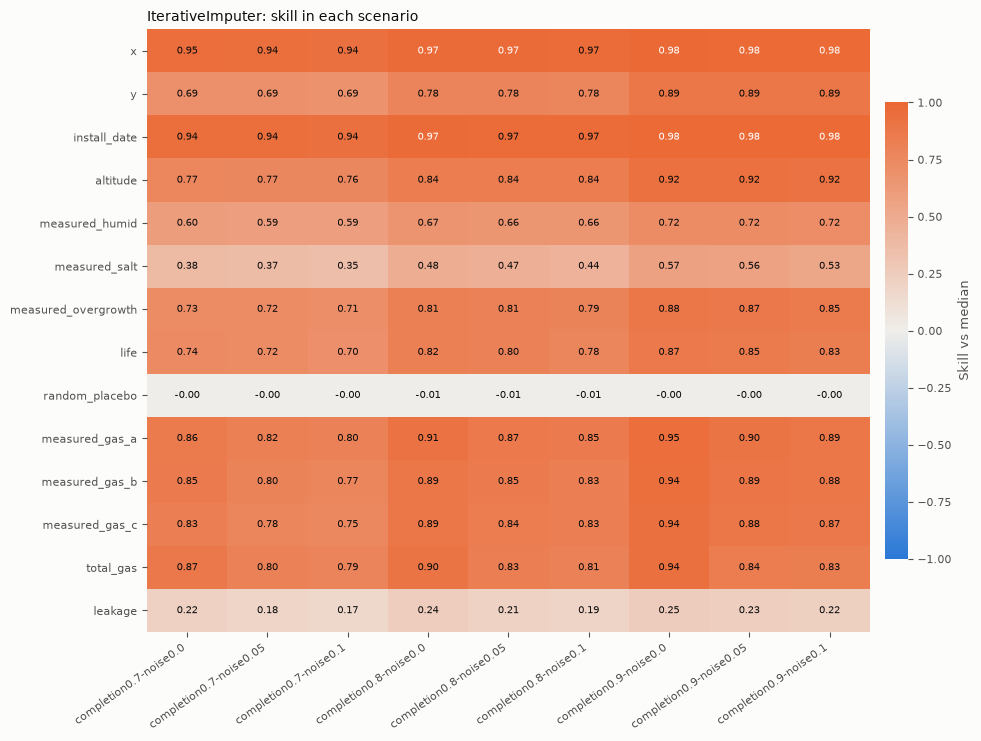

**Figure 4.3.** IterativeImputer: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.3b.** IterativeImputer: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,IterativeImputer,45,406.522,7.795,0.658


In [10]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("IterativeImputer")
STUDY.show_model("IterativeImputer", "4.3")


**Pass limit.** Table 4.3c compares MAE on the same cells at other pass limits; Table 4.3d gives the passes used in each scenario. A fit that stops at the limit has not converged. Ten passes gave the best score during selection.


In [11]:
# MAE on the same cells at other pass limits, and the passes each fit used before stopping.
passes, iterations = STUDY.tables["IterativeImputer"]["passes"]
fg.table("Table 4.3c", f"IterativeImputer: MAE at each pass limit on the same cells, `{REPRESENTATIVE}`.", passes.round(4))
fg.table("Table 4.3d", "IterativeImputer: passes used before stopping, by scenario.", iterations)


**Table 4.3c.** IterativeImputer: MAE at each pass limit on the same cells, `completion0.8-noise0.05`.

,MAE at limit 5,MAE at limit 10,MAE at limit 30
target,,,
x,0.9276,0.7482,0.6854
y,5.6929,5.5323,5.1944
install_date,14.0826,11.3670,10.5342
altitude,5.5206,5.3307,4.9871
measured_humid,0.0572,0.0583,0.0610
measured_salt,0.1113,0.1132,0.1184
measured_overgrowth,0.0586,0.0584,0.0605
life,57.1631,56.7300,57.6034
random_placebo,0.2544,0.2544,0.2544


**Table 4.3d.** IterativeImputer: passes used before stopping, by scenario.

,scenario,fits,fewest iterations,most iterations,fits stopped at the limit
0,completion0.7-noise0.0,5,10,10,5
1,completion0.7-noise0.05,5,10,10,5
2,completion0.7-noise0.1,5,10,10,5
3,completion0.8-noise0.0,5,10,10,5
4,completion0.8-noise0.05,5,10,10,5
5,completion0.8-noise0.1,5,10,10,5
6,completion0.9-noise0.0,5,10,10,5
7,completion0.9-noise0.05,5,10,10,5
8,completion0.9-noise0.1,5,10,10,5


### 4.4 Random Forest

A random forest averages many decision trees, each grown on a sample of the rows (Breiman, 2001). Averaging reduces the variance of single trees, and the trees capture thresholds and interactions without being told about them. Run as a chain, the model follows the MissForest approach (Stekhoven & Bühlmann, 2012).

**Settings.** Four passes with the ridge base and 100 trees per column, each grown on half of the rows, with at least two rows per leaf. `model_id` enters as a number, which the trees can split into its four levels.

**Reading the results.** A forest alone cannot predict outside the range of its training labels; the ridge base can, which matters for sums such as `altitude`.


Tasks: 405 | saved, skipped: 405 | fitted now: 0


**Table 4.4a.** Random Forest: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.5563,1.8495,0.9959,0.0769,0.9776,0.9050,0.9784,0.7643
1,y,4.6348,11.9557,0.8307,-0.4591,0.8169,0.7848,0.8192,0.6747
2,install_date,9.4349,25.9939,0.9957,0.7375,0.9725,0.7795,0.9346,0.0902
3,altitude,4.5510,11.8398,0.9175,-0.3869,0.8656,0.7807,0.8210,0.6872
4,measured_humid,0.0428,0.0725,0.8782,-0.0004,0.7526,0.5927,0.6502,NaN
5,measured_salt,0.0890,0.1367,0.6941,-0.0014,0.5798,0.4133,0.5096,NaN
6,measured_overgrowth,0.0475,0.1015,0.9228,-0.0032,0.8421,0.6582,0.7234,NaN
7,life,35.5349,83.2589,0.9532,-0.5185,0.8775,0.9428,0.9928,NaN
8,random_placebo,0.2572,0.2967,-0.0414,0.0123,-0.0163,0.0940,0.1452,NaN
9,measured_gas_a,143.2088,306.6557,0.9531,-3.6841,0.8852,0.9887,0.9897,NaN


**Table 4.4b.** Random Forest: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,Random Forest,1965,0.9786,0.9774,0.9763


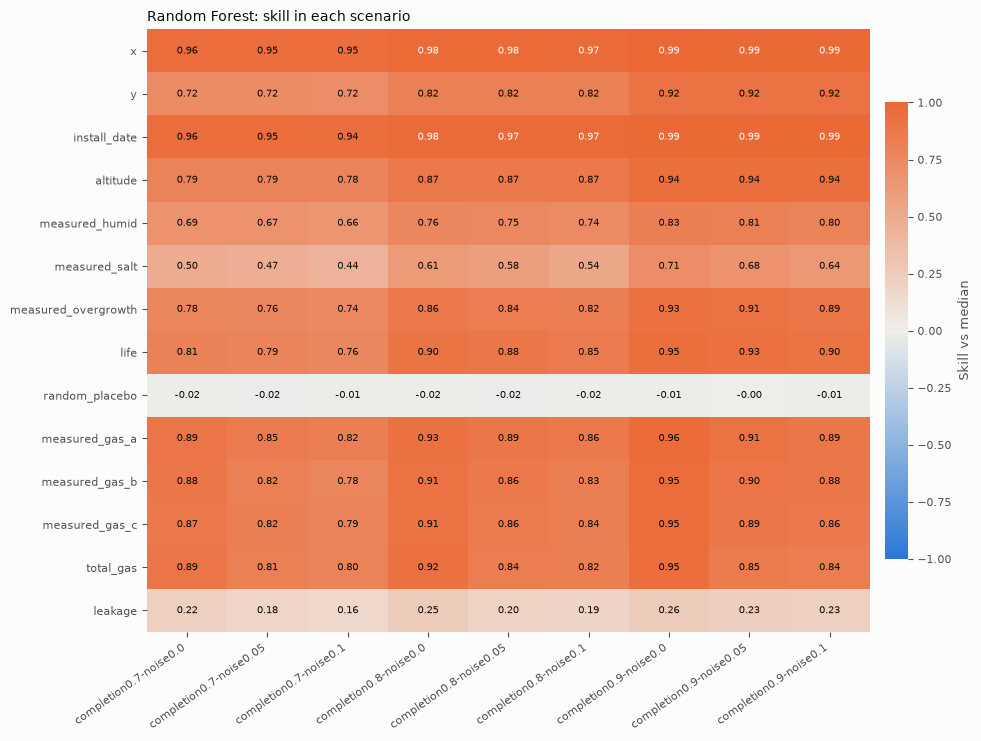

**Figure 4.4.** Random Forest: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.4c.** Random Forest: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Random Forest,0.9693,0.9673,0.937,0.9827,0.9786,0.9588,0.999,0.999,0.9779


**Table 4.4d.** Random Forest: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Random Forest,45,5093.249,67.808,7.646


In [12]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("Random Forest")
STUDY.show_model("Random Forest", "4.4")


**Calibrated probabilities for `model_id`.** A prediction made with probability $p$ should be correct with frequency $p$; the calibration gap measures the difference. Table 4.4e repeats the comparison without the gas columns, because with them the task is too easy to separate the methods. The calibrated model uses the same forest settings and trains on inner folds, so each fit sees fewer rows.


In [13]:
# Probability quality on `model_id`, with and without calibration, with all predictors and without the gas columns.
fg.table("Table 4.4e", "Random Forest: accuracy, log loss, Brier score and calibration gap on `model_id`, "
         "with and without calibrated probabilities.", STUDY.tables["Random Forest"]["probability"].round(4))


**Table 4.4e.** Random Forest: accuracy, log loss, Brier score and calibration gap on `model_id`, with and without calibrated probabilities.

,predictors,method,n,accuracy,log loss,Brier,calibration gap,accuracy of most confident 50%
1,all predictors,Random Forest calibrated,1965,0.9807,0.0457,0.0257,0.0147,1.0000
0,all predictors,Random Forest,1965,0.9786,0.0844,0.0318,0.0468,1.0000
2,without gas columns,Random Forest calibrated,1965,0.7522,0.5654,0.3279,0.0399,0.9420
3,without gas columns,Random Forest,1965,0.7420,0.5825,0.3385,0.0857,0.9511


### 4.5 HistGradientBoosting

Gradient boosting adds trees sequentially, each fitted to the error left by the previous ones (Friedman, 2001). HistGradientBoosting bins each column first, which makes it fast at this data size.

**Settings.** Six passes with the ridge base and trees of up to 31 leaves. In the first pass each split learns a direction for missing values. Each regressor stops adding trees when the error on 15% held-out rows stops falling, so a column without signal receives few trees. `model_id` is a native categorical input.

**Reading the results.** Boosting can fit fine detail and therefore also noise; the result on `random_placebo` shows how far this goes.


Tasks: 170 | saved, skipped: 170 | fitted now: 0


**Table 4.5a.** HistGradientBoosting: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.3744,1.7842,0.9961,0.0317,0.9850,0.9442,0.9869,0.8598
1,y,4.5429,11.9559,0.8306,-0.3197,0.8206,0.7904,0.8217,0.7586
2,install_date,6.9965,24.9085,0.9961,0.3315,0.9796,0.8626,0.9595,0.1211
3,altitude,4.4649,11.8350,0.9176,-0.2929,0.8682,0.7887,0.8265,0.7553
4,measured_humid,0.0424,0.0718,0.8804,-0.0012,0.7547,0.5822,0.6542,NaN
5,measured_salt,0.0886,0.1377,0.6899,0.0000,0.5813,0.4148,0.5132,NaN
6,measured_overgrowth,0.0457,0.1003,0.9245,-0.0018,0.8480,0.6590,0.7395,NaN
7,life,34.8551,84.8244,0.9514,-0.5230,0.8798,0.9428,0.9923,NaN
8,random_placebo,0.2551,0.2934,-0.0183,0.0121,-0.0082,0.0975,0.1437,NaN
9,measured_gas_a,147.5155,339.8389,0.9424,0.0579,0.8818,0.9848,0.9858,NaN


**Table 4.5b.** HistGradientBoosting: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,HistGradientBoosting,1965,0.9807,0.9794,0.9794


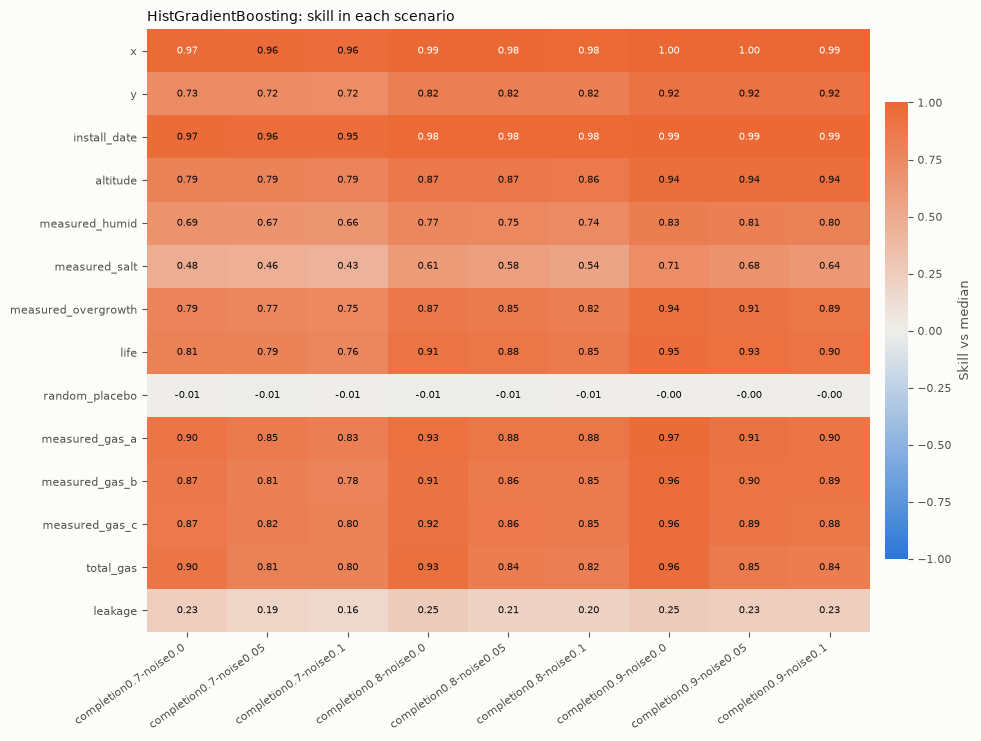

**Figure 4.5.** HistGradientBoosting: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.5c.** HistGradientBoosting: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
HistGradientBoosting,0.9693,0.9666,0.9441,0.9842,0.9807,0.9654,0.999,0.998,0.9869


**Table 4.5d.** HistGradientBoosting: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,HistGradientBoosting,45,2162.817,105.624,3.361


In [14]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("HistGradientBoosting")
STUDY.show_model("HistGradientBoosting", "4.5")


### 4.6 CatBoost

CatBoost (Prokhorenkova et al., 2018) is gradient boosting on symmetric trees, in which all nodes at the same depth share one split. This acts as built-in regularisation.

**Settings.** Six passes with the ridge base and trees of depth four. Each regressor stops when the error on 15% held-out rows has not improved for 30 rounds. Gaps in the first pass are handled natively; `model_id` enters as a number.

**Reading the results.** Comparison with section 4.5 shows the effect of stronger regularisation on noisy columns.


Tasks: 395 | saved, skipped: 395 | fitted now: 0


**Table 4.6a.** CatBoost: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.4040,1.8715,0.9958,0.0402,0.9838,0.9432,0.9809,0.8618
1,y,4.5086,11.8761,0.8329,-0.4116,0.8219,0.7884,0.8263,0.7626
2,install_date,7.2747,26.1964,0.9957,0.3705,0.9788,0.8697,0.9559,0.1257
3,altitude,4.4326,11.7787,0.9184,-0.3690,0.8691,0.7867,0.8294,0.7588
4,measured_humid,0.0425,0.0709,0.8834,-0.0017,0.7544,0.5801,0.6396,NaN
5,measured_salt,0.0911,0.1389,0.6845,-0.0001,0.5699,0.3813,0.4975,NaN
6,measured_overgrowth,0.0452,0.0982,0.9277,-0.0013,0.8497,0.6682,0.7356,NaN
7,life,35.3955,84.4147,0.9519,-2.8122,0.8780,0.9408,0.9923,NaN
8,random_placebo,0.2546,0.2929,-0.0148,0.0122,-0.0062,0.0975,0.1497,NaN
9,measured_gas_a,150.0260,347.3600,0.9398,2.7732,0.8798,0.9853,0.9863,NaN


**Table 4.6b.** CatBoost: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,CatBoost,1965,0.9791,0.9778,0.9778


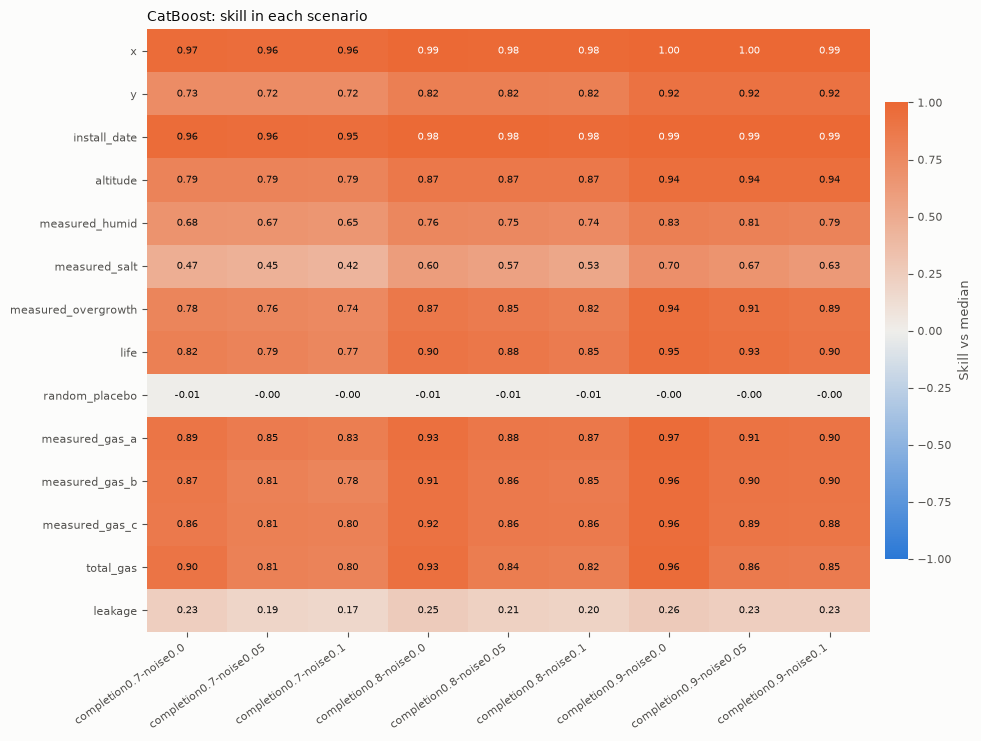

**Figure 4.6.** CatBoost: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.6c.** CatBoost: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
CatBoost,0.9666,0.9626,0.935,0.9837,0.9791,0.9598,0.999,0.999,0.9839


**Table 4.6d.** CatBoost: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,CatBoost,45,4610.365,14.826,6.852


In [15]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("CatBoost")
STUDY.show_model("CatBoost", "4.6")


### 4.7 miceforest direct

miceforest runs chained equations with LightGBM gradient boosting (Ke et al., 2017). This section uses its predictions directly, without donor matching and without the ridge base. An audited compatibility patch for miceforest 6.0.5 is applied.

**Settings.** Three passes of 200 boosting rounds, each tree using 70% of the columns. Two defaults are changed: the chain starts from the gaps instead of random values, which would feed the first models with noise, and it runs true gradient boosting instead of a depth-limited random forest that ignores the learning rate.

**Reading the results.** The model shares nothing with the ridge base, so it shows what a boosted chain reaches without it.


Tasks: 90 | saved, skipped: 90 | fitted now: 0


**Table 4.7a.** miceforest direct: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.1643,2.6869,0.9913,0.1492,0.9532,0.8271,0.9417,0.5452
1,y,5.4485,11.9258,0.8315,-0.4030,0.7848,0.5197,0.8162,0.2020
2,install_date,17.5058,38.8466,0.9904,0.7577,0.9490,0.5884,0.8642,0.0578
3,altitude,5.1308,11.6613,0.9200,-0.1641,0.8485,0.6315,0.8180,0.2576
4,measured_humid,0.0481,0.0758,0.8667,0.0009,0.7217,0.5353,0.6124,NaN
5,measured_salt,0.0954,0.1413,0.6736,0.0041,0.5493,0.3864,0.4944,NaN
6,measured_overgrowth,0.0562,0.1080,0.9125,0.0040,0.8132,0.5747,0.6613,NaN
7,life,44.3172,88.4735,0.9472,-0.2024,0.8472,0.9127,0.9934,NaN
8,random_placebo,0.2557,0.2959,-0.0355,0.0127,-0.0105,0.1064,0.1492,NaN
9,measured_gas_a,143.1308,277.8758,0.9615,-17.6410,0.8853,0.9824,0.9863,NaN


**Table 4.7b.** miceforest direct: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
4,miceforest direct,1965,0.9837,0.9827,0.9828


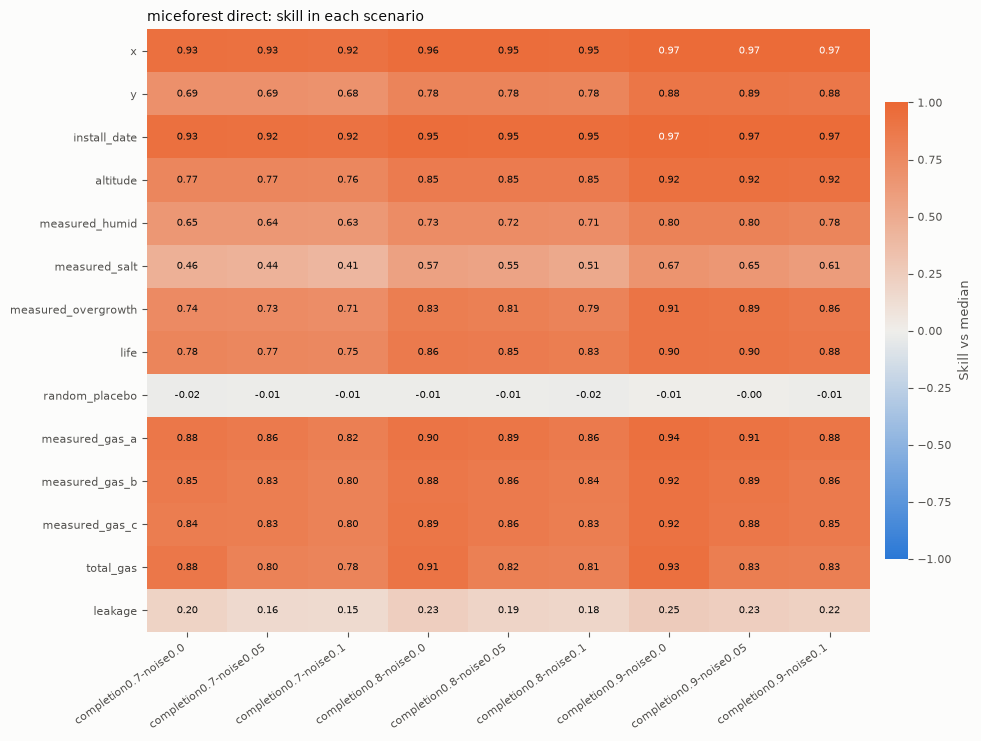

**Figure 4.7.** miceforest direct: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.7c.** miceforest direct: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
miceforest direct,0.9683,0.967,0.9434,0.9842,0.9837,0.9659,0.999,0.997,0.9849


**Table 4.7d.** miceforest direct: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,miceforest direct,45,494.353,24.549,0.769


In [16]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("miceforest direct")
STUDY.show_model("miceforest direct", "4.7")


### 4.8 Gaussian mixture model (GMM)

The GMM treats each row as drawn from one of $K$ multivariate normal components, each with its own mean $\mu_k$ and all sharing one covariance $\Sigma$. It is fitted by expectation–maximisation on incomplete rows (Dempster et al., 1977; Ghahramani & Jordan, 1994), using only the cells each row shows. With $o$ the visible and $h$ the hidden cells of a row, the estimate is the conditional mean averaged over components by their posterior probabilities $\pi_k(x_o)$:

$$\hat{x}_h = \sum_{k=1}^{K} \pi_k(x_o)\left[\mu_{k,h} + \Sigma_{ho}\,\Sigma_{oo}^{-1}\,(x_o - \mu_{k,o})\right].$$

`model_id` enters as one-hot columns, and its class probabilities follow from the component weights.

**Settings.** Six components, eight EM iterations, a covariance penalty of 0.001 and a weight of 1.8 on the `model_id` columns (section 3.3). Numeric columns are centred on the training median and scaled by the training spread. The source code's gas-decay feature is switched off, because it is built from the generator's gas formula.

**Reading the results.** Within one component the estimate is linear in the visible cells, so thresholds and products are approximated by the mixture of components.


Tasks: 165 | saved, skipped: 165 | fitted now: 0


**Table 4.8a.** GMM: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.4382,1.8406,0.9959,0.0894,0.9824,0.9417,0.9744,0.8623
1,y,4.6475,11.9219,0.8316,-0.0646,0.8164,0.7828,0.8187,0.7510
2,install_date,8.2103,26.3426,0.9956,1.1004,0.9761,0.8662,0.9478,0.1049
3,altitude,4.5221,11.7456,0.9189,0.0239,0.8665,0.7832,0.8220,0.7583
4,measured_humid,0.0669,0.0915,0.8057,-0.0001,0.6135,0.3589,0.4884,NaN
5,measured_salt,0.1265,0.1665,0.5466,0.0018,0.4027,0.2404,0.3352,NaN
6,measured_overgrowth,0.0824,0.1240,0.8846,0.0145,0.7262,0.3778,0.4973,NaN
7,life,116.0269,157.6004,0.8323,0.2950,0.6000,0.5536,0.9877,NaN
8,random_placebo,0.2538,0.2919,-0.0079,0.0121,-0.0032,0.1000,0.1512,NaN
9,measured_gas_a,134.2475,267.6916,0.9642,-6.3673,0.8924,0.9790,0.9873,NaN


**Table 4.8b.** GMM: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,GMM,1965,0.9842,0.9832,0.9831


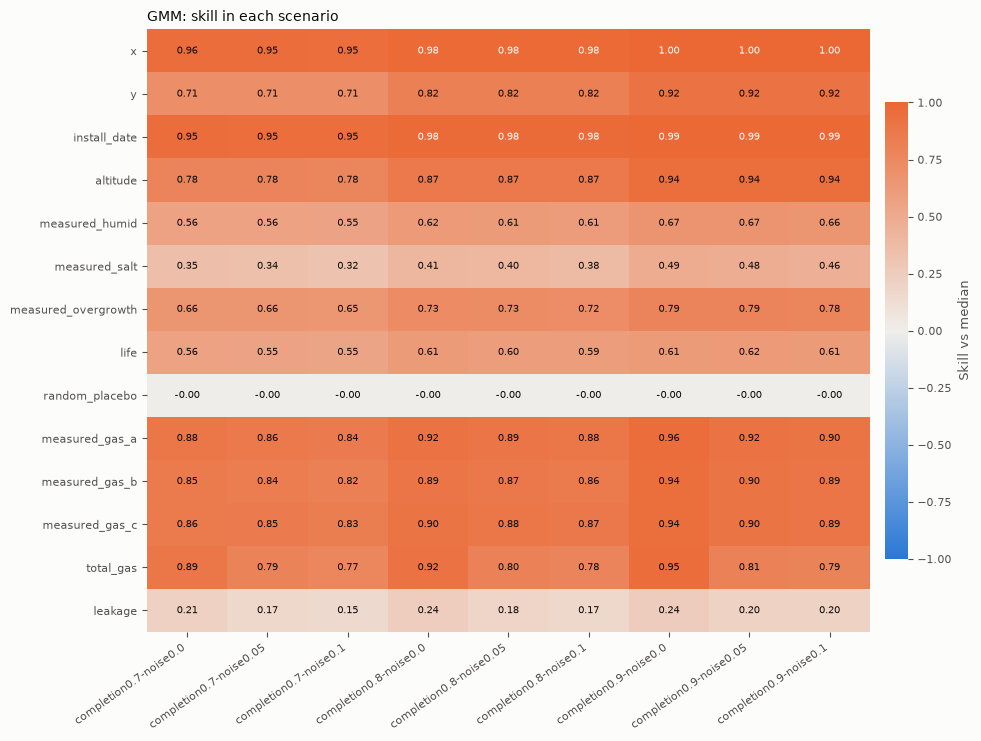

**Figure 4.8.** GMM: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.8c.** GMM: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
GMM,0.9741,0.9707,0.942,0.9878,0.9842,0.9634,0.999,0.999,0.9839


**Table 4.8d.** GMM: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,GMM,45,74.998,3.647,0.117


In [17]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("GMM")
STUDY.show_model("GMM", "4.8")


### 4.9 Masked MLP

A neural network learns to reconstruct cells. In each training pass a share of the visible training cells is hidden, and the network learns to predict them from the rest, following the ReMasker design (Du et al., 2024). Columns enter standardised, with gaps set to the training median and a missing-value indicator beside each; `model_id` enters as one-hot columns. The network returns a value and a scale for each numeric column and class probabilities for `model_id`.

**Settings.** Hidden layers of 256 and 128 units, 60 training passes, a learning rate of 0.0015, 40% of visible cells hidden per pass and no dropout (section 3.3). The source code's exact-formula step and its blanking of the placebo column are switched off, because both use knowledge of the generator.

**Reading the results.** The selection score was still improving when selection stopped, so these settings are not necessarily the network's best.


Tasks: 165 | saved, skipped: 165 | fitted now: 0


**Table 4.9a.** Masked MLP: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.7588,3.4394,0.9857,-0.1960,0.9293,0.7035,0.9206,0.3116
1,y,6.3778,12.7427,0.8076,0.1616,0.7481,0.3758,0.7874,0.1419
2,install_date,24.6589,47.1802,0.9859,4.8931,0.9282,0.3477,0.8206,0.0274
3,altitude,6.2447,12.6751,0.9055,0.3481,0.8156,0.4048,0.7971,0.1462
4,measured_humid,0.0630,0.0873,0.8231,-0.0059,0.6360,0.3997,0.4929,NaN
5,measured_salt,0.1453,0.1794,0.4733,-0.0011,0.3138,0.1775,0.2591,NaN
6,measured_overgrowth,0.0753,0.1201,0.8918,0.0017,0.7497,0.3877,0.5004,NaN
7,life,69.1399,105.7357,0.9245,-9.9295,0.7616,0.8049,0.9923,NaN
8,random_placebo,0.2551,0.2936,-0.0197,0.0117,-0.0081,0.0965,0.1407,NaN
9,measured_gas_a,200.6862,321.9769,0.9483,-5.8638,0.8392,0.9398,0.9804,NaN


**Table 4.9b.** Masked MLP: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,Masked MLP,1965,0.9832,0.9823,0.9827


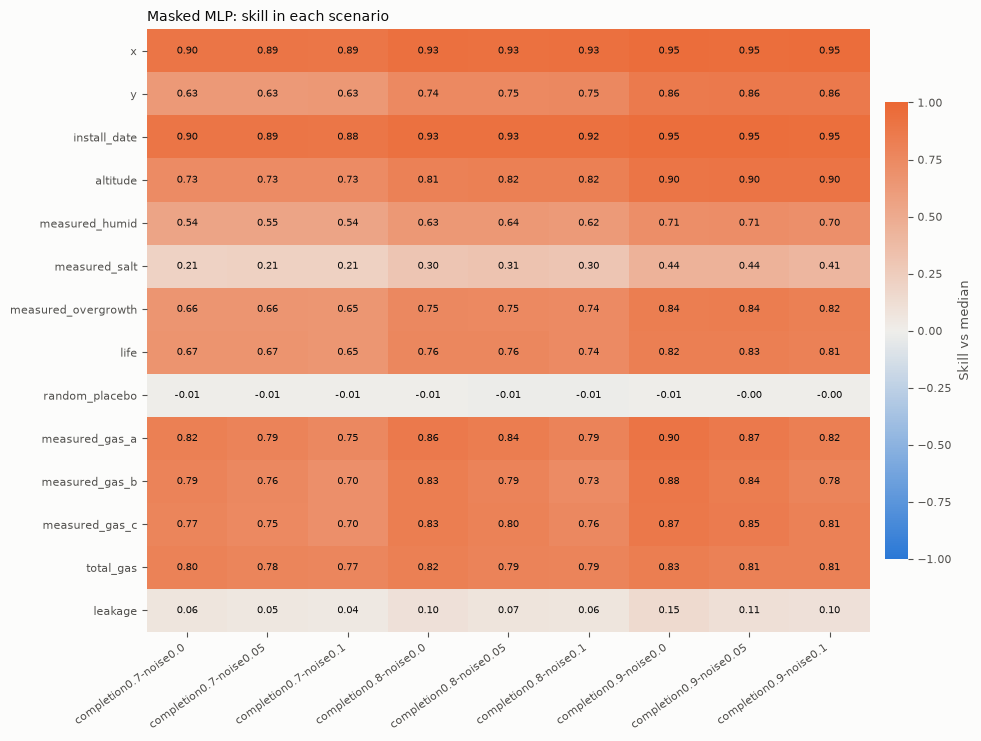

**Figure 4.9.** Masked MLP: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.9c.** Masked MLP: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Masked MLP,0.97,0.966,0.9333,0.9858,0.9832,0.9562,0.999,0.998,0.9809


**Table 4.9d.** Masked MLP: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Masked MLP,45,378.573,0.908,0.562


In [18]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("Masked MLP")
STUDY.show_model("Masked MLP", "4.9")


### 4.10 LightGBM chained

The chain first fills gaps with the training median and mode. In each of three passes it fits one LightGBM model (Ke et al., 2017) per column on the rows where that column is observed and replaces the column's gaps with its predictions. The stored models are replayed on new rows in the same order.

**Settings.** 100 trees per model, a learning rate of 0.07 and 31 leaves, as documented. `model_id` is a categorical input.

**Reading the results.** Section 4.7 runs another LightGBM chain; this one starts from the median and uses fewer rounds. Neither has the ridge base.


Tasks: 165 | saved, skipped: 165 | fitted now: 0


**Table 4.10a.** LightGBM chained: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.0578,3.1472,0.9880,0.1683,0.9575,0.8367,0.9307,0.8050
1,y,5.1621,12.0595,0.8277,-0.4601,0.7961,0.6773,0.8202,0.3040
2,install_date,15.2331,43.2380,0.9882,2.2276,0.9556,0.8094,0.8571,0.3077
3,altitude,5.0124,11.9093,0.9166,-0.3968,0.8520,0.6942,0.8210,0.3227
4,measured_humid,0.0491,0.0793,0.8543,0.0002,0.7162,0.5454,0.6119,NaN
5,measured_salt,0.0941,0.1412,0.6737,0.0070,0.5557,0.3945,0.5010,NaN
6,measured_overgrowth,0.0563,0.1135,0.9033,-0.0131,0.8130,0.5670,0.6437,NaN
7,life,45.9584,93.8704,0.9405,1.4629,0.8415,0.9086,0.9908,NaN
8,random_placebo,0.2561,0.2959,-0.0352,0.0133,-0.0120,0.0920,0.1532,NaN
9,measured_gas_a,144.8023,303.5807,0.9540,-19.1390,0.8840,0.9829,0.9829,NaN


**Table 4.10b.** LightGBM chained: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,LightGBM chained,1965,0.9766,0.9762,0.974


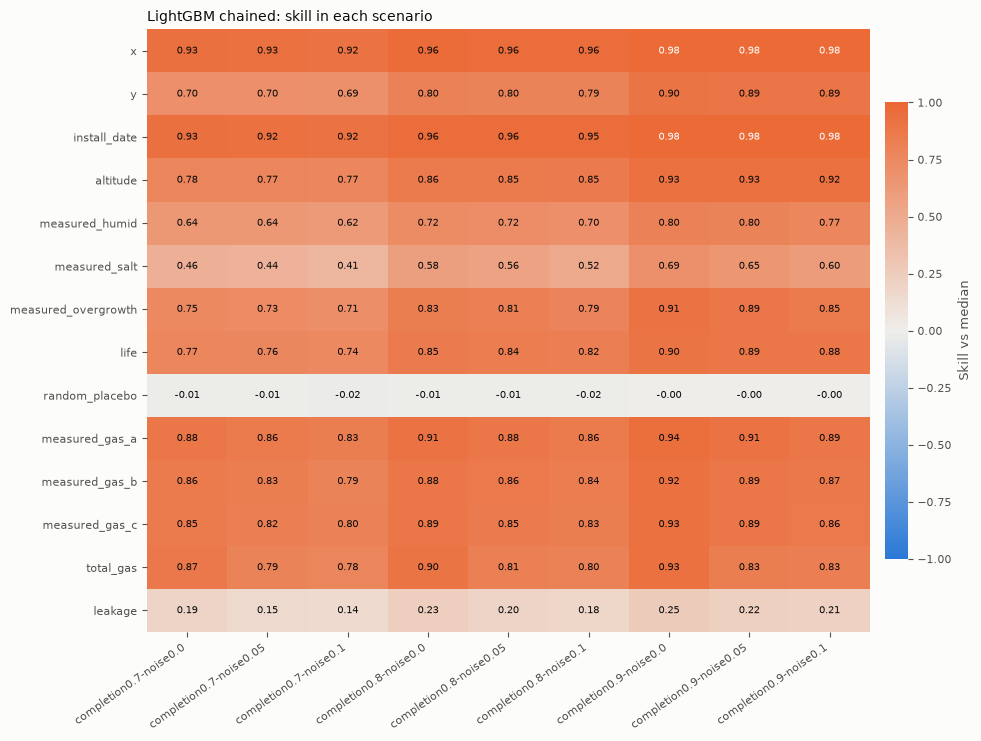

**Figure 4.10.** LightGBM chained: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.10c.** LightGBM chained: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
LightGBM chained,0.9693,0.9609,0.9454,0.9802,0.9766,0.9598,0.998,0.996,0.9819


**Table 4.10d.** LightGBM chained: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,LightGBM chained,45,281.725,13.346,0.437


In [19]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("LightGBM chained")
STUDY.show_model("LightGBM chained", "4.10")


### 4.11 Predictive MissForest

A chain of random forests in the MissForest style (Stekhoven & Bühlmann, 2012). Gaps start from the training mean and mode. In each of five passes one forest per column is fitted on the rows where that column is observed, and its predictions replace the gaps. Every forest is stored, so the passes can be replayed on new rows without refitting.

**Settings.** 100 trees, at least 10 rows per leaf and the square root of the predictors at each split, as documented.

**Reading the results.** Section 4.4 is also a forest chain, with the ridge base and other forest settings; section 8.5 includes that chain without the ridge.


Tasks: 165 | saved, skipped: 165 | fitted now: 0


**Table 4.11a.** Predictive MissForest: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.9704,3.2427,0.9873,0.1372,0.9208,0.5874,0.9231,0.2472
1,y,8.5980,13.6987,0.7777,-0.4747,0.6604,0.1667,0.5308,0.0515
2,install_date,27.1348,44.4691,0.9875,0.6564,0.9210,0.2681,0.7253,0.0203
3,altitude,8.1730,13.5785,0.8915,-0.3521,0.7587,0.2019,0.5803,0.0661
4,measured_humid,0.0642,0.0872,0.8238,0.0009,0.6289,0.3705,0.4970,NaN
5,measured_salt,0.1295,0.1646,0.5570,0.0022,0.3884,0.2181,0.3185,NaN
6,measured_overgrowth,0.0759,0.1222,0.8881,-0.0012,0.7477,0.4161,0.5494,NaN
7,life,62.6723,108.4424,0.9206,1.6930,0.7839,0.8407,0.9908,NaN
8,random_placebo,0.2545,0.2938,-0.0209,0.0120,-0.0059,0.1039,0.1522,NaN
9,measured_gas_a,140.9008,301.8989,0.9545,-3.3395,0.8871,0.9887,0.9897,NaN


**Table 4.11b.** Predictive MissForest: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,Predictive MissForest,1965,0.9817,0.9807,0.9796


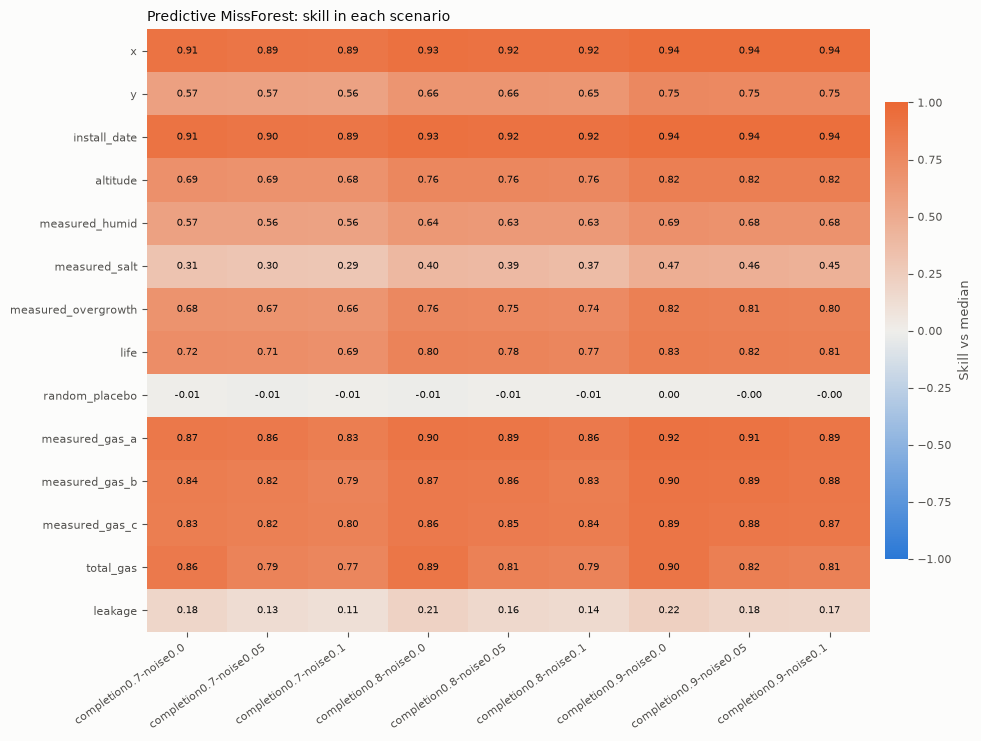

**Figure 4.11.** Predictive MissForest: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.11c.** Predictive MissForest: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Predictive MissForest,0.969,0.966,0.939,0.9842,0.9817,0.9573,0.999,0.999,0.9819


**Table 4.11d.** Predictive MissForest: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Predictive MissForest,45,2243.807,54.945,3.406


In [20]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("Predictive MissForest")
STUDY.show_model("Predictive MissForest", "4.11")


### 4.12 MICE with predictive mean matching (MICE-PMM)

Multivariate imputation by chained equations (van Buuren & Groothuis-Oudshoorn, 2011). Gaps start from values drawn at random from the same column, and in each sweep every column is fitted in turn on the current values of the others. Numeric columns use predictive mean matching (Little, 1988): a lightly penalised Bayesian linear model predicts each gap, and the gap takes the observed value of one of the five rows with the closest predictions. `model_id` uses a logistic regression fitted on a bootstrap sample of the observed rows, and its label is drawn from the predicted probabilities. Five independent chains run ten sweeps each.

**Settings.** Five chains, ten sweeps, five donors, a penalty of 0.0001 on the linear model, and logistic regression with C = 1 and up to 500 iterations, as documented. The source code completes a whole table, so its models would see the visible cells of the rows being scored; here every model, scaler and encoder is fitted on training rows only, and donors come from training rows only. The fitting and drawing steps are unchanged. The estimate is the mean of the five chains for numeric columns and the share of chains choosing each class for `model_id`.

**Reading the results.** Each chain copies an observed value, so a single chain keeps the spread of a column, while the mean of five chains narrows it. The model's own documentation reports it below the median on the placebo in every scenario.


Tasks: 165 | saved, skipped: 165 | fitted now: 0


**Table 4.12a.** MICE-PMM: error and skill on each numeric column, `completion0.8-noise0.05`.

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.8085,4.9658,0.9701,0.2879,0.9273,0.8201,0.8683,0.8030
1,y,6.0677,13.2320,0.7926,-0.0939,0.7603,0.5126,0.8015,0.1995
2,install_date,26.3664,70.2568,0.9687,3.9366,0.9232,0.8049,0.8267,0.3426
3,altitude,6.1865,13.6348,0.8906,0.0283,0.8174,0.5306,0.7986,0.2108
4,measured_humid,0.0734,0.0990,0.7725,-0.0032,0.5757,0.3185,0.4385,NaN
5,measured_salt,0.1403,0.1889,0.4162,0.0052,0.3376,0.2216,0.3174,NaN
6,measured_overgrowth,0.0768,0.1328,0.8676,-0.0060,0.7446,0.3678,0.4912,NaN
7,life,139.1155,184.8681,0.7693,-0.3143,0.5204,0.4663,0.9883,NaN
8,random_placebo,0.2656,0.3131,-0.1597,0.0087,-0.0495,0.0990,0.1477,NaN
9,measured_gas_a,192.6207,332.5989,0.9448,-6.4752,0.8456,0.9520,0.9755,NaN


**Table 4.12b.** MICE-PMM: accuracy, macro F1 and balanced accuracy on `model_id`, `completion0.8-noise0.05`.

,method,n,accuracy,macro F1,balanced accuracy
9,MICE-PMM,1965,0.9761,0.9747,0.9743


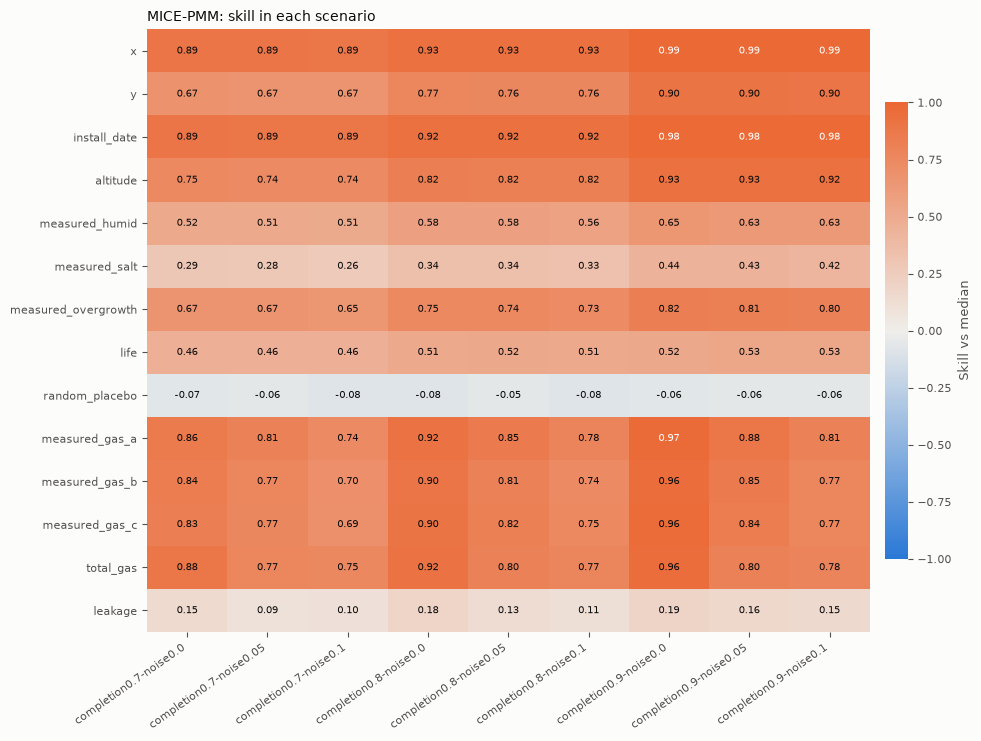

**Figure 4.12.** MICE-PMM: skill on each numeric column in each of the nine generator scenarios (0 equals the baseline, 1 is exact recovery).

**Table 4.12c.** MICE-PMM: accuracy on `model_id` in each generator scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
MICE-PMM,0.9501,0.9508,0.9272,0.9776,0.9761,0.9593,0.996,0.997,0.9819


**Table 4.12d.** MICE-PMM: tasks and fitting time in the main experiment.

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,MICE-PMM,45,0.039,832.978,1.234


In [21]:
# Fit the model's tasks, or read them when saved, then show its results in the representative scenario.
STUDY.run_model("MICE-PMM")
STUDY.show_model("MICE-PMM", "4.12")


## 5. Overview of results

Chapters 5 to 9 and the appendix use saved predictions only and fit no model. The next cell combines the results of all models and builds the evaluation tables, or reads them from the run folder when they were built before from the same code and tasks. This chapter compares all models with the baseline; chapters 6 to 9 compare the two main models, Random Forest and GMM, with the baseline, and views of a single model are shown for each main model, labelled a for Random Forest and b for GMM.


In [22]:
# Combine every model's saved results; the evaluation tables are read from the run folder, or built once.
STUDY.finish()
NUMERIC, CATEGORY, PAIRS, FIGURES = STUDY.numeric, STUDY.category, STUDY.pairs, STUDY.figures
MAIN, SHOWN = list(STUDY.main), list(fl.SHOWN_METHODS)
COMPARED = ["Median"] + MAIN                                          # the baseline and the main models
FILE = {method: method.lower().replace(" ", "_") for method in MAIN}  # figure file names
LETTER = dict(zip(MAIN, "ab"))                                        # Random Forest: a, GMM: b
print("Main models compared with the baseline:", ", ".join(MAIN))


Evaluation tables: read from the run folder
Main models compared with the baseline: Random Forest, GMM


### 5.1 Failure criterion

A model is assessed by its skill (section 3.4): the share of the baseline's error it removes on the same cells.

| State | Skill | Meaning |
|---|---|---|
| works | 0.5 or more | Removes at least half of the baseline's error |
| weak | 0.1 to 0.5 | Removes less than half |
| fails | below 0.1 | Adds almost nothing to the baseline |

Tolerance limits (section 2.2) are not used as the criterion, because the share within a limit depends on a column's range, and on a narrow column the baseline can already meet the limit. Table 5.1 reports both measures for the main models and the baseline.


In [23]:
# Share within the loose tolerance and skill on each numeric column, for the baseline and the main models.
standard = STUDY.standard
table = standard.pivot(index="target", columns="method", values="within").reindex(list(NUMERIC_TARGETS))[COMPARED]
table.columns = [f"within loose tolerance: {c}" for c in table.columns]
for method in MAIN:
    table[f"skill: {method}"] = standard[standard.method.eq(method)].set_index("target").skill
fg.table("Table 5.1", f"Share of hidden cells within the loose tolerance, and skill, by numeric column, `{REPRESENTATIVE}`.",
         table.round(3))


**Table 5.1.** Share of hidden cells within the loose tolerance, and skill, by numeric column, `completion0.8-noise0.05`.

,within loose tolerance: Median,within loose tolerance: Random Forest,within loose tolerance: GMM,skill: Random Forest,skill: GMM
target,,,,,
x,0.109,0.978,0.974,0.978,0.982
y,0.101,0.819,0.819,0.817,0.816
install_date,0.047,0.935,0.948,0.973,0.976
altitude,0.093,0.821,0.822,0.866,0.867
measured_humid,0.156,0.650,0.488,0.753,0.614
measured_salt,0.150,0.510,0.335,0.580,0.403
measured_overgrowth,0.072,0.723,0.497,0.842,0.726
life,0.830,0.993,0.988,0.877,0.600
random_placebo,0.150,0.145,0.151,-0.016,-0.003


### 5.2 Overall performance

Figure 5.2 shows the skill of every model on every column in the representative scenario; the shaded band marks the failing range and the vertical line the baseline. Table 5.2 adds the kind of relationship that defines each column and the baseline's error in the column's unit.


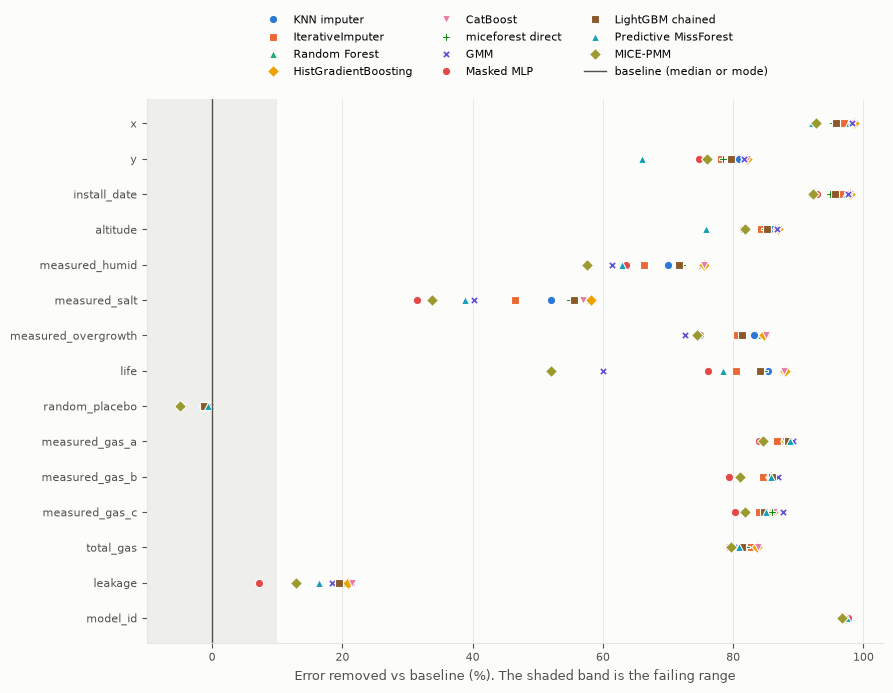

**Figure 5.2.** Skill of every model on every column, `completion0.8-noise0.05`. The shaded band is the failing range (skill below 0.1); the vertical line is the baseline.

**Table 5.2.** Skill of every model on every column, with the kind of relationship and the baseline's MAE.

method,kind of relationship,baseline error,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct,GMM,Masked MLP,LightGBM chained,Predictive MissForest,MICE-PMM
target,,,,,,,,,,,,,
x,near copy of another column,24.888,0.973,0.970,0.978,0.985,0.984,0.953,0.982,0.929,0.957,0.921,0.927
y,exact sum,25.319,0.809,0.781,0.817,0.821,0.822,0.785,0.816,0.748,0.796,0.660,0.760
install_date,near copy of another column,343.332,0.969,0.967,0.973,0.980,0.979,0.949,0.976,0.928,0.956,0.921,0.923
altitude,exact sum,33.874,0.861,0.843,0.866,0.868,0.869,0.849,0.867,0.816,0.852,0.759,0.817
measured_humid,random draw scaled by another column,0.173,0.700,0.663,0.753,0.755,0.754,0.722,0.614,0.636,0.716,0.629,0.576
measured_salt,random draw scaled by another column,0.212,0.520,0.466,0.580,0.581,0.570,0.549,0.403,0.314,0.556,0.388,0.338
measured_overgrowth,threshold,0.301,0.832,0.806,0.842,0.848,0.850,0.813,0.726,0.750,0.813,0.748,0.745
life,product that depends on the model,290.044,0.854,0.804,0.877,0.880,0.878,0.847,0.600,0.762,0.842,0.784,0.520
random_placebo,no relationship,0.253,-0.013,-0.006,-0.016,-0.008,-0.006,-0.010,-0.003,-0.008,-0.012,-0.006,-0.049


In [24]:
# Skill of every model on every column in the representative scenario.
fg.plot_overall(STUDY.overall, SHOWN, FIGURES)
fg.caption("Figure 5.2", f"Skill of every model on every column, `{REPRESENTATIVE}`. The shaded band is the failing range "
           "(skill below 0.1); the vertical line is the baseline.")
with pd.option_context("display.max_colwidth", 60):
    fg.table("Table 5.2", "Skill of every model on every column, with the kind of relationship and the baseline's MAE.",
             STUDY.overall.round(3))


### 5.3 Condition map: main models

Each column of the map changes one condition relative to the representative scenario. Figures 5.3a and 5.3b give the skill of each main model, with bold values below 0.5; Tables 5.3a and 5.3b classify every value by the criterion of section 5.1.

- **highest noise**, **lowest completion**, **both together:** other generator scenarios.
- **few linked columns visible:** cells of the representative scenario whose row shows at most a third of the directly linked columns.
- **older assets hidden more**, **higher values hidden more**, **related columns hidden together**, **wrong recorded values**, **completion 0.5**, **completion 0.3:** the scenarios of section 2.5.
- **held out by location:** the representative scenario with folds of whole blocks of the grid.
- **most harmful block removed:** the lowest skill after one block of predictors is removed and the model refitted.

Chapters 6 to 8 examine these conditions in turn.


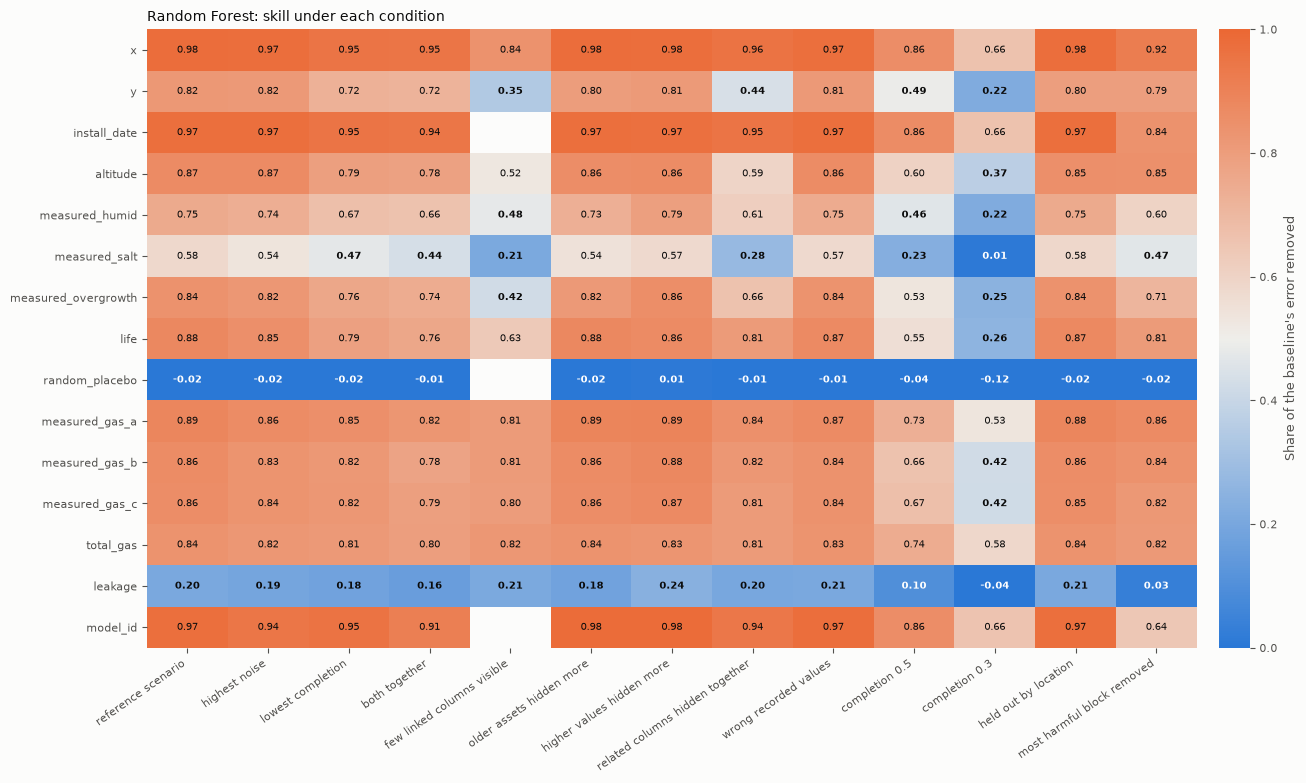

**Figure 5.3a.** Random Forest: skill on each column under each condition; bold values are below 0.5.

**Table 5.3a.** Random Forest: state of each value of Figure 5.3a (works, weak or fails).

,reference scenario,highest noise,lowest completion,both together,few linked columns visible,older assets hidden more,higher values hidden more,related columns hidden together,wrong recorded values,completion 0.5,completion 0.3,held out by location,most harmful block removed
target,,,,,,,,,,,,,
x,works,works,works,works,works,works,works,works,works,works,works,works,works
y,works,works,works,works,weak,works,works,weak,works,weak,weak,works,works
install_date,works,works,works,works,not measured,works,works,works,works,works,works,works,works
altitude,works,works,works,works,works,works,works,works,works,works,weak,works,works
measured_humid,works,works,works,works,weak,works,works,works,works,weak,weak,works,works
measured_salt,works,works,weak,weak,weak,works,works,weak,works,weak,fails,works,weak
measured_overgrowth,works,works,works,works,weak,works,works,works,works,works,weak,works,works
life,works,works,works,works,works,works,works,works,works,works,weak,works,works
random_placebo,fails,fails,fails,fails,not measured,fails,fails,fails,fails,fails,fails,fails,fails


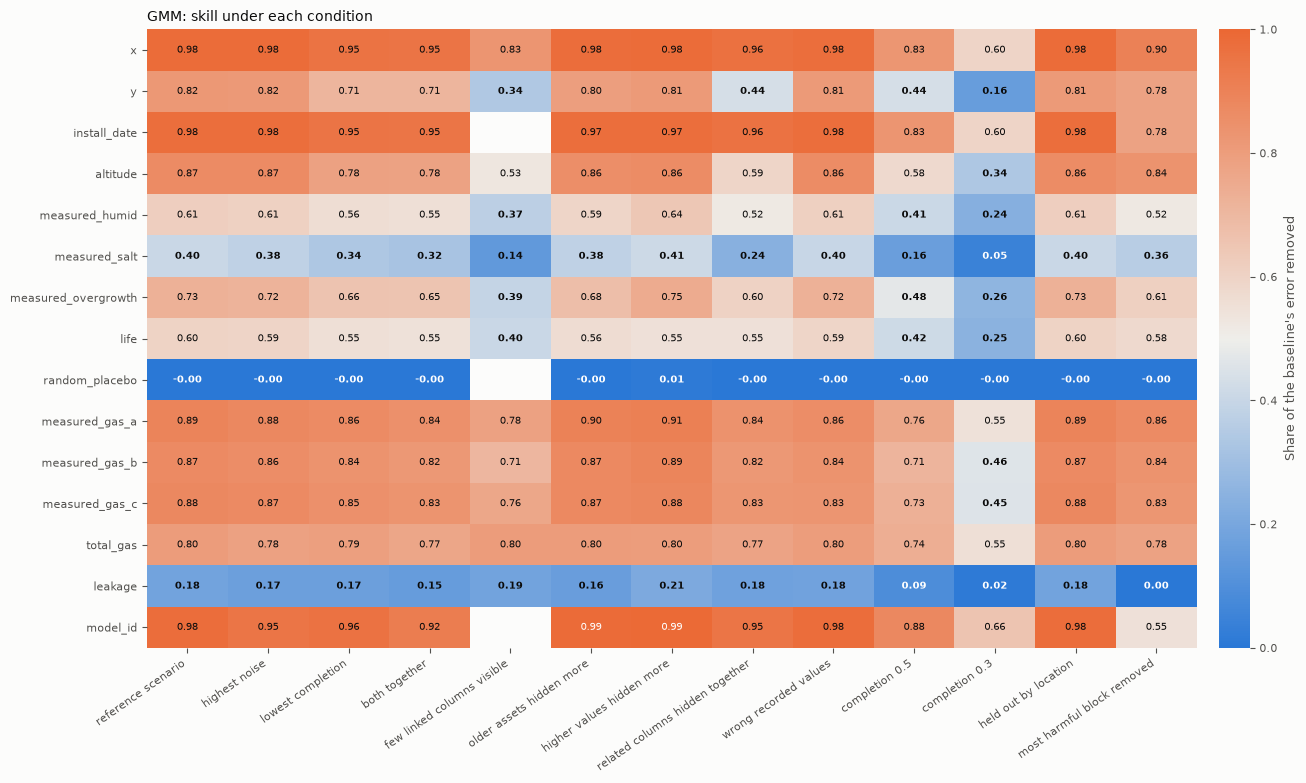

**Figure 5.3b.** GMM: skill on each column under each condition; bold values are below 0.5.

**Table 5.3b.** GMM: state of each value of Figure 5.3b (works, weak or fails).

,reference scenario,highest noise,lowest completion,both together,few linked columns visible,older assets hidden more,higher values hidden more,related columns hidden together,wrong recorded values,completion 0.5,completion 0.3,held out by location,most harmful block removed
target,,,,,,,,,,,,,
x,works,works,works,works,works,works,works,works,works,works,works,works,works
y,works,works,works,works,weak,works,works,weak,works,weak,weak,works,works
install_date,works,works,works,works,not measured,works,works,works,works,works,works,works,works
altitude,works,works,works,works,works,works,works,works,works,works,weak,works,works
measured_humid,works,works,works,works,weak,works,works,works,works,weak,weak,works,works
measured_salt,weak,weak,weak,weak,weak,weak,weak,weak,weak,weak,fails,weak,weak
measured_overgrowth,works,works,works,works,weak,works,works,works,works,weak,weak,works,works
life,works,works,works,works,weak,works,works,works,works,weak,weak,works,works
random_placebo,fails,fails,fails,fails,not measured,fails,fails,fails,fails,fails,fails,fails,fails


In [25]:
# Skill of each main model under each condition, and its state under the failure criterion.
for method in MAIN:
    label = f"5.3{LETTER[method]}"
    fg.plot_failure_map(STUDY.failure_maps[method], f"{method}: skill under each condition", FIGURES,
                        f"failure_map_{FILE[method]}", fl.WEAK)
    fg.caption(f"Figure {label}", f"{method}: skill on each column under each condition; bold values are below 0.5.")
    fg.table(f"Table {label}", f"{method}: state of each value of Figure {label} (works, weak or fails).",
             STUDY.failure_maps[method].apply(lambda column: column.map(fl.state)))


### 5.4 Condition map: all models

Figure 5.4 repeats section 5.3 for every model. Each value is the mean skill over the columns with a relationship, so one cell summarises one model under one condition; bold values are below 0.5. Table 5.4 adds each model's group. The removed-block column is empty for miceforest direct, which is not refitted without predictor blocks.


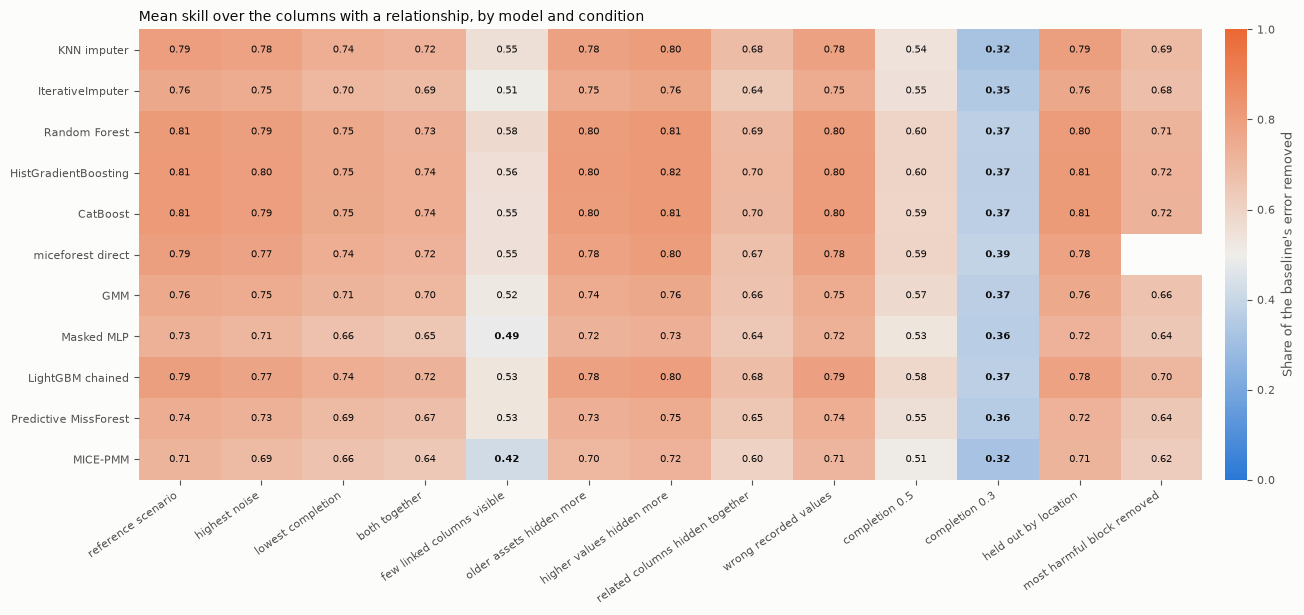

**Figure 5.4.** Mean skill over the columns with a relationship, by model and condition; bold values are below 0.5.

**Table 5.4.** Values of Figure 5.4 with the group of each model.

,group,reference scenario,highest noise,lowest completion,both together,few linked columns visible,older assets hidden more,higher values hidden more,related columns hidden together,wrong recorded values,completion 0.5,completion 0.3,held out by location,most harmful block removed
KNN imputer,"chained, selected settings",0.795,0.778,0.737,0.719,0.551,0.781,0.798,0.684,0.783,0.542,0.321,0.793,0.690
IterativeImputer,"chained, selected settings",0.760,0.749,0.702,0.689,0.505,0.746,0.762,0.636,0.747,0.548,0.347,0.760,0.679
Random Forest,"chained, selected settings",0.807,0.790,0.754,0.733,0.576,0.799,0.814,0.695,0.801,0.597,0.373,0.803,0.714
HistGradientBoosting,"chained, selected settings",0.810,0.796,0.755,0.736,0.555,0.802,0.816,0.700,0.803,0.597,0.368,0.806,0.719
CatBoost,"chained, selected settings",0.809,0.795,0.752,0.735,0.548,0.800,0.814,0.699,0.802,0.593,0.372,0.807,0.718
miceforest direct,"chained, selected settings",0.790,0.774,0.737,0.719,0.548,0.781,0.797,0.670,0.785,0.594,0.387,0.780,NaN
GMM,joint models,0.756,0.746,0.712,0.700,0.521,0.744,0.761,0.660,0.746,0.574,0.368,0.756,0.659
Masked MLP,joint models,0.726,0.706,0.664,0.648,0.486,0.716,0.728,0.640,0.724,0.531,0.364,0.721,0.644
LightGBM chained,"chained, documented settings",0.790,0.773,0.736,0.718,0.534,0.783,0.795,0.680,0.785,0.584,0.374,0.778,0.704
Predictive MissForest,"chained, documented settings",0.739,0.726,0.690,0.674,0.533,0.730,0.746,0.648,0.737,0.555,0.359,0.721,0.641


In [26]:
# Mean skill of every model under each condition, with the model's group.
view = STUDY.model_groups.drop(columns="group")
fg.plot_failure_map(view, "Mean skill over the columns with a relationship, by model and condition", FIGURES,
                    "models_by_condition", fl.WEAK)
fg.caption("Figure 5.4", "Mean skill over the columns with a relationship, by model and condition; bold values are below 0.5.")
fg.table("Table 5.4", "Values of Figure 5.4 with the group of each model.", STUDY.model_groups.round(3))


## 6. Conditions of degradation

This chapter proceeds from conditions that affect the whole table to those that affect a single cell: the generator's two controls, heavier missingness, the missingness mechanism, wrong recorded values and spatial hold-out, then the visible columns of a row, the kind of relationship and the position of the true value.

### 6.1 Noise and completion

In Figure 6.1a each panel shows one column, with skill against the noise bound and one line style per completion level. Vertical axes follow each panel's data, so panels do not share a scale and the baseline at 0 often lies below the visible range. The nine scenarios share one truth and nested masks, so differences between points reflect the controls alone.

Figures 6.1b and 6.1c measure each control on identical cells. Values are the relative change in error from the lowest to the highest level (section 3.4), and bold values have a 95% row-bootstrap interval that excludes zero.


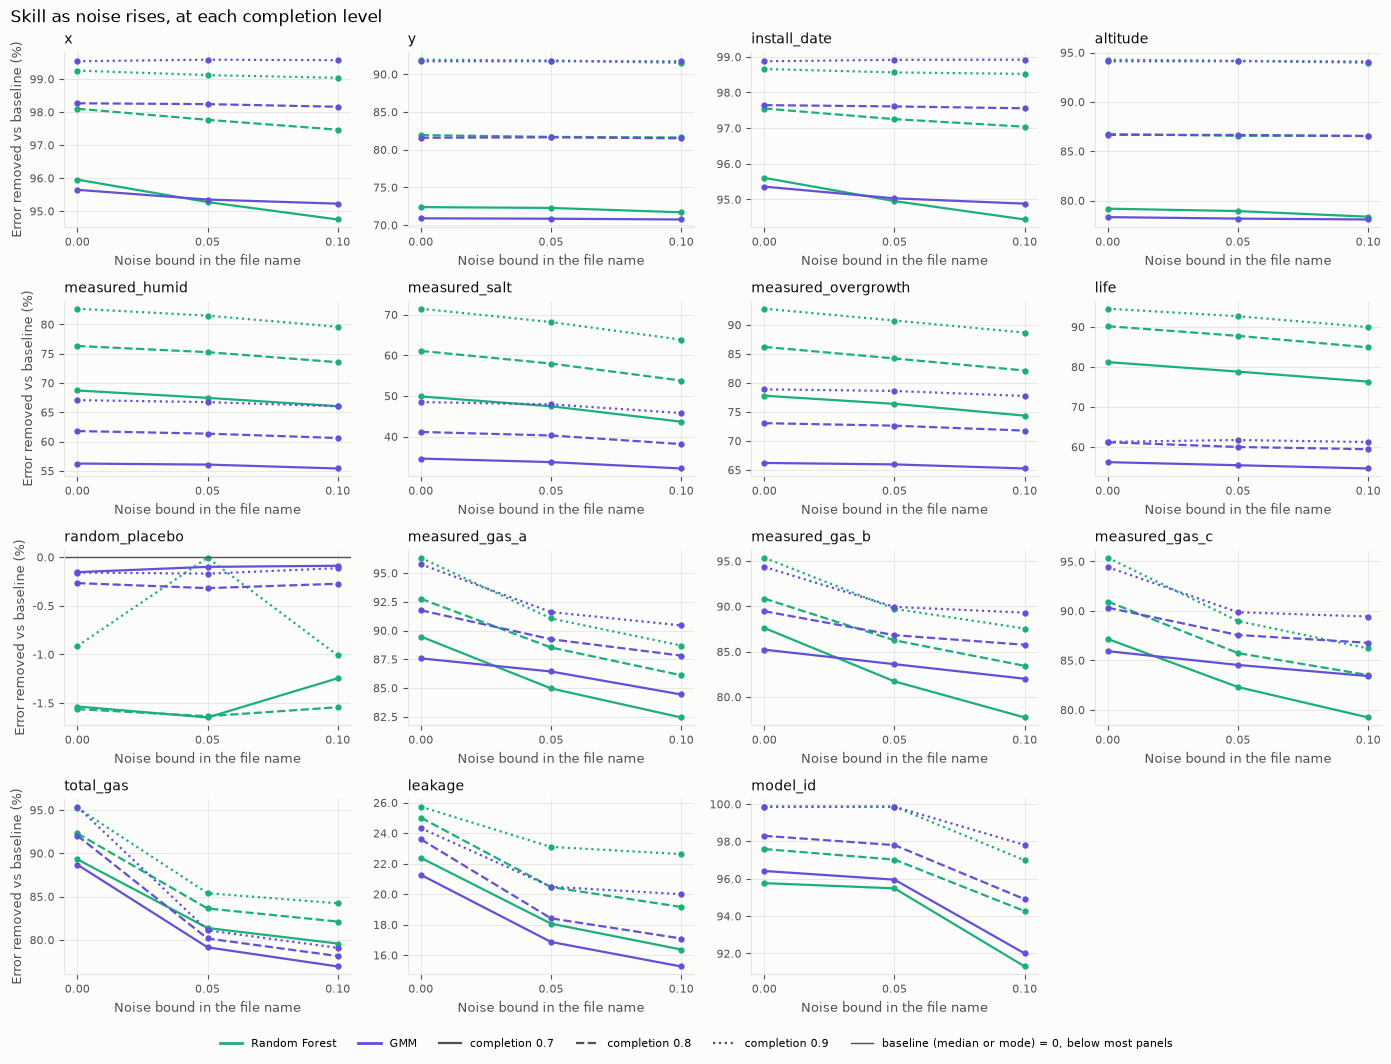

**Figure 6.1a.** Skill of the main models against the noise bound, one panel per column; line style marks the completion level.

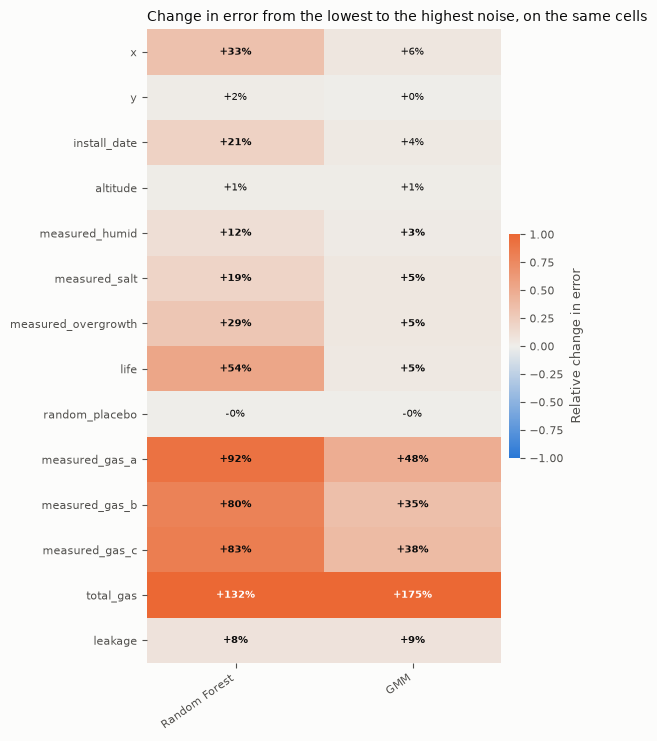

**Figure 6.1b.** Relative change in MAE from the lowest to the highest noise level on identical cells, with completion held at 0.8; bold values have a 95% interval that excludes zero.

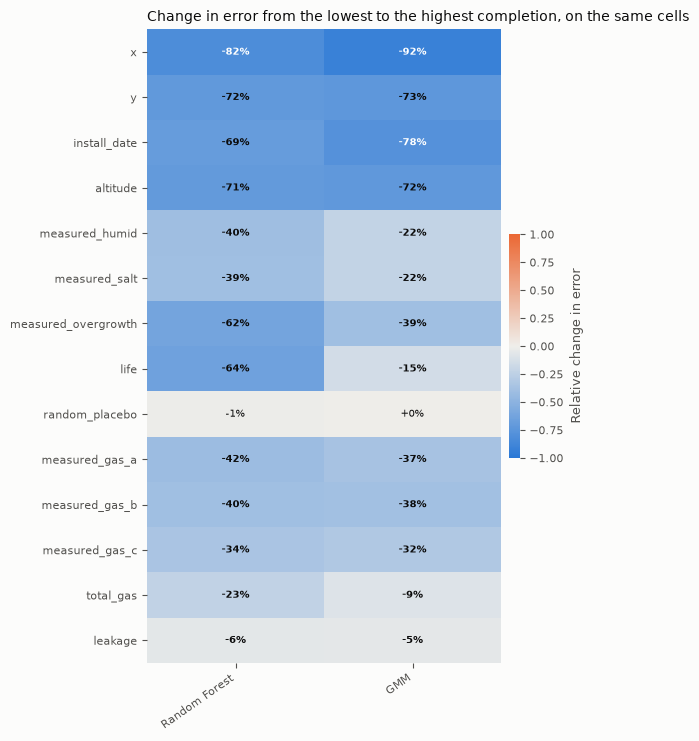

**Figure 6.1c.** Relative change in MAE from the lowest to the highest completion level on identical cells, with noise held at 0.05; bold values have a 95% interval that excludes zero.

In [27]:
# Skill against the noise bound, then the effect of each control measured on identical cells.
main_scores = STUDY.by_scenario[STUDY.by_scenario.method.isin(MAIN)]
fg.plot_lines(main_scores, "noise", "Skill as noise rises, at each completion level", FIGURES, "skill_by_noise",
              "Noise bound in the file name", MAIN, style="completion", style_label="completion")
fg.caption("Figure 6.1a", "Skill of the main models against the noise bound, one panel per column; "
           "line style marks the completion level.")
completion_level, noise_level = STUDY.scenarios[REPRESENTATIVE].completion, STUDY.scenarios[REPRESENTATIVE].noise
for letter, (control, held, level, label) in zip("bc", (("noise", "held completion", completion_level, "noise"),
                                                        ("completeness", "held noise", noise_level, "completion"))):
    matrix, marks = ev.effect_matrix(STUDY.effects, control, held, level)
    keep = [i for i, method in enumerate(matrix.columns) if method in COMPARED]  # the baseline and the main models
    matrix, marks = matrix.iloc[:, keep], marks[:, keep]
    fg.plot_heatmap(matrix, f"Change in error from the lowest to the highest {label}, on the same cells", FIGURES,
                    f"{control}_effect", "Relative change in error", center=0.0, limit=1.0, marks=marks, fmt="{:+.0%}")
    fg.caption(f"Figure 6.1{letter}", f"Relative change in MAE from the lowest to the highest {label} level on identical "
               f"cells, with {held.removeprefix('held ')} held at {level}; bold values have a 95% interval that excludes zero.")


### 6.2 Heavier random missingness

The generator's files stop at 0.7 completion. Two added scenarios hide further cells at random, down to 0.5 and 0.3 completion at noise 0.05, nested within the 0.7 mask (section 2.5). Figure 6.2 follows skill from 0.9 to 0.3 completion for the main models; Table 6.2 gives their mean skill over the columns with a relationship.


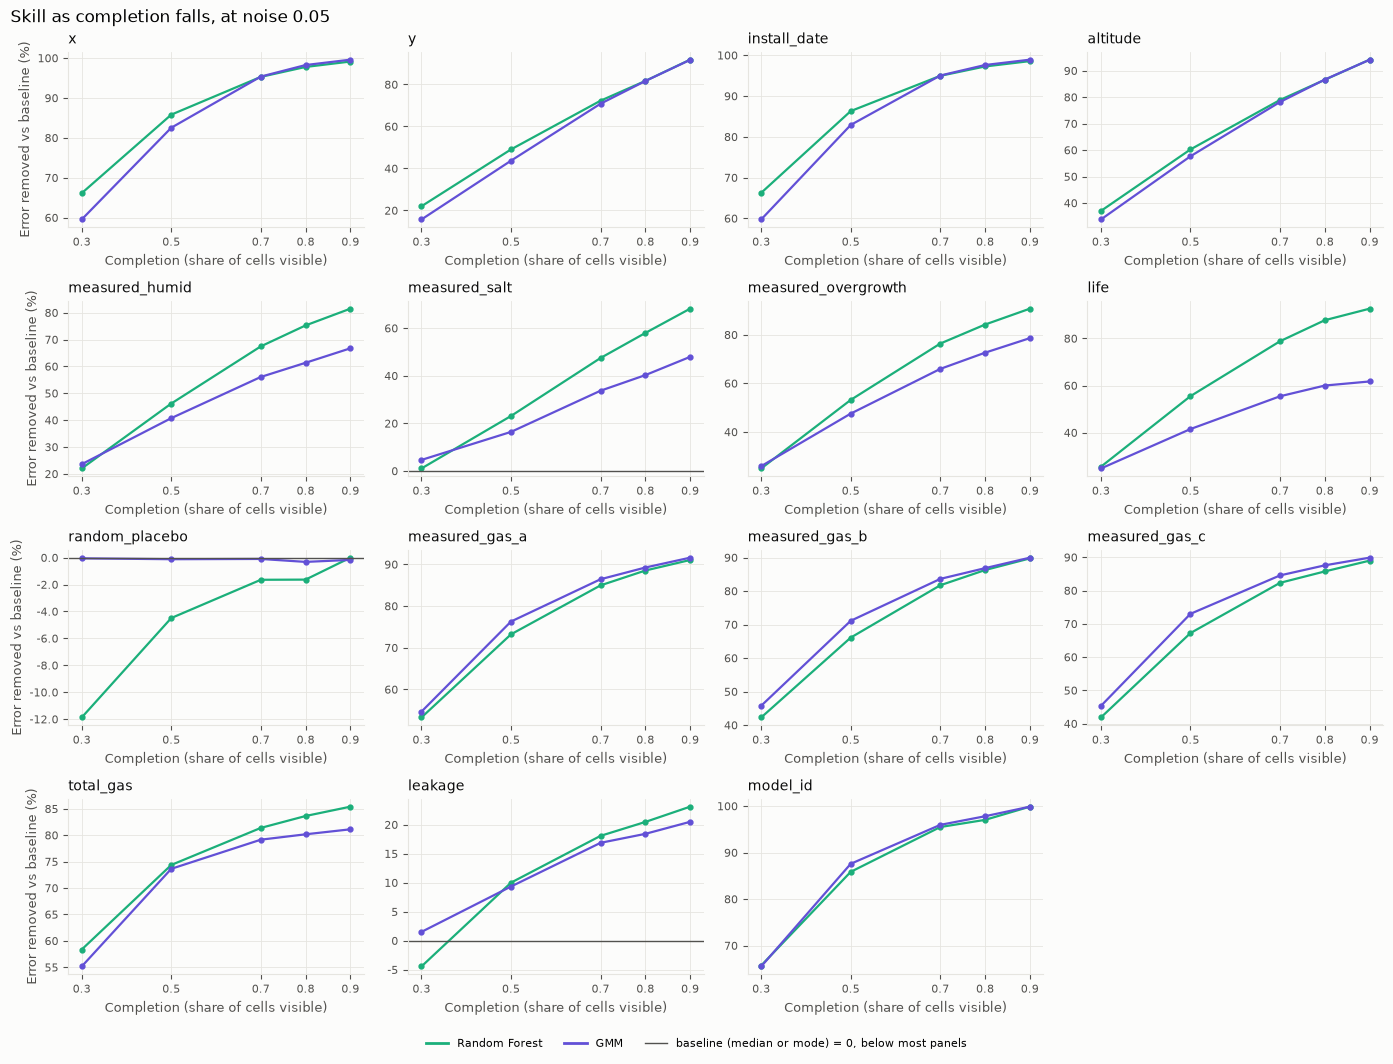

**Figure 6.2.** Skill of the main models as completion falls from 0.9 to 0.3 at noise 0.05, one panel per column.

**Table 6.2.** Mean skill over the columns with a relationship, by completion level.

completion,0.3,0.5,0.7,0.8,0.9
method,,,,,
Random Forest,0.373,0.597,0.754,0.807,0.853
GMM,0.368,0.574,0.712,0.756,0.794


In [28]:
# Skill as completion falls from 0.9 to 0.3 at noise 0.05.
completion = STUDY.completion
fg.plot_lines(completion[completion.method.isin(MAIN)], "completion", "Skill as completion falls, at noise 0.05", FIGURES,
              "skill_by_completion", "Completion (share of cells visible)", MAIN)
fg.caption("Figure 6.2", "Skill of the main models as completion falls from 0.9 to 0.3 at noise 0.05, one panel per column.")
fg.table("Table 6.2", "Mean skill over the columns with a relationship, by completion level.",
         completion[completion.target.isin(fl.SIGNAL_TARGETS)].groupby(["method", "completion"]).skill.mean()
         .unstack().reindex(MAIN).round(3))


### 6.3 Missingness mechanism

Four scenarios hide the same share of cells: at random, more often for older assets, more often for higher values, and in blocks of related columns. Figures 6.3a and 6.3b show the skill of each main model in each scenario; Table 6.3a gives the mean skill over the columns with a relationship.

Skill can conceal a systematic shift. When higher values are hidden more often, the visible values of a column are lower than the hidden ones, and an estimate anchored to the visible range is biased downwards. Table 6.3b therefore gives the mean signed error in units of the column's standard deviation, for the main models and the baseline. Table 6.3c gives mean skill by age third, to check whether assets with more gaps are also filled less accurately.


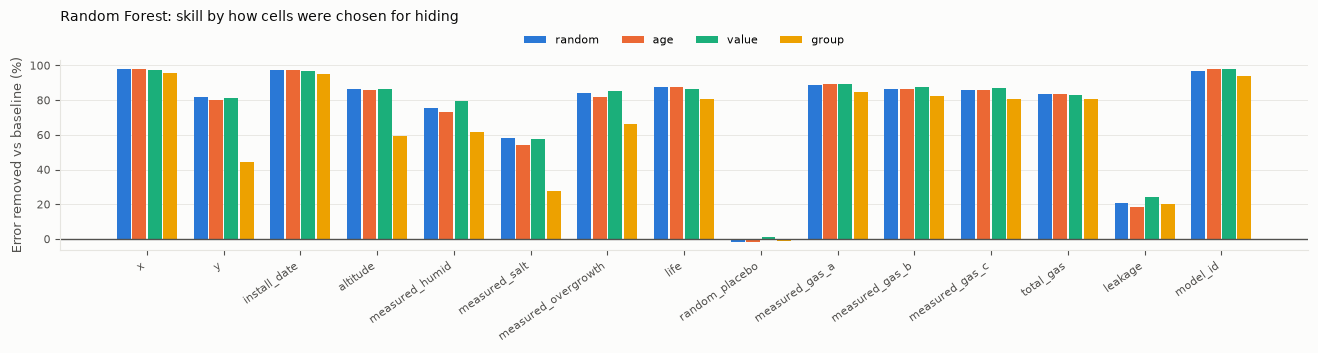

**Figure 6.3a.** Random Forest: skill on each column under each missingness mechanism.

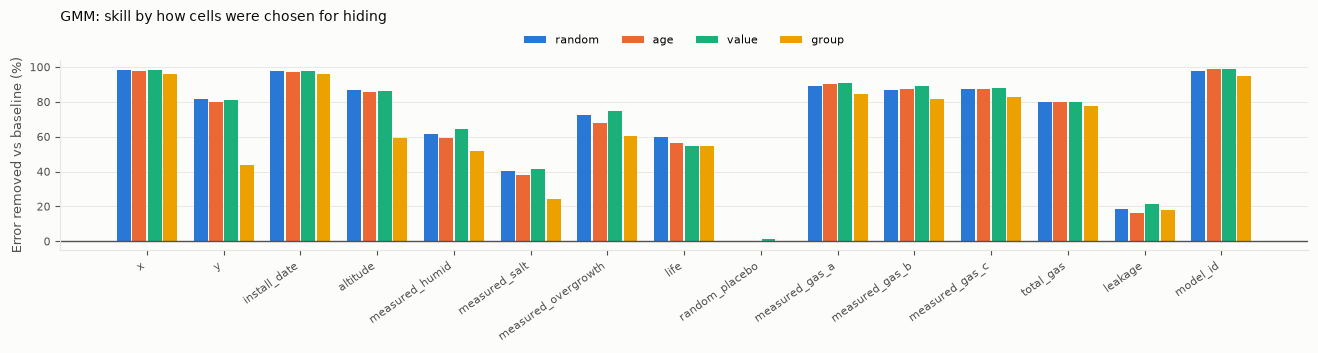

**Figure 6.3b.** GMM: skill on each column under each missingness mechanism.

**Table 6.3a.** Mean skill over the columns with a relationship, by missingness mechanism.

mechanism,random,age,value,group
method,,,,
Median,0.000,0.000,0.000,0.000
Random Forest,0.807,0.799,0.814,0.695
GMM,0.756,0.744,0.761,0.660


**Table 6.3b.** Mean signed error in units of the column's standard deviation, by mechanism.

method              Median                      Random Forest                         GMM                     
mechanism           random    age  value  group        random    age  value  group random    age  value  group
target                                                                                                        
x                    0.006  0.402 -0.436 -0.013         0.003  0.003 -0.000 -0.010  0.003  0.006 -0.001 -0.001
y                    0.001  0.037 -0.373  0.010        -0.016 -0.009 -0.054 -0.056 -0.002 -0.002 -0.073 -0.003
install_date         0.008  0.384 -0.389  0.036         0.002  0.003 -0.001 -0.011  0.003  0.006 -0.000 -0.001
altitude             0.044  0.283 -0.325  0.013        -0.009 -0.005 -0.036 -0.046  0.001  0.003 -0.050 -0.002
measured_humid      -0.081  0.012 -0.499 -0.095        -0.002  0.002 -0.035  0.003 -0.000  0.002 -0.100 -0.009
measured_salt       -0.046 -0.009 -0.417 -0.025        -0.005 -0.000 -0.038 -0.127  0.007  0.028 -0.153  0.013
measured_overgrowth -0.308 -0.217 -0.669 -0.321        -0.009 -0.014 -0.035 -0.033  0.039  0.030 -0.006  0.012
life                 0.216  0.122 -0.150  0.225        -0.001  0.006  0.006  0.038  0.001  0.010 -0.043  0.004
random_placebo       0.043  0.037 -0.383  0.032         0.042  0.037 -0.339  0.037  0.042  0.035 -0.338  0.036
measured_gas_a      -0.225 -0.647 -0.731 -0.226        -0.003  0.003 -0.016  0.005 -0.005  0.001 -0.006  0.007
measured_gas_b      -0.149 -0.362 -0.616 -0.145        -0.007 -0.001 -0.000 -0.014  0.006  0.002 -0.003 -0.011
measured_gas_c       0.161  0.178 -0.298  0.120         0.014  0.002  0.001  0.018  0.002  0.002 -0.009 -0.002
total_gas            0.094 -0.300 -0.288  0.077        -0.005 -0.006 -0.014  0.002 -0.006 -0.006 -0.019 -0.009
leakage             -0.023  0.005 -0.413 -0.025        -0.004 -0.003 -0.225 -0.018 -0.010  0.013 -0.253 -0.008

**Table 6.3c.** Mean skill by age third of the asset, by mechanism.

age third                middle third  newest third  oldest third
method        mechanism                                          
GMM           age               0.728         0.815         0.682
              group             0.612         0.711         0.603
              random            0.722         0.798         0.702
              value             0.737         0.794         0.715
Random Forest age               0.779         0.862         0.756
              group             0.645         0.730         0.672
              random            0.775         0.838         0.778
              value             0.790         0.838         0.785

In [29]:
# Skill, signed error and skill by age under four missingness mechanisms with the same hidden share.
scores = STUDY.mechanism_scores
order = ["random", "age", "value", "group"]
for method in MAIN:
    skill = scores[scores.method.eq(method)].pivot(index="target", columns="mechanism", values="skill").reindex(list(TARGETS))
    fg.plot_bars(skill[order], f"{method}: skill by how cells were chosen for hiding", FIGURES,
                 f"skill_by_mechanism_{FILE[method]}", "Error removed vs baseline (%)")
    fg.caption(f"Figure 6.3{LETTER[method]}", f"{method}: skill on each column under each missingness mechanism.")
signal = scores[scores.target.isin(fl.SIGNAL_TARGETS) & scores.mechanism.isin(order)]
fg.table("Table 6.3a", "Mean skill over the columns with a relationship, by missingness mechanism.",
         signal.groupby(["method", "mechanism"]).skill.mean().unstack()[order].reindex(COMPARED).round(3))
bias = scores[scores.method.isin(COMPARED) & scores.target.ne("model_id") & scores.mechanism.isin(order)]
fg.table("Table 6.3b", "Mean signed error in units of the column's standard deviation, by mechanism.",
         bias.pivot(index="target", columns=["method", "mechanism"], values="bias in SD").reindex(list(NUMERIC_TARGETS)).round(3))
groups = STUDY.mechanism_groups
groups = groups[groups.method.isin(MAIN) & groups.mechanism.isin(order)]
fg.table("Table 6.3c", "Mean skill by age third of the asset, by mechanism.",
         groups.pivot(index=["method", "mechanism"], columns="age third", values="skill").round(3))


### 6.4 Wrong recorded values

The errors scenario keeps the representative mask and corrupts some visible values: 5% of visible installation days shift by 60 days, and 2% of visible `model_id` values become another model. Because the mask is unchanged, every hidden cell is compared with itself, once with correct and once with wrong visible values. Rows without a wrong value show the effect that reaches them through the fitted model alone.

Table 6.4 gives the mean skill over the columns with a relationship, with correct and with wrong visible values. Figure 6.4 gives the relative change in error by column in rows that hold a wrong value; a cell is empty where the error with correct values was zero, which applies to most `model_id` cells.


**Table 6.4.** Mean skill over the columns with a relationship, with correct and with wrong visible values, in rows with and without a wrong value.

skill             skill with wrong values            
row           row with a wrong value row without  row with a wrong value row without
method                                                                              
Random Forest                  0.821       0.806                   0.745       0.804
GMM                            0.770       0.755                   0.665       0.751

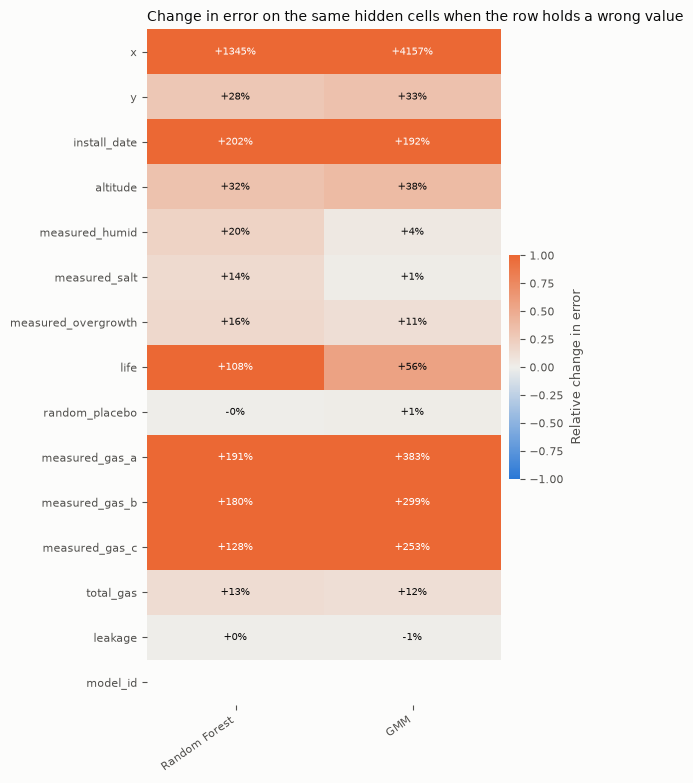

**Figure 6.4.** Relative change in MAE on the same hidden cells when the row holds a wrong value.

In [30]:
# The same hidden cells filled from correct and from partly wrong visible values.
wrong = STUDY.wrong_values
summary = wrong[wrong.target.isin(fl.SIGNAL_TARGETS)].groupby(["method", "row"])[["skill", "skill with wrong values"]].mean()
fg.table("Table 6.4", "Mean skill over the columns with a relationship, with correct and with wrong visible values, "
         "in rows with and without a wrong value.", summary.unstack("row").reindex(MAIN).round(3))
change = wrong[wrong.row.eq("row with a wrong value")].pivot(index="target", columns="method", values="relative change in error")
change = change.reindex(list(TARGETS))[[m for m in MAIN if m in change]]
if change.notna().any().any():  # a small sample can leave too few rows with a wrong value
    fg.plot_heatmap(change, "Change in error on the same hidden cells when the row holds a wrong value", FIGURES, "wrong_values",
                    "Relative change in error", center=0.0, limit=1.0, fmt="{:+.0%}")
    fg.caption("Figure 6.4", "Relative change in MAE on the same hidden cells when the row holds a wrong value.")


### 6.5 Spatial hold-out

Random folds leave training rows next to every held-out row. Here the representative scenario is split into folds of whole 10 × 10 blocks of the grid, so a held-out asset has no training asset nearby (Roberts et al., 2017), as when records are filled for an area without training records. Blocks are defined by grid position, which no model receives. Table 6.5 gives the mean skill over the columns with a relationship under both splits; Figure 6.5 gives the change in skill by column.


**Table 6.5.** Mean skill over the columns with a relationship, with random folds and with folds of whole grid blocks.

experiment,random rows,whole blocks,change
method,,,
Random Forest,0.807,0.803,-0.004
GMM,0.756,0.756,-0.000


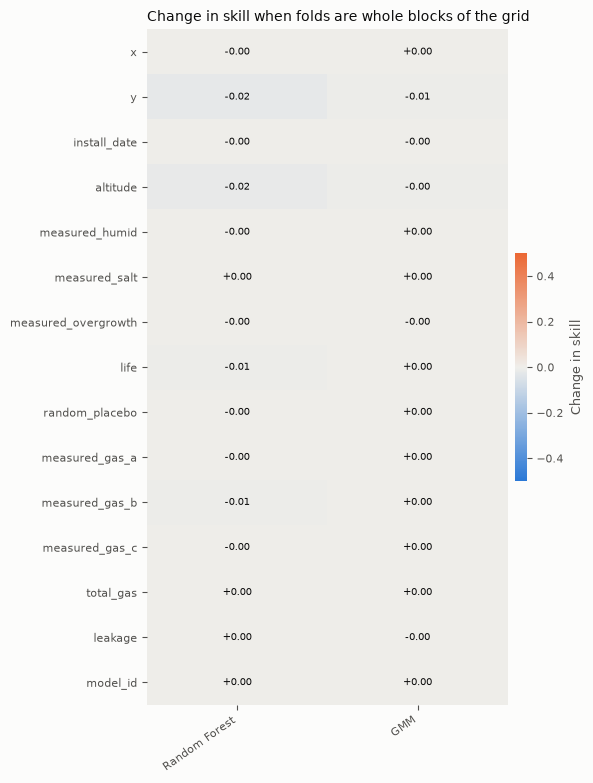

**Figure 6.5.** Change in skill on each column when folds are whole 10 × 10 blocks of the grid.

In [31]:
# Skill with random folds and with folds of whole grid blocks.
splits = STUDY.splits
fg.table("Table 6.5", "Mean skill over the columns with a relationship, with random folds and with folds of whole grid blocks.",
         splits[splits.target.isin(fl.SIGNAL_TARGETS)].groupby("method")[["random rows", "whole blocks", "change"]].mean()
         .reindex(MAIN).round(3))
change = splits.pivot(index="target", columns="method", values="change").reindex(list(TARGETS))
fg.plot_heatmap(change[[m for m in MAIN if m in change]], "Change in skill when folds are whole blocks of the grid", FIGURES,
                "fold_design", "Change in skill", center=0.0, limit=0.5, fmt="{:+.2f}")
fg.caption("Figure 6.5", "Change in skill on each column when folds are whole 10 × 10 blocks of the grid.")


### 6.6 Visible linked columns

A column's directly linked columns are those it is computed from and those computed from it, by the generator's definition. For each hidden cell, the number of linked columns visible in the same row is counted from the measured data. In Figure 6.6 each panel shows skill against the visible share, with one line style per noise level; groups with fewer than 30 cells are omitted. Table 6.6 gives the values of the main models in the representative scenario.


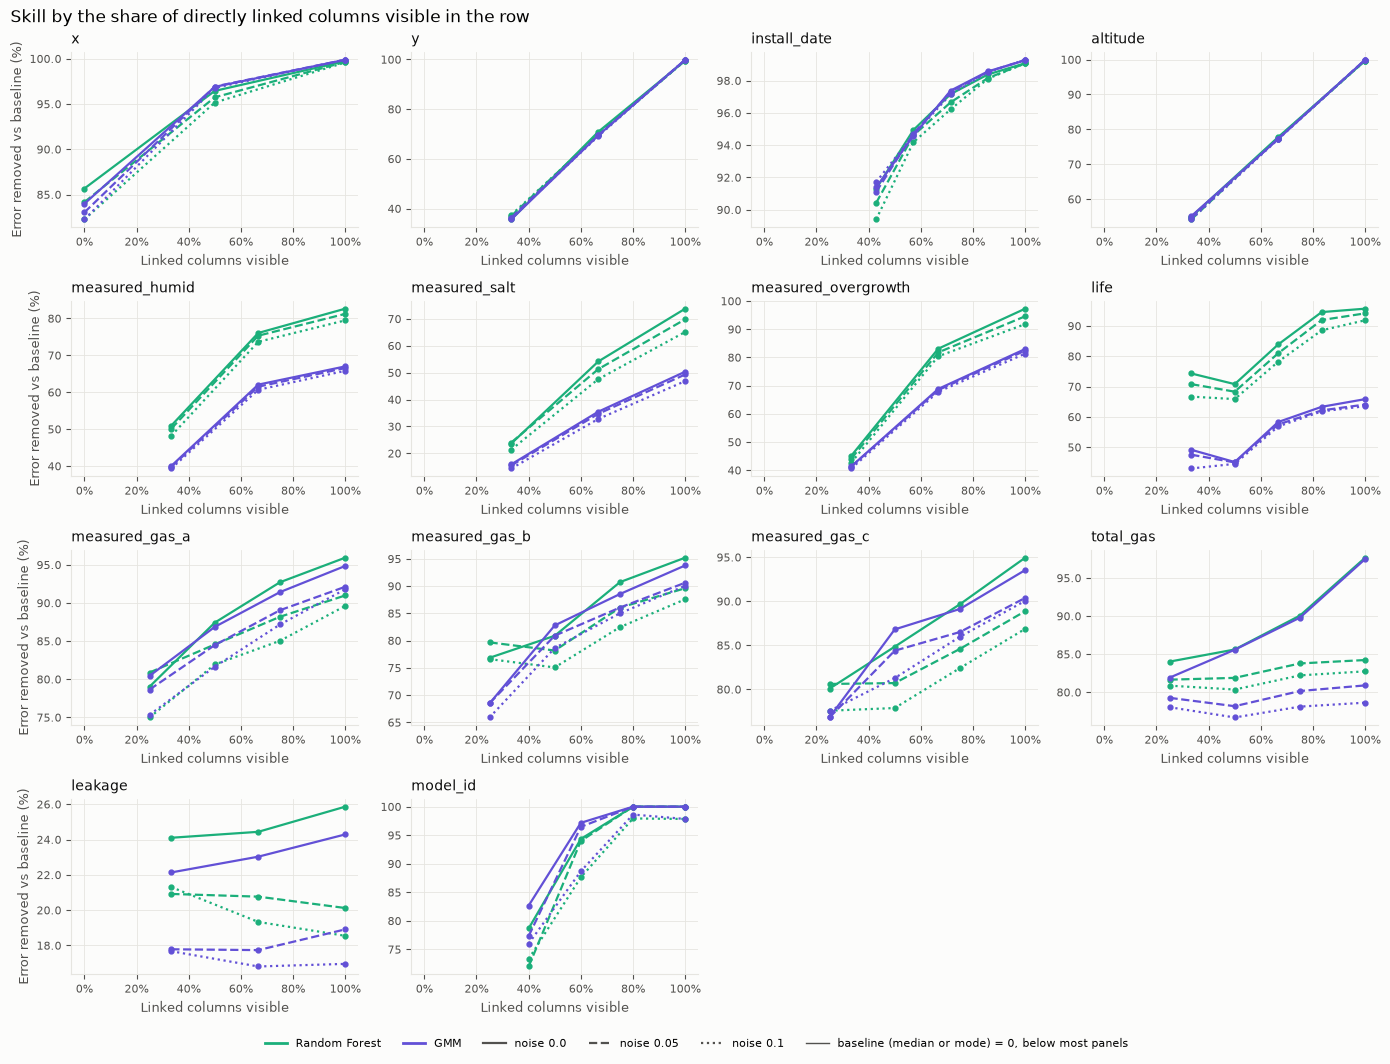

**Figure 6.6.** Skill of the main models by the share of directly linked columns visible in the row; line style marks the noise level.

**Table 6.6.** Skill by the number of linked columns visible, `completion0.8-noise0.05`.

method                       Random Forest    GMM
target              visible                      
x                   0 of 2           0.842  0.830
                    1 of 2           0.957  0.969
                    2 of 2           0.996  0.999
y                   1 of 3           0.370  0.364
                    2 of 3           0.699  0.695
                    3 of 3           0.996  0.999
install_date        3 of 7           0.904  0.911
                    4 of 7           0.946  0.947
                    5 of 7           0.967  0.973
                    6 of 7           0.982  0.985
                    7 of 7           0.991  0.993
altitude            1 of 3           0.542  0.546
                    2 of 3           0.776  0.774
                    3 of 3           0.997  1.000
measured_humid      1 of 3           0.501  0.398
                    2 of 3           0.753  0.615
                    3 of 3           0.812  0.666
measured_salt       1 of 3           0.240  0.155
                    2 of 3           0.513  0.347
                    3 of 3           0.698  0.493
measured_overgrowth 1 of 3           0.441  0.413
                    2 of 3           0.818  0.684
                    3 of 3           0.946  0.824
life                2 of 6           0.708  0.475
                    3 of 6           0.683  0.450
                    4 of 6           0.810  0.575
                    5 of 6           0.919  0.621
                    6 of 6           0.941  0.641
measured_gas_a      1 of 4           0.809  0.786
                    2 of 4           0.846  0.845
                    3 of 4           0.882  0.890
                    4 of 4           0.910  0.921
measured_gas_b      1 of 4           0.797  0.685
                    2 of 4           0.782  0.809
                    3 of 4           0.860  0.861
                    4 of 4           0.896  0.906
measured_gas_c      1 of 4           0.806  0.768
                    2 of 4           0.807  0.844
                    3 of 4           0.846  0.865
                    4 of 4           0.889  0.904
total_gas           1 of 4           0.816  0.793
                    2 of 4           0.819  0.782
                    3 of 4           0.838  0.802
                    4 of 4           0.842  0.809
leakage             1 of 3           0.209  0.178
                    2 of 3           0.208  0.177
                    3 of 3           0.201  0.189
model_id            2 of 5           0.720  0.773
                    3 of 5           0.940  0.965
                    4 of 5           1.000  1.000
                    5 of 5           1.000  1.000

In [32]:
# Skill by the number of directly linked columns visible in the row of each hidden cell.
seen = ev.add_scenario_levels(STUDY.visibility, STUDY.scenarios)
fg.plot_lines(seen[seen.method.isin(MAIN)], "share seen", "Skill by the share of directly linked columns visible in the row",
              FIGURES, "skill_by_visible_links", "Linked columns visible", MAIN, style="noise", style_label="noise", share_seen=True)
fg.caption("Figure 6.6", "Skill of the main models by the share of directly linked columns visible in the row; "
           "line style marks the noise level.")
main_seen = seen[seen.method.isin(MAIN) & seen.scenario.eq(REPRESENTATIVE)].copy()
main_seen["visible"] = main_seen.seen.astype(int).astype(str) + " of " + main_seen.links.astype(int).astype(str)
main_seen["order"] = main_seen.target.map(list(TARGETS).index)  # keeps the column order of the definitions
fg.table("Table 6.6", f"Skill by the number of linked columns visible, `{REPRESENTATIVE}`.",
         main_seen.pivot_table(index=["order", "target", "visible"], columns="method", values="skill")
         .droplevel("order")[MAIN].round(3))


### 6.7 Kind of relationship

Columns are grouped by how the generator builds them. Tables 6.7a and 6.7b give the mean skill of each main model for each kind: in the representative scenario, in its best and worst generator scenario, and when few linked columns are visible.


In [33]:
# Mean skill by kind of relationship, for each main model.
with pd.option_context("display.max_colwidth", 70):
    for method in MAIN:
        fg.table(f"Table 6.7{LETTER[method]}", f"{method}: mean skill by kind of relationship in the representative, "
                 "best and worst scenario and with few linked columns visible.", STUDY.kinds[method].round(3))


**Table 6.7a.** Random Forest: mean skill by kind of relationship in the representative, best and worst scenario and with few linked columns visible.

,kind of relationship,columns,reference,best scenario,worst scenario,few linked columns visible
0,near copy of another column,"x, install_date",0.975,0.990,0.946,0.842
1,exact sum,"altitude, y, total_gas",0.840,0.938,0.766,0.565
2,threshold,measured_overgrowth,0.842,0.928,0.744,0.422
3,random draw scaled by another column,"measured_humid, measured_salt",0.666,0.771,0.548,0.345
4,decline that depends on the model,"measured_gas_a, measured_gas_b, measured_gas_c",0.868,0.957,0.798,0.807
5,product that depends on the model,life,0.877,0.945,0.763,0.634
6,category drawn from a moving window,model_id,0.970,0.999,0.913,NaN
7,"independent draw, seen only through its effects",leakage,0.205,0.257,0.164,0.209
8,no relationship,random_placebo,-0.016,-0.000,-0.016,NaN


**Table 6.7b.** GMM: mean skill by kind of relationship in the representative, best and worst scenario and with few linked columns visible.

,kind of relationship,columns,reference,best scenario,worst scenario,few linked columns visible
0,near copy of another column,"x, install_date",0.979,0.993,0.951,0.830
1,exact sum,"altitude, y, total_gas",0.828,0.937,0.753,0.558
2,threshold,measured_overgrowth,0.726,0.789,0.652,0.392
3,random draw scaled by another column,"measured_humid, measured_salt",0.508,0.578,0.438,0.258
4,decline that depends on the model,"measured_gas_a, measured_gas_b, measured_gas_c",0.879,0.949,0.833,0.752
5,product that depends on the model,life,0.600,0.617,0.546,0.405
6,category drawn from a moving window,model_id,0.978,0.999,0.920,NaN
7,"independent draw, seen only through its effects",leakage,0.184,0.243,0.153,0.187
8,no relationship,random_placebo,-0.003,-0.001,-0.003,NaN


### 6.8 Position of the true value

Cells are grouped by the position of their true value within the column: the lowest tenth, the next fifth, the middle 40%, and the same bands on the high side. The grouping is known only after the fact, so it explains errors and implies no filling rule.

Figure 6.8 shows the mean signed error in units of the column's standard deviation, from the lowest band on the left to the highest on the right. A line that falls from left to right means that low values are overestimated and high values underestimated; the dashed line is the baseline. Tables 6.8a and 6.8b give the size of the error of each main model.


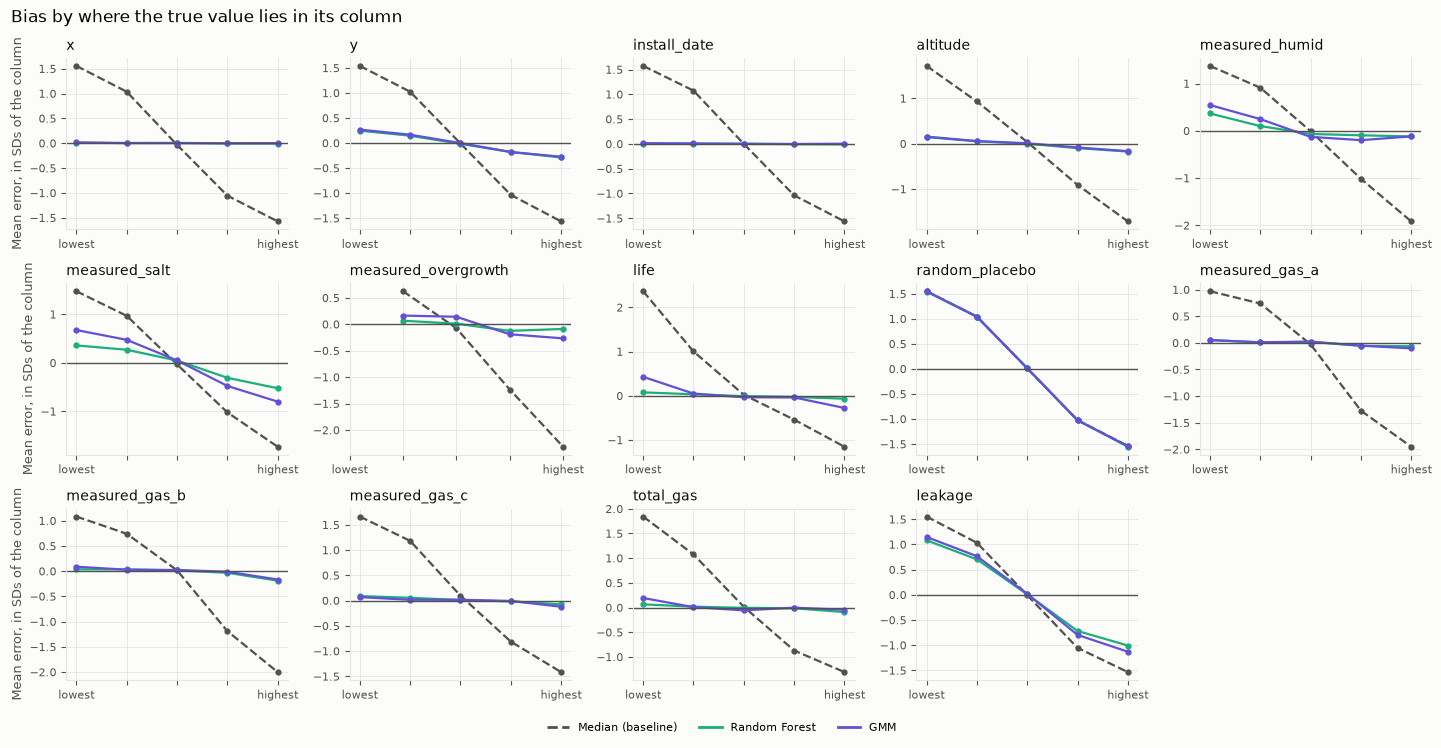

**Figure 6.8.** Mean signed error in units of the column's standard deviation, by band of the true value; the dashed line is the baseline.

**Table 6.8a.** Random Forest: mean absolute error in units of the column's standard deviation, by band of the true value.

band,lowest 10%,10% to 30%,middle 40%,70% to 90%,highest 10%
target,,,,,
x,0.008,0.016,0.025,0.020,0.014
y,0.252,0.152,0.090,0.187,0.295
install_date,0.013,0.019,0.029,0.025,0.020
altitude,0.148,0.080,0.094,0.123,0.178
measured_humid,0.386,0.226,0.179,0.153,0.206
measured_salt,0.419,0.331,0.273,0.415,0.587
measured_overgrowth,NaN,0.066,0.134,0.207,0.173
life,0.163,0.117,0.070,0.067,0.112
random_placebo,1.544,1.040,0.382,1.022,1.554


**Table 6.8b.** GMM: mean absolute error in units of the column's standard deviation, by band of the true value.

band,lowest 10%,10% to 30%,middle 40%,70% to 90%,highest 10%
target,,,,,
x,0.019,0.014,0.017,0.012,0.011
y,0.270,0.174,0.082,0.181,0.276
install_date,0.024,0.019,0.023,0.017,0.019
altitude,0.159,0.079,0.097,0.115,0.165
measured_humid,0.560,0.345,0.251,0.311,0.353
measured_salt,0.711,0.537,0.336,0.556,0.855
measured_overgrowth,NaN,0.163,0.234,0.273,0.306
life,0.481,0.252,0.245,0.289,0.456
random_placebo,1.548,1.043,0.350,1.028,1.543


In [34]:
# Signed and absolute error by band of the true value.
fg.plot_bands(STUDY.bands, COMPARED, list(fl.BANDS), FIGURES)
fg.caption("Figure 6.8", "Mean signed error in units of the column's standard deviation, by band of the true value; "
           "the dashed line is the baseline.")
for method in MAIN:
    fg.table(f"Table 6.8{LETTER[method]}", f"{method}: mean absolute error in units of the column's standard deviation, "
             "by band of the true value.",
             STUDY.bands[STUDY.bands.method.eq(method)].pivot(index="target", columns="band", values="error in SD")
             .reindex(index=list(NUMERIC_TARGETS), columns=list(fl.BANDS)).round(3))


## 7. Characteristics of failure

Chapter 6 located the conditions under which skill falls. This chapter describes the estimates under those conditions.

### 7.1 Shrinkage towards the centre

The slope $b$ of the regression of estimates on true values, $\hat{v} = a + b\,v$, is 1 when estimates follow the truth and 0 when they are constant. Figure 7.1 plots $b$ against the share of linked columns visible; a slope that falls with the share means that, with less information, a model returns values closer to the centre of the column.

Table 7.1 gives the spread ratio $\sigma(\hat{v}) / \sigma(v)$, the standard deviation of the imputed values relative to that of the truth, over all hidden cells of the representative scenario. Values below 1 mean that completed columns are narrower than the real ones.


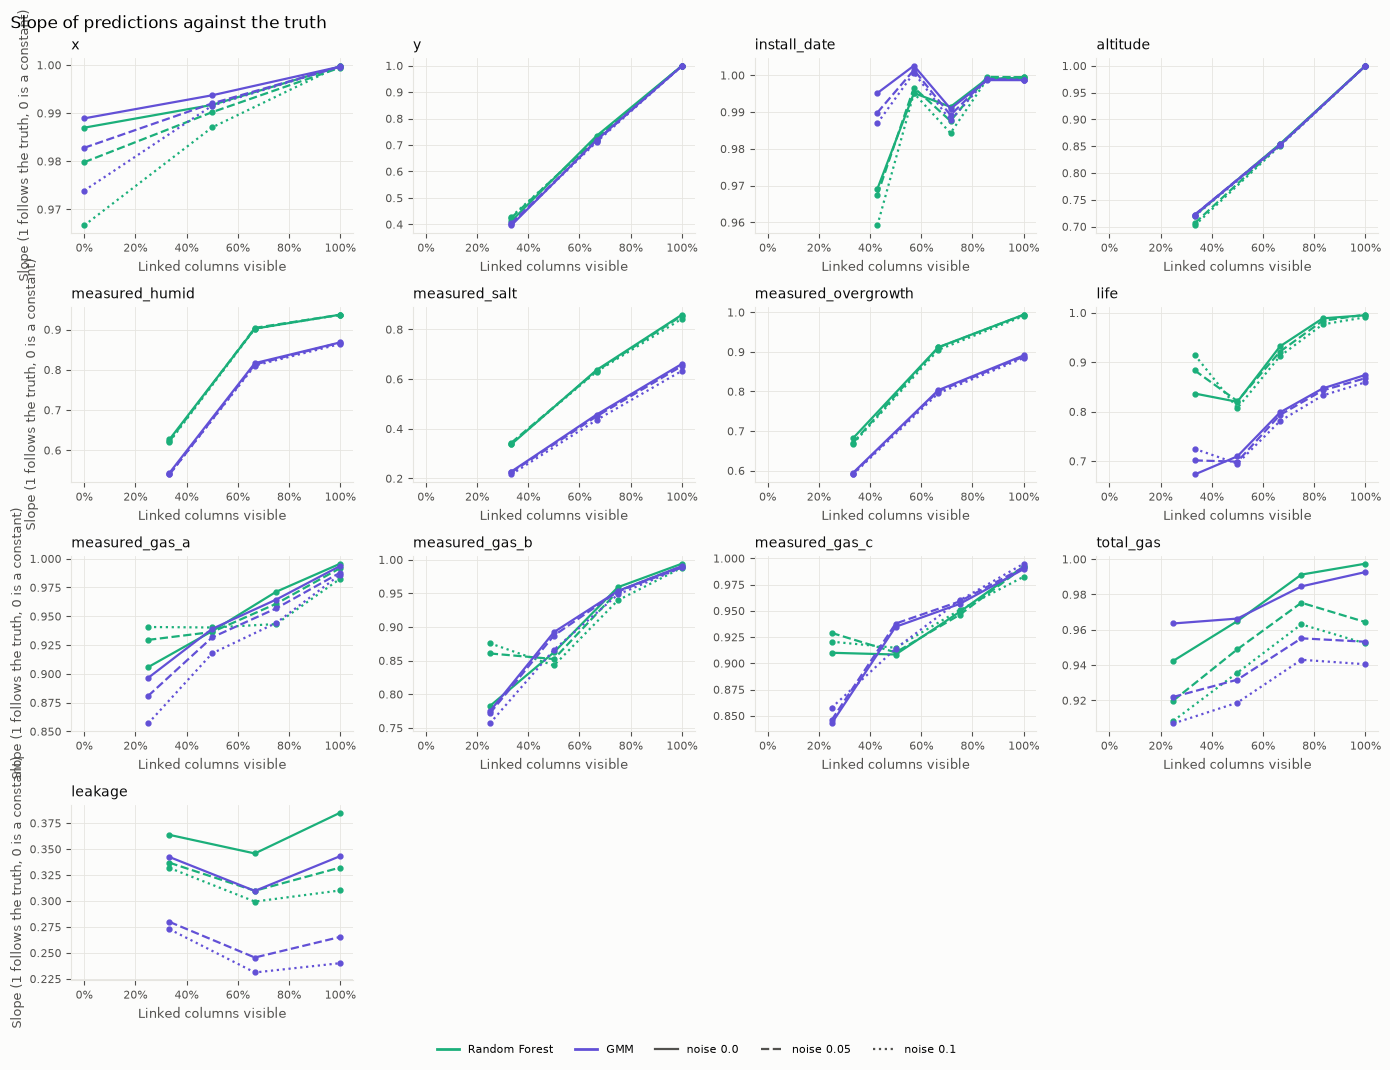

**Figure 7.1.** Slope of estimates on true values by the share of linked columns visible; line style marks the noise level.

**Table 7.1.** Spread ratio of imputed to true values over all hidden cells, `completion0.8-noise0.05`.

method,Median,Random Forest,GMM
target,,,
x,0.014,0.997,0.998
y,0.017,0.913,0.907
install_date,0.010,0.997,0.998
altitude,0.012,0.951,0.952
measured_humid,0.003,0.946,0.899
measured_salt,0.009,0.863,0.720
measured_overgrowth,0.010,0.966,0.872
life,0.005,0.982,0.904
random_placebo,0.004,0.193,0.044


In [35]:
# Slope of estimates on the truth by visible linked columns, and the spread of imputed values.
slopes = ev.add_scenario_levels(STUDY.shrinkage, STUDY.scenarios)
fg.plot_lines(slopes[slopes.method.isin(MAIN)], "share seen", "Slope of predictions against the truth", FIGURES, "slope_by_visible_links",
              "Linked columns visible", MAIN, style="noise", style_label="noise", share_seen=True, y="slope",
              ylabel="Slope (1 follows the truth, 0 is a constant)", targets=list(NUMERIC_TARGETS))
fg.caption("Figure 7.1", "Slope of estimates on true values by the share of linked columns visible; "
           "line style marks the noise level.")
spread = STUDY.spread
fg.table("Table 7.1", f"Spread ratio of imputed to true values over all hidden cells, `{REPRESENTATIVE}`.",
         spread[spread.scenario.eq(REPRESENTATIVE)].pivot(index="target", columns="method", values="spread ratio")
         .reindex(list(NUMERIC_TARGETS))[COMPARED].round(3))


### 7.2 Out-of-range predictions

Table 7.2 gives the share of raw predictions outside a column's valid range, before they are limited to it; scores use the limited values. Columns with a floor or a ceiling, such as `measured_overgrowth`, are where averaging models can leave the range.


In [36]:
# Share of raw estimates outside the valid range, before the range limit.
ranges = STUDY.ranges
fg.table("Table 7.2", f"Share of raw estimates outside the column's valid range, `{REPRESENTATIVE}`.",
         ranges[ranges.scenario.eq(REPRESENTATIVE)].pivot(index="target", columns="method", values="outside valid range")
         .reindex(list(NUMERIC_TARGETS))[MAIN].round(4))


**Table 7.2.** Share of raw estimates outside the column's valid range, `completion0.8-noise0.05`.

method,Random Forest,GMM
target,,
x,0.0000,0.0000
y,0.0000,0.0000
install_date,0.0000,0.0000
altitude,0.0000,0.0000
measured_humid,0.0000,0.0010
measured_salt,0.0025,0.0015
measured_overgrowth,0.0000,0.0000
life,0.0000,0.0000
random_placebo,0.0000,0.0000


### 7.3 Shape of the decline

Tables 7.3a and 7.3b describe the two declines of each main model.

- **Noise:** the skill lost from the lowest to the highest noise, and the share of that loss incurred at the first step. A share near 1 means that the first increment of noise causes most of the damage.
- **Hidden linked columns:** skill with every linked column visible and with the fewest, and the share of the loss incurred when the first column is hidden. A low share means that one hidden column is tolerated and several are not.

Shares are left empty where the loss is below 0.02.


In [37]:
# Skill lost with noise and with hidden linked columns, and the share of each loss at the first step.
for method in MAIN:
    fg.table(f"Table 7.3{LETTER[method]}", f"{method}: skill lost with noise and with hidden linked columns, "
             "and the share of each loss incurred at the first step.", STUDY.decline[method].round(3))


**Table 7.3a.** Random Forest: skill lost with noise and with hidden linked columns, and the share of each loss incurred at the first step.

,target,skill lost to noise,share lost at the first noise step,skill with every linked column,skill with the fewest,share lost when the first linked column is hidden
0,x,0.006,NaN,0.996,0.842,0.252
1,y,0.003,NaN,0.996,0.370,0.474
2,install_date,0.005,NaN,0.991,0.904,0.105
3,altitude,0.002,NaN,0.997,0.542,0.486
4,measured_humid,0.028,0.381,0.812,0.501,0.190
5,measured_salt,0.073,0.426,0.698,0.240,0.405
6,measured_overgrowth,0.041,0.490,0.946,0.441,0.254
7,life,0.053,0.456,0.941,0.708,0.094
8,random_placebo,-0.000,NaN,NaN,NaN,NaN
9,measured_gas_a,0.067,0.637,0.910,0.809,0.277


**Table 7.3b.** GMM: skill lost with noise and with hidden linked columns, and the share of each loss incurred at the first step.

,target,skill lost to noise,share lost at the first noise step,skill with every linked column,skill with the fewest,share lost when the first linked column is hidden
0,x,0.001,NaN,0.999,0.830,0.175
1,y,0.001,NaN,0.999,0.364,0.479
2,install_date,0.001,NaN,0.993,0.911,0.091
3,altitude,0.001,NaN,1.000,0.546,0.498
4,measured_humid,0.012,NaN,0.666,0.398,0.189
5,measured_salt,0.030,0.292,0.493,0.155,0.433
6,measured_overgrowth,0.013,NaN,0.824,0.413,0.340
7,life,0.018,NaN,0.641,0.475,0.117
8,random_placebo,0.000,NaN,NaN,NaN,NaN
9,measured_gas_a,0.039,0.638,0.921,0.786,0.228


### 7.4 Relationships between columns

Accurate cells do not guarantee that relationships between columns are preserved. Table 7.4a compares correlations in the completed data with those in the truth across all 91 pairs of numeric columns, on the rows that hold an imputed cell of the pair; a gap of 0 means that the correlation is unchanged.

Table 7.4b checks three generator definitions on completed rows. The reference is the residual in rows with nothing imputed, which reflects measurement noise alone.


In [38]:
# Correlations and generator definitions in the completed tables, against the truth.
gaps = STUDY.correlations[STUDY.correlations.method.isin(COMPARED)]
fg.table("Table 7.4a", "Mean gap between correlations in the completed data and in the truth, "
         "over the 91 pairs of numeric columns, by scenario.",
         gaps.pivot(index="method", columns="scenario", values="mean gap").reindex(COMPARED).round(4))
consistency = STUDY.consistency[STUDY.consistency.method.isin(COMPARED)]
wide = consistency.pivot(index=["relation", "scenario"], columns="method", values="mean residual in completed rows")[COMPARED]
wide["fully observed rows"] = consistency.groupby(["relation", "scenario"])["mean residual in fully observed rows"].first()
fg.table("Table 7.4b", "Mean residual of three generator definitions in completed rows and in fully observed rows.",
         wide.round(4))


**Table 7.4a.** Mean gap between correlations in the completed data and in the truth, over the 91 pairs of numeric columns, by scenario.

scenario,completion0.3-noise0.05-sparse,completion0.5-noise0.05-sparse,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.05-age,completion0.8-noise0.05-errors,completion0.8-noise0.05-group,completion0.8-noise0.05-value,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,,,,,,,
Median,0.2111,0.2117,0.2148,0.2144,0.2143,0.2148,0.2141,0.2124,0.2141,0.2137,0.2196,0.2140,0.2130,0.2124,0.2122
Random Forest,0.0334,0.0195,0.0122,0.0119,0.0139,0.0098,0.0096,0.0091,0.0093,0.0167,0.0164,0.0122,0.0060,0.0070,0.0099
GMM,0.0717,0.0364,0.0191,0.0190,0.0195,0.0143,0.0145,0.0156,0.0145,0.0244,0.0222,0.0160,0.0108,0.0123,0.0144


**Table 7.4b.** Mean residual of three generator definitions in completed rows and in fully observed rows.

method                                                          Median  Random Forest       GMM  fully observed rows
relation                            scenario                                                                        
altitude = x + y + 100              completion0.8-noise0.0     27.4631         0.1521    0.0682               0.0000
                                    completion0.8-noise0.05    27.4631         0.1687    0.0600               0.0000
                                    completion0.8-noise0.1     27.4631         0.1815    0.0568               0.0000
overgrowth = max(2 humid - salt, 0) completion0.8-noise0.0      0.2366         0.0097    0.0501               0.0000
                                    completion0.8-noise0.05     0.2362         0.0122    0.0511               0.0174
                                    completion0.8-noise0.1      0.2365         0.0172    0.0531               0.0348
total_gas = gas a + b + c           completion0.8-noise0.0   1146.5662        22.6729   38.2485               0.0000
                                    completion0.8-noise0.05  1184.4284       256.3251  286.6299             389.9461
                                    completion0.8-noise0.1   1305.4964       601.1176  608.9669             779.8922

### 7.5 Confidence of `model_id` predictions

Models report a probability with each `model_id` prediction. Tables 7.5a and 7.5b compare confidence with accuracy, first by the number of linked columns visible and then by scenario. `sure and wrong` is the share of cells predicted wrongly with a probability of 0.9 or more. Confidence that falls together with accuracy means that errors can be identified without the truth. Numeric estimates are single values and carry no such signal.


In [39]:
# Mean confidence against accuracy on `model_id`.
by_seen = STUDY.confidence_by_seen
fg.table("Table 7.5a", "Confidence and accuracy on `model_id` by the number of linked columns visible.",
         by_seen[by_seen.method.isin(MAIN)].sort_values(["method", "seen"]).round(3))
by_scenario = STUDY.confidence_by_scenario
fg.table("Table 7.5b", "Confidence and accuracy on `model_id` by scenario.",
         by_scenario[by_scenario.method.isin(MAIN)].sort_values(["method", "scenario"]).round(3))


**Table 7.5a.** Confidence and accuracy on `model_id` by the number of linked columns visible.

,method,seen,n,accuracy,confidence,sure and wrong,confidence minus accuracy
33,GMM,2,98,0.827,0.910,0.01,0.083
32,GMM,3,388,0.974,0.973,0.00,-0.001
30,GMM,4,815,1.000,0.998,0.00,-0.002
31,GMM,5,650,1.000,0.999,0.00,-0.001
9,Random Forest,2,98,0.786,0.777,0.00,-0.009
8,Random Forest,3,388,0.956,0.889,0.00,-0.067
6,Random Forest,4,815,1.000,0.950,0.00,-0.050
7,Random Forest,5,650,1.000,0.976,0.00,-0.024


**Table 7.5b.** Confidence and accuracy on `model_id` by scenario.

,method,scenario,n,accuracy,confidence,sure and wrong,confidence minus accuracy
45,GMM,completion0.7-noise0.0,2968,0.974,0.978,0.001,0.004
46,GMM,completion0.7-noise0.05,2968,0.971,0.975,0.002,0.004
47,GMM,completion0.7-noise0.1,2968,0.942,0.949,0.005,0.006
48,GMM,completion0.8-noise0.0,1965,0.988,0.990,0.001,0.002
49,GMM,completion0.8-noise0.05,1965,0.984,0.988,0.001,0.004
50,GMM,completion0.8-noise0.1,1965,0.963,0.965,0.004,0.002
51,GMM,completion0.9-noise0.0,995,0.999,0.998,0.000,-0.001
52,GMM,completion0.9-noise0.05,995,0.999,0.998,0.000,-0.001
53,GMM,completion0.9-noise0.1,995,0.984,0.979,0.002,-0.005
9,Random Forest,completion0.7-noise0.0,2968,0.969,0.917,0.000,-0.052


### 7.6 Shared errors between models

Table 7.6 gives, for every pair of models, the rank correlation between their cell errors, averaged over columns. A value near 1 means that two models are wrong on the same cells, which points to a limit in the data rather than in either model.


In [40]:
# Rank correlation of cell errors between every pair of models.
fg.table("Table 7.6", "Spearman rank correlation between the cell errors of each pair of models, averaged over columns.",
         STUDY.overlap.round(2))


**Table 7.6.** Spearman rank correlation between the cell errors of each pair of models, averaged over columns.

method,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct,GMM,Masked MLP,LightGBM chained,Predictive MissForest,MICE-PMM
method,,,,,,,,,,,
KNN imputer,1.00,0.83,0.76,0.73,0.75,0.55,0.61,0.42,0.55,0.47,0.45
IterativeImputer,0.83,1.00,0.67,0.67,0.69,0.52,0.63,0.43,0.51,0.46,0.47
Random Forest,0.76,0.67,1.00,0.81,0.79,0.61,0.57,0.42,0.62,0.48,0.44
HistGradientBoosting,0.73,0.67,0.81,1.00,0.85,0.59,0.57,0.42,0.60,0.47,0.44
CatBoost,0.75,0.69,0.79,0.85,1.00,0.58,0.57,0.42,0.60,0.46,0.45
miceforest direct,0.55,0.52,0.61,0.59,0.58,1.00,0.54,0.42,0.70,0.58,0.42
GMM,0.61,0.63,0.57,0.57,0.57,0.54,1.00,0.45,0.55,0.50,0.55
Masked MLP,0.42,0.43,0.42,0.42,0.42,0.42,0.45,1.00,0.43,0.42,0.37
LightGBM chained,0.55,0.51,0.62,0.60,0.60,0.70,0.55,0.43,1.00,0.55,0.47


## 8. Causes of failure

Each section states one candidate cause and tests it with a comparison.

### 8.1 Data limits and model limits

Part of the error cannot be removed by any model, because the data does not contain the answer. Two references separate this part.

Figures 8.1a and 8.1b divide each column's baseline error into three parts for each main model: the share removed, the share lost because linked columns were hidden, and the share that remains even with every linked column visible. Tables 8.1a and 8.1b give the values.

Tables 8.1c to 8.1e apply the generator's own definition to the visible inputs (`Formula`), on hidden cells whose defining inputs are all visible; values are MAE. Without noise the formula is exact, so any model error there is the model's own. With noise the formula inherits the noise of its inputs, and a model can do better by drawing on other columns. Table 8.1f shows how much of each column the other true columns could explain at all.


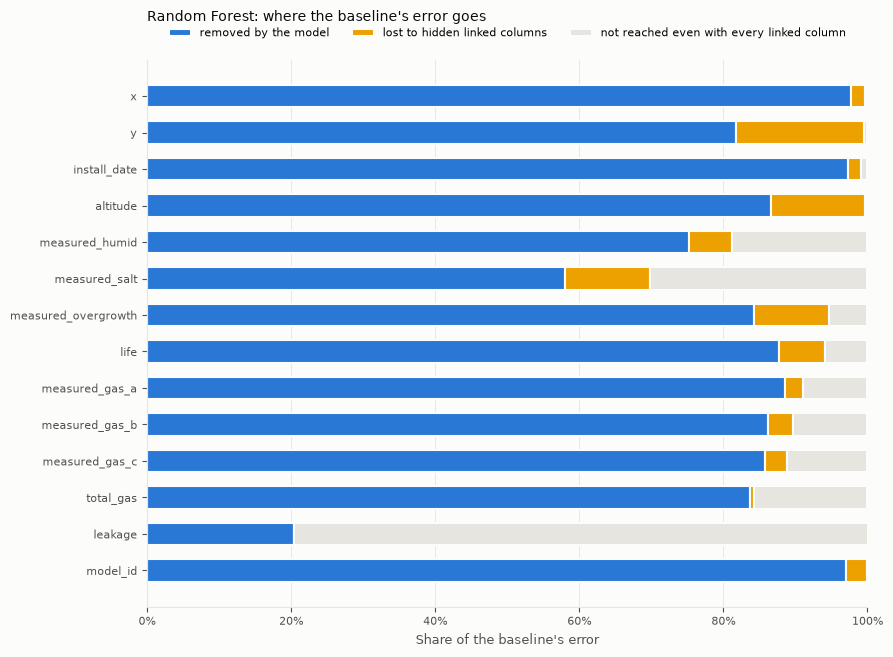

**Figure 8.1a.** Random Forest: share of the baseline's error removed, lost to hidden linked columns, and not reached with every linked column visible.

**Table 8.1a.** Random Forest: values of Figure 8.1a.

,skill over all hidden cells,skill with every linked column visible,cells with every linked column visible,lost to hidden linked columns,not reached even with every linked column
target,,,,,
x,0.978,0.996,1297.0,0.019,0.004
y,0.817,0.996,1031.0,0.179,0.004
install_date,0.973,0.991,430.0,0.018,0.009
altitude,0.866,0.997,1042.0,0.131,0.003
measured_humid,0.753,0.812,1007.0,0.060,0.188
measured_salt,0.580,0.698,1002.0,0.119,0.302
measured_overgrowth,0.842,0.946,1021.0,0.104,0.054
life,0.877,0.941,537.0,0.064,0.059
measured_gas_a,0.885,0.910,854.0,0.025,0.090


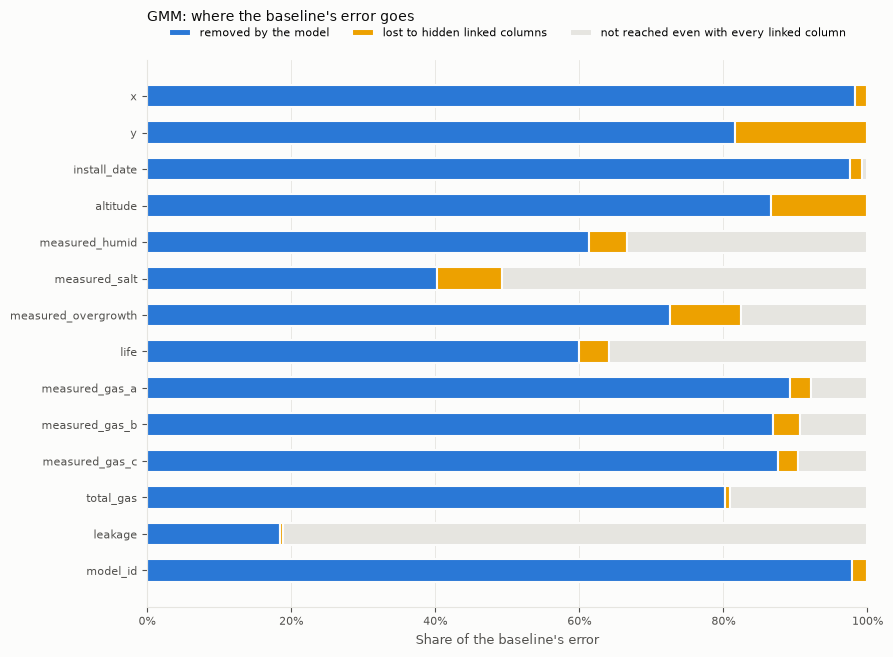

**Figure 8.1b.** GMM: share of the baseline's error removed, lost to hidden linked columns, and not reached with every linked column visible.

**Table 8.1b.** GMM: values of Figure 8.1b.

,skill over all hidden cells,skill with every linked column visible,cells with every linked column visible,lost to hidden linked columns,not reached even with every linked column
target,,,,,
x,0.982,0.999,1297.0,0.016,0.001
y,0.816,0.999,1031.0,0.182,0.001
install_date,0.976,0.993,430.0,0.017,0.007
altitude,0.867,1.000,1042.0,0.133,0.000
measured_humid,0.614,0.666,1007.0,0.052,0.334
measured_salt,0.403,0.493,1002.0,0.091,0.507
measured_overgrowth,0.726,0.824,1021.0,0.098,0.176
life,0.600,0.641,537.0,0.041,0.359
measured_gas_a,0.892,0.921,854.0,0.029,0.079


**Table 8.1c.** MAE of the baseline, the main models and the generator's formula on hidden cells whose defining inputs are visible, `completion0.8-noise0.0`.

,method,Median,Random Forest,GMM,Formula
relation,n,,,,
altitude from x and y,1308,34.024,0.095,0.011,0.000
x from altitude and y,1299,24.711,0.246,0.093,0.000
y from altitude and x,1278,25.280,0.107,0.025,0.000
total_gas from gas readings,1030,1109.235,25.819,28.198,0.000
gas a from total and other readings,1018,1248.808,24.961,47.850,0.000
overgrowth from humidity and salt,1244,0.307,0.008,0.054,0.000
life from all its inputs,537,294.559,12.748,100.565,0.000
"leakage from gases, date and model",608,0.097,0.073,0.075,0.065


**Table 8.1d.** MAE of the baseline, the main models and the generator's formula on hidden cells whose defining inputs are visible, `completion0.8-noise0.05`.

,method,Median,Random Forest,GMM,Formula
relation,n,,,,
altitude from x and y,1308,34.024,0.095,0.010,0.000
x from altitude and y,1299,24.711,0.305,0.081,0.000
y from altitude and x,1278,25.280,0.107,0.022,0.000
total_gas from gas readings,1030,1109.235,176.383,209.848,387.321
gas a from total and other readings,1018,1251.182,114.630,97.142,322.255
overgrowth from humidity and salt,1244,0.307,0.017,0.055,0.015
life from all its inputs,537,294.559,17.279,105.806,8.484
"leakage from gases, date and model",608,0.097,0.079,0.080,NaN


**Table 8.1e.** MAE of the baseline, the main models and the generator's formula on hidden cells whose defining inputs are visible, `completion0.8-noise0.1`.

,method,Median,Random Forest,GMM,Formula
relation,n,,,,
altitude from x and y,1308,34.024,0.100,0.008,0.000
x from altitude and y,1299,24.711,0.344,0.085,0.000
y from altitude and x,1278,25.280,0.103,0.020,0.000
total_gas from gas readings,1030,1109.235,196.134,236.173,774.642
gas a from total and other readings,1018,1251.807,142.455,117.027,644.510
overgrowth from humidity and salt,1244,0.307,0.027,0.059,0.030
life from all its inputs,537,294.559,23.994,107.427,16.969
"leakage from gases, date and model",608,0.097,0.080,0.082,NaN


**Table 8.1f.** Share of each column explained by the other true columns, against the skill reached.

,target,R2 from all other true columns,"best R2, representative scenario","best R2, easiest scenario"
0,x,1.000,0.996,1.000
1,y,0.999,0.833,0.924
2,install_date,1.000,0.996,0.999
3,altitude,1.000,0.920,0.965
4,measured_humid,0.954,0.883,0.939
5,measured_salt,0.894,0.694,0.804
6,measured_overgrowth,0.999,0.928,0.977
7,life,0.995,0.953,0.990
8,random_placebo,-0.104,-0.008,-0.002
9,measured_gas_a,0.999,0.964,0.995


In [41]:
# Where the baseline's error goes, the generator's formula as a reference, and what the true columns could explain.
parts = ["removed by the model", "lost to hidden linked columns", "not reached even with every linked column"]
for method in MAIN:
    label = f"8.1{LETTER[method]}"
    information = STUDY.information[method].rename(columns={"skill over all hidden cells": "removed by the model"})
    fg.plot_stacked(information, parts, [fg.SERIES[0], fg.SERIES[3], fg.GRID], f"{method}: where the baseline's error goes",
                    FIGURES, f"error_split_{FILE[method]}", "Share of the baseline's error")
    fg.caption(f"Figure {label}", f"{method}: share of the baseline's error removed, lost to hidden linked columns, "
               "and not reached with every linked column visible.")
    fg.table(f"Table {label}", f"{method}: values of Figure {label}.", STUDY.information[method].round(3))
for letter, scenario in zip("cde", (NOISE_FREE, REPRESENTATIVE, HIGH_NOISE)):
    fg.table(f"Table 8.1{letter}", f"MAE of the baseline, the main models and the generator's formula on hidden cells "
             f"whose defining inputs are visible, `{scenario}`.",
             rel.relation_matrix(STUDY.relations, scenario)[COMPARED + [rel.FORMULA]].round(3))
fg.table("Table 8.1f", "Share of each column explained by the other true columns, against the skill reached.",
         STUDY.recoverable.round(3))


### 8.2 Reliance on linked columns

If hidden linked columns cause the decline in section 6.6, models should rely on those columns when they are visible. This is tested with single-target random forest and CatBoost models, because a chain covers every column at once and the influence of one column on one target cannot be read from it. Each predictor is shuffled in held-out rows (permutation importance; Breiman, 2001) and the added error is measured against observed labels, so truth is not used. A value of 1 means that shuffling cost as much as replacing the model with a constant.

Table 8.2a places every column a model relies on (importance above 0.02) within the generator's definition:

- **direct:** the target is computed from it, or it is computed from the target.
- **defines a column together with the target:** for example `x` and `y`, which together define `altitude`.
- **linked through another column:** for example `altitude` and `install_date`, both computed from `x` and `y`.
- **stands in for a near copy:** `x` and `install_date` are near copies, so one can replace the other.
- **no link:** the definition gives no connection.

Table 8.2b lists the strongest columns relied on outside the target's definition. Figure 8.2 shows all values for the single-target random forest, with direct links in bold.


**Table 8.2a.** Columns relied on (importance above 0.02), by their link to the target in the generator's definition.

method                                                          Random Forest                                                              CatBoost                                               
scenario                                               completion0.8-noise0.0 completion0.8-noise0.05 completion0.8-noise0.1 completion0.8-noise0.0 completion0.8-noise0.05 completion0.8-noise0.1
direct links                                                           54.000                  54.000                 54.000                 54.000                  54.000                 54.000
direct links relied on                                                  0.741                   0.648                  0.630                  0.833                   0.778                  0.741
columns relied on                                                      73.000                  65.000                 63.000                 83.000                  78.000                 77.000
of those: direct                                                        0.548                   0.538                  0.540                  0.542                   0.538                  0.519
of those: defines a column together with the target                     0.164                   0.200                  0.206                  0.157                   0.179                  0.195
of those: linked through another column                                 0.274                   0.246                  0.238                  0.289                   0.269                  0.273
of those: stands in for a near copy of a linked column                  0.014                   0.015                  0.016                  0.012                   0.013                  0.013
of those: no link                                                       0.000                   0.000                  0.000                  0.000                   0.000                  0.000

**Table 8.2b.** Strongest columns relied on outside the target's definition, single-target Random Forest.

,target,predictor,importance,link
0,total_gas,x,0.390315,linked through another column
1,altitude,install_date,0.381624,linked through another column
2,x,total_gas,0.288230,linked through another column
3,leakage,total_gas,0.252687,linked through another column
4,measured_gas_a,x,0.135912,linked through another column
5,leakage,x,0.116884,stands in for a near copy of a linked column
6,life,measured_gas_b,0.087981,linked through another column
7,life,x,0.086260,linked through another column
8,measured_gas_c,x,0.080675,linked through another column
9,life,measured_gas_c,0.080065,linked through another column


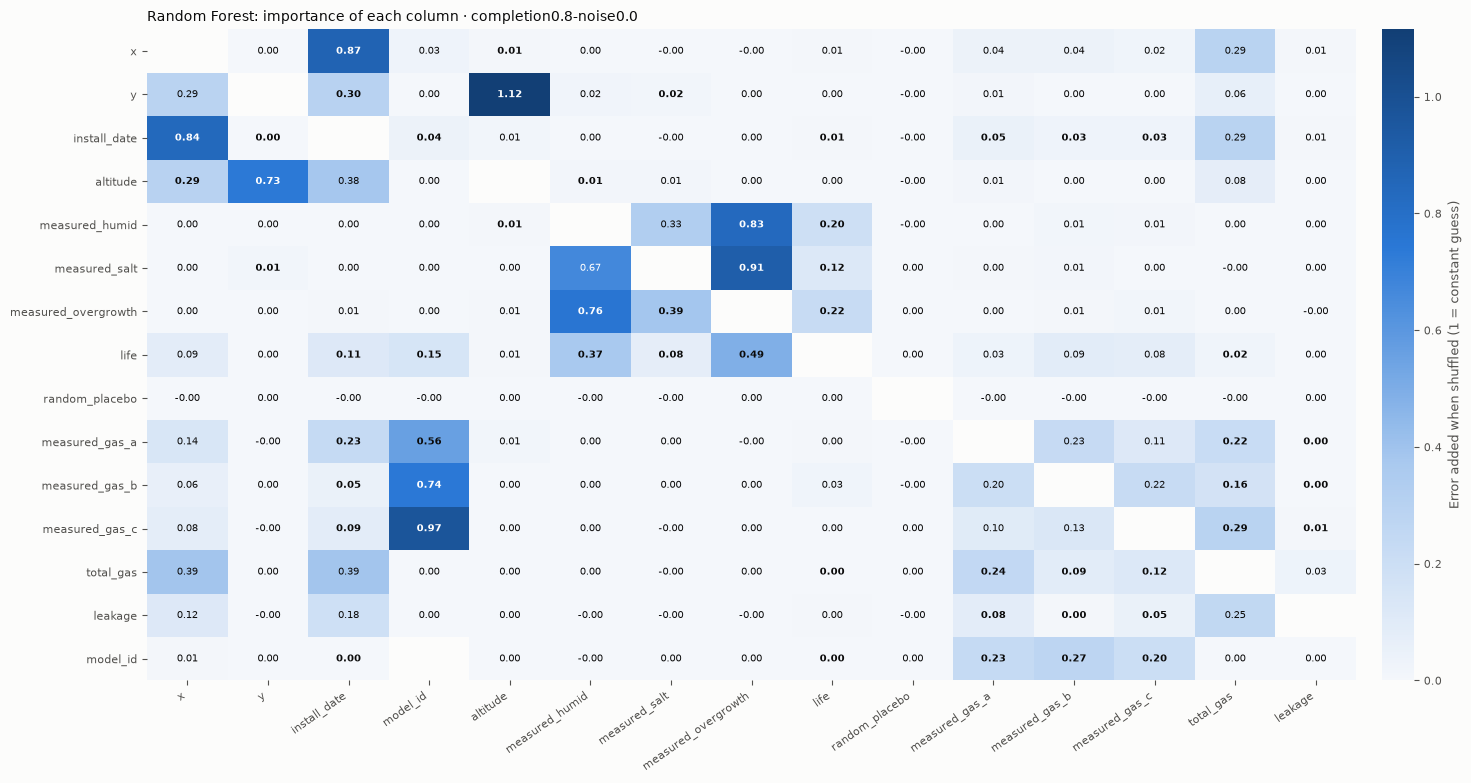

**Figure 8.2.** Permutation importance of each predictor for each target, single-target Random Forest, `completion0.8-noise0.0`; direct links are in bold.

In [42]:
# Columns the single-target models rely on, placed within the generator's definition.
with pd.option_context("display.max_colwidth", 60):
    fg.table("Table 8.2a", "Columns relied on (importance above 0.02), by their link to the target in the generator's definition.",
             STUDY.links.set_index(["method", "scenario"]).round(3).T)
    fg.table("Table 8.2b", f"Strongest columns relied on outside the target's definition, single-target {STUDY.explainer}.",
             STUDY.unexplained)
fg.plot_importance(ev.importance_matrix(STUDY.importance_means, NOISE_FREE, STUDY.explainer),
                   f"{STUDY.explainer}: importance of each column · {NOISE_FREE}", FIGURES, "importance")
fg.caption("Figure 8.2", f"Permutation importance of each predictor for each target, single-target {STUDY.explainer}, "
           f"`{NOISE_FREE}`; direct links are in bold.")


### 8.3 Propagated noise

Noise can reach an estimate in two ways: through the column's own visible values, from which the model learns, and through the linked columns it reads. Tables 8.3a and 8.3b give both, as the mean measurement error at the highest noise level in units of the column's standard deviation, beside the change in the model's error on the same cells.

`total_gas`, `life` and `model_id` are exact by design; if their error still rises with noise, the noise was carried in from linked columns. Figures 8.3a and 8.3b plot the change in error against the largest noise reaching a column by either path.


**Table 8.3a.** Random Forest: measurement noise in the column and in its linked columns at the highest noise level, and the change in error.

,target,noise in the column itself,mean noise in its linked columns,largest noise in a linked column,error change from noise,skill at the lowest noise,skill at the highest noise,largest noise reaching the column
0,x,0.000,0.000,0.000,0.334,0.981,0.975,0.000
1,y,0.000,0.028,0.084,0.018,0.819,0.816,0.084
2,install_date,0.000,0.192,0.430,0.208,0.976,0.970,0.430
3,altitude,0.000,0.027,0.080,0.014,0.867,0.865,0.080
4,measured_humid,0.080,0.015,0.046,0.117,0.763,0.735,0.080
5,measured_salt,0.084,0.015,0.046,0.188,0.611,0.538,0.084
6,measured_overgrowth,0.046,0.055,0.084,0.295,0.862,0.821,0.084
7,life,0.000,0.042,0.084,0.538,0.902,0.849,0.084
8,measured_gas_a,0.331,0.000,0.000,0.921,0.928,0.861,0.331
9,measured_gas_b,0.392,0.000,0.000,0.804,0.909,0.834,0.392


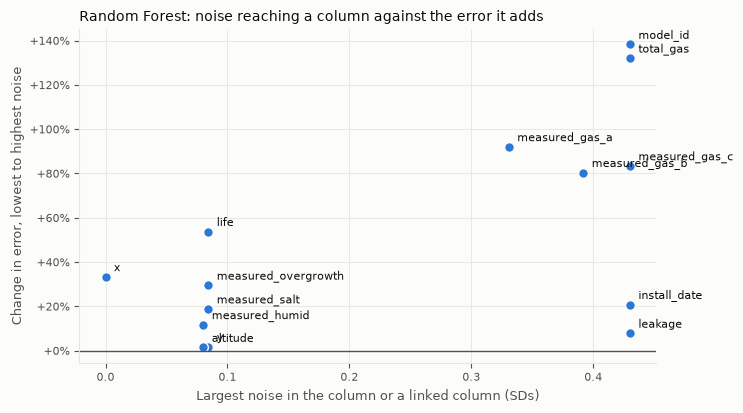

**Figure 8.3a.** Random Forest: change in error from the lowest to the highest noise against the largest noise reaching the column.

**Table 8.3b.** GMM: measurement noise in the column and in its linked columns at the highest noise level, and the change in error.

,target,noise in the column itself,mean noise in its linked columns,largest noise in a linked column,error change from noise,skill at the lowest noise,skill at the highest noise,largest noise reaching the column
0,x,0.000,0.000,0.000,0.061,0.983,0.982,0.000
1,y,0.000,0.028,0.084,0.004,0.816,0.815,0.084
2,install_date,0.000,0.192,0.430,0.038,0.976,0.976,0.430
3,altitude,0.000,0.027,0.080,0.009,0.867,0.865,0.080
4,measured_humid,0.080,0.015,0.046,0.031,0.618,0.606,0.080
5,measured_salt,0.084,0.015,0.046,0.051,0.411,0.382,0.084
6,measured_overgrowth,0.046,0.055,0.084,0.048,0.731,0.718,0.084
7,life,0.000,0.042,0.084,0.045,0.612,0.594,0.084
8,measured_gas_a,0.331,0.000,0.000,0.479,0.918,0.878,0.331
9,measured_gas_b,0.392,0.000,0.000,0.346,0.895,0.858,0.392


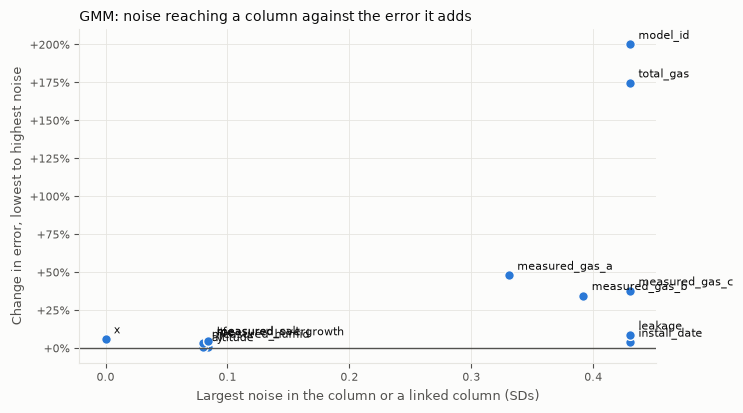

**Figure 8.3b.** GMM: change in error from the lowest to the highest noise against the largest noise reaching the column.

In [43]:
# Noise in a column and in its linked columns, against the error the model adds as noise rises.
for method in MAIN:
    label = f"8.3{LETTER[method]}"
    noise = STUDY.noise[method].copy()
    noise["largest noise reaching the column"] = noise[["noise in the column itself", "largest noise in a linked column"]].max(axis=1)
    fg.table(f"Table {label}", f"{method}: measurement noise in the column and in its linked columns at the highest noise "
             "level, and the change in error.", noise.round(3))
    fg.plot_scatter(noise, "largest noise reaching the column", "error change from noise", "target",
                    f"{method}: noise reaching a column against the error it adds", FIGURES, f"noise_carried_{FILE[method]}",
                    "Largest noise in the column or a linked column (SDs)", "Change in error, lowest to highest noise")
    fg.caption(f"Figure {label}", f"{method}: change in error from the lowest to the highest noise against the largest "
               "noise reaching the column.")


### 8.4 Removal of predictor blocks

Each block of columns is removed according to what it measures, and the chained models are refitted. Figures 8.4a and 8.4b give the relative change in error, so a positive value means that the block carried information for the target; cells are empty for targets inside the removed block. Table 8.4 gives the skill after each removal.

A large change identifies the block a target depends on. A small change after removing a directly linked block means that another column took its place, as a near copy can.


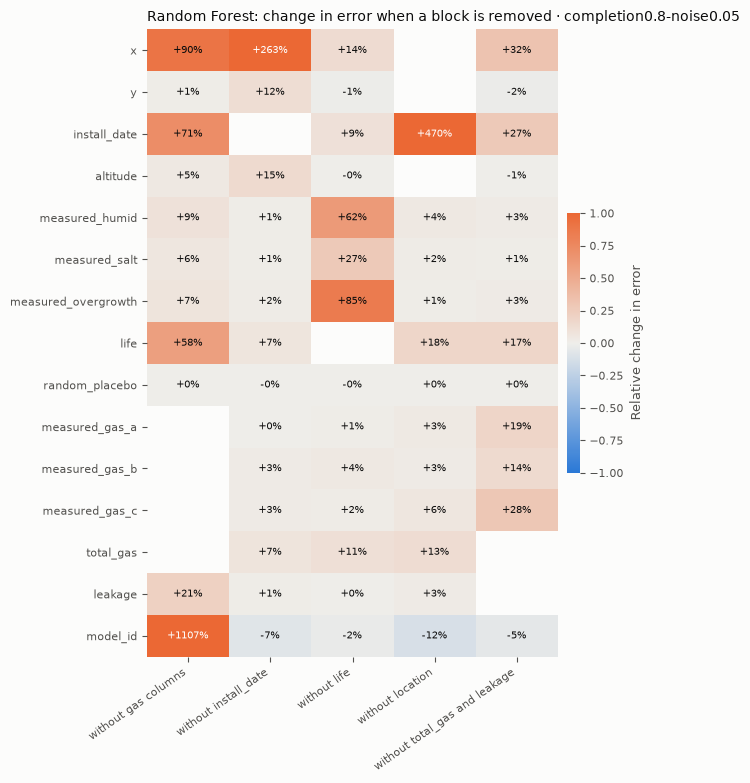

**Figure 8.4a.** Random Forest: relative change in MAE when each block of predictors is removed, `completion0.8-noise0.05`.

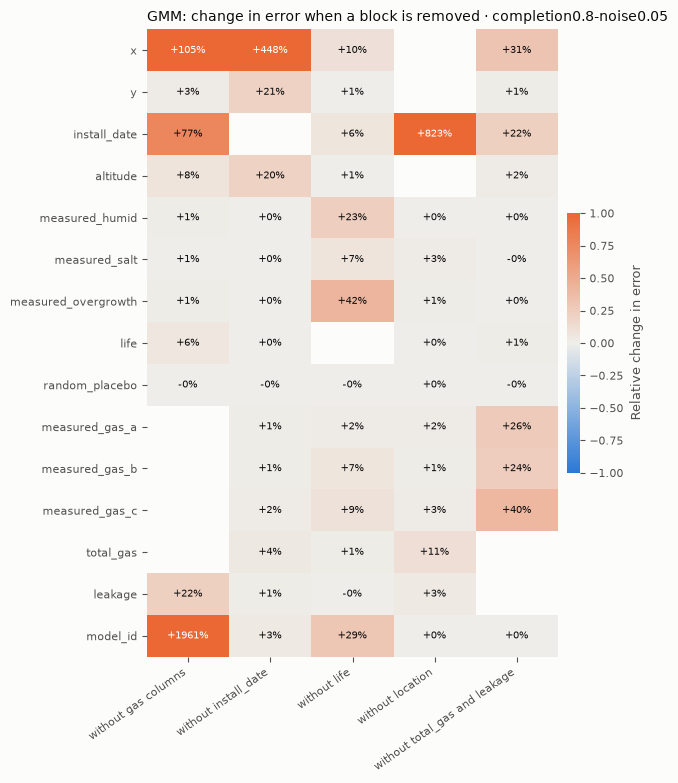

**Figure 8.4b.** GMM: relative change in MAE when each block of predictors is removed, `completion0.8-noise0.05`.

**Table 8.4.** Skill of the main models after each block of predictors is removed, `completion0.8-noise0.05`.

method                                               GMM  Random Forest
target              variant                                            
altitude            without gas columns            0.856          0.859
                    without install_date           0.839          0.846
                    without life                   0.866          0.866
                    without total_gas and leakage  0.864          0.867
install_date        without gas columns            0.958          0.953
                    without life                   0.975          0.970
                    without location               0.779          0.843
                    without total_gas and leakage  0.971          0.965
leakage             without gas columns            0.002          0.035
                    without install_date           0.175          0.195
                    without life                   0.186          0.203
                    without location               0.159          0.182
life                without gas columns            0.577          0.807
                    without install_date           0.600          0.869
                    without location               0.598          0.856
                    without total_gas and leakage  0.596          0.856
measured_gas_a      without install_date           0.891          0.885
                    without life                   0.891          0.884
                    without location               0.891          0.881
                    without total_gas and leakage  0.864          0.864
measured_gas_b      without install_date           0.867          0.859
                    without life                   0.860          0.856
                    without location               0.867          0.859
                    without total_gas and leakage  0.836          0.843
measured_gas_c      without install_date           0.873          0.853
                    without life                   0.864          0.854
                    without location               0.873          0.849
                    without total_gas and leakage  0.825          0.817
measured_humid      without gas columns            0.609          0.731
                    without install_date           0.613          0.751
                    without life                   0.523          0.599
                    without location               0.612          0.742
                    without total_gas and leakage  0.613          0.746
measured_overgrowth without gas columns            0.723          0.831
                    without install_date           0.725          0.839
                    without life                   0.612          0.708
                    without location               0.723          0.840
                    without total_gas and leakage  0.726          0.837
measured_salt       without gas columns            0.398          0.554
                    without install_date           0.402          0.575
                    without life                   0.360          0.467
                    without location               0.387          0.570
                    without total_gas and leakage  0.404          0.574
model_id            without gas columns            0.548          0.641
                    without install_date           0.977          0.972
                    without life                   0.972          0.971
                    without location               0.978          0.974
                    without total_gas and leakage  0.978          0.972
random_placebo      without gas columns           -0.002         -0.020
                    without install_date          -0.003         -0.013
                    without life                  -0.003         -0.014
                    without location              -0.003         -0.017
                    without total_gas and leakage -0.003         -0.018
total_gas           without install_date

In [44]:
# Change in error when one block of predictors is removed and the model refitted.
removed = STUDY.ablation[STUDY.ablation.scenario.eq(REPRESENTATIVE)]
for method in MAIN:
    matrix = removed[removed.method.eq(method)].pivot(index="target", columns="variant", values="relative change").reindex(list(TARGETS))
    fg.plot_heatmap(matrix, f"{method}: change in error when a block is removed · {REPRESENTATIVE}", FIGURES,
                    f"ablation_{FILE[method]}", "Relative change in error", center=0.0, limit=1.0, fmt="{:+.0%}")
    fg.caption(f"Figure 8.4{LETTER[method]}", f"{method}: relative change in MAE when each block of predictors is removed, "
               f"`{REPRESENTATIVE}`.")
fg.table("Table 8.4", f"Skill of the main models after each block of predictors is removed, `{REPRESENTATIVE}`.",
         removed[removed.method.isin(MAIN)].pivot_table(index=["target", "variant"], columns="method", values="skill without").round(3))


### 8.5 Model structure

KNN, Random Forest, HistGradientBoosting and CatBoost share the ridge base, so part of their agreement may come from that structure. Figure 8.5 shows each model's skill without the ridge base (open marker) and with it (filled marker) in the representative scenario; Table 8.5a adds the two references, the ridge alone and the boosted chain without the ridge.

Table 8.5b gives the mean skill by kind of relationship for each structure. Where the ridge raises a local model, the local model approximates that relationship poorly on its own; where all structures agree, the limit lies in the data.


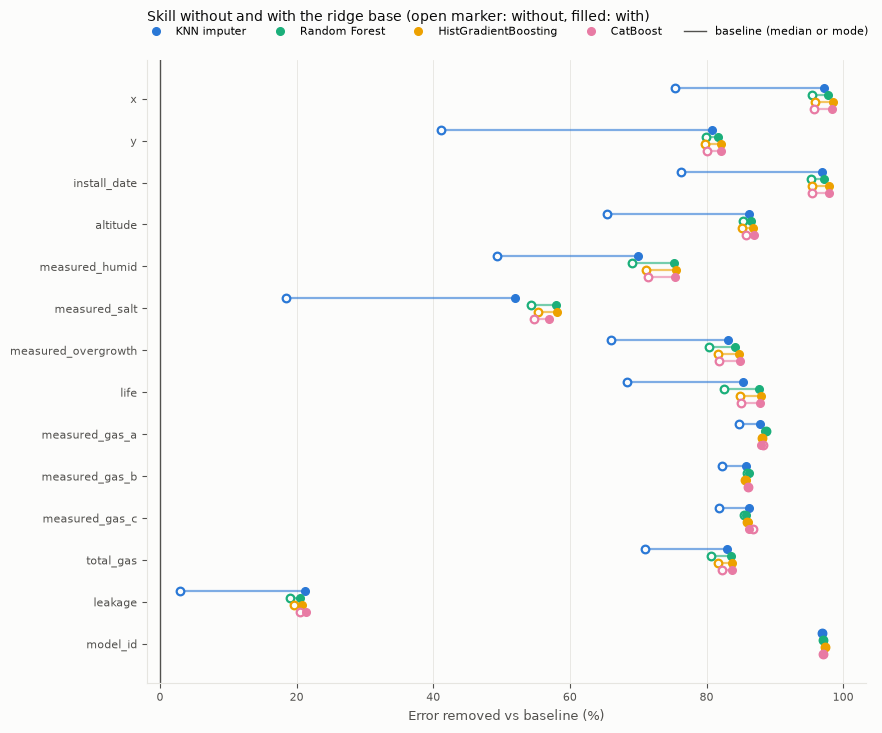

**Figure 8.5.** Skill of each chained model without (open marker) and with (filled marker) the ridge base, `completion0.8-noise0.05`.

**Table 8.5a.** Skill on each column of every structure, with the ridge alone and the boosted chain as references.

,KNN imputer: no ridge,KNN imputer: with ridge,Random Forest: no ridge,Random Forest: with ridge,HistGradientBoosting: no ridge,HistGradientBoosting: with ridge,CatBoost: no ridge,CatBoost: with ridge,IterativeImputer (ridge only),miceforest direct (boosted chain without the ridge)
x,0.754,0.973,0.954,0.978,0.958,0.985,0.958,0.984,0.970,0.953
y,0.411,0.809,0.799,0.817,0.797,0.821,0.801,0.822,0.781,0.785
install_date,0.762,0.969,0.953,0.973,0.955,0.980,0.954,0.979,0.967,0.949
altitude,0.654,0.861,0.854,0.866,0.852,0.868,0.858,0.869,0.843,0.849
measured_humid,0.494,0.700,0.692,0.753,0.711,0.755,0.715,0.754,0.663,0.722
measured_salt,0.185,0.520,0.543,0.580,0.553,0.581,0.548,0.570,0.466,0.549
measured_overgrowth,0.660,0.832,0.804,0.842,0.817,0.848,0.819,0.850,0.806,0.813
life,0.684,0.854,0.826,0.877,0.850,0.880,0.850,0.878,0.804,0.847
random_placebo,-0.011,-0.013,-0.014,-0.016,-0.005,-0.008,0.001,-0.006,-0.006,-0.010
measured_gas_a,0.848,0.879,0.887,0.885,0.881,0.882,0.883,0.880,0.867,0.885


**Table 8.5b.** Mean skill of every structure by kind of relationship.

,KNN imputer: no ridge,KNN imputer: with ridge,Random Forest: no ridge,Random Forest: with ridge,HistGradientBoosting: no ridge,HistGradientBoosting: with ridge,CatBoost: no ridge,CatBoost: with ridge,IterativeImputer (ridge only),miceforest direct (boosted chain without the ridge)
kind,,,,,,,,,,
near copy of another column,0.758,0.971,0.953,0.975,0.957,0.982,0.956,0.981,0.968,0.951
exact sum,0.592,0.833,0.820,0.840,0.822,0.842,0.827,0.843,0.817,0.818
random draw scaled by another column,0.339,0.610,0.617,0.666,0.632,0.668,0.632,0.662,0.564,0.636
threshold,0.660,0.832,0.804,0.842,0.817,0.848,0.819,0.850,0.806,0.813
product that depends on the model,0.684,0.854,0.826,0.877,0.850,0.880,0.850,0.878,0.804,0.847
no relationship,-0.011,-0.013,-0.014,-0.016,-0.005,-0.008,0.001,-0.006,-0.006,-0.010
decline that depends on the model,0.830,0.866,0.867,0.868,0.866,0.867,0.870,0.868,0.851,0.867
"independent draw, seen only through its effects",0.029,0.213,0.191,0.205,0.197,0.208,0.205,0.214,0.208,0.193
category drawn from a moving window,0.970,0.970,0.970,0.970,0.973,0.973,0.971,0.971,NaN,0.977


In [45]:
# Skill of the chained models with and without the ridge base.
structure = STUDY.structure.drop(index="random_placebo")
pairs = [(m, f"{m}: no ridge", f"{m}: with ridge", fg.METHOD_COLORS[m]) for m in SHOWN if f"{m}: no ridge" in structure]
fg.plot_pairs(structure, pairs, "Skill without and with the ridge base", FIGURES, "ridge_base_effect", "Error removed vs baseline (%)")
fg.caption("Figure 8.5", f"Skill of each chained model without (open marker) and with (filled marker) the ridge base, "
           f"`{REPRESENTATIVE}`.")
fg.table("Table 8.5a", "Skill on each column of every structure, with the ridge alone and the boosted chain as references.",
         STUDY.structure.round(3))
by_kind = STUDY.structure.assign(kind=[fl.KIND_OF[t] for t in STUDY.structure.index]).groupby("kind", sort=False).mean()
with pd.option_context("display.max_colwidth", 60):
    fg.table("Table 8.5b", "Mean skill of every structure by kind of relationship.", by_kind.round(3))


### 8.6 Validity checks

Three checks test whether the results could be artefacts of the evaluation.

- **Leakage.** Table 8.6a counts predictions made for a visible cell or by a model that saw the row, and hidden cells not predicted exactly once. Every count should be 0.
- **Spurious structure.** `random_placebo` is unrelated to every other column, so a model that beats the baseline on it would be fitting structure that does not exist. Tables 8.6b and 8.6c give its skill in every scenario and its importance as a predictor.
- **Fold split.** The representative scenario is repeated with two further fold seeds; Table 8.6d gives the mean skill for each seed.


In [46]:
# Leakage counts, the negative control and the fold-seed check.
fg.table("Table 8.6a", "Leakage checks: predictions for visible cells, predictions by a model that saw the row, "
         "and hidden cells not predicted exactly once.", STUDY.integrity)
placebo = STUDY.by_scenario[STUDY.by_scenario.target.eq("random_placebo")]
fg.table("Table 8.6b", "Skill on `random_placebo` in every scenario.",
         placebo.pivot(index="method", columns="scenario", values="skill").round(4))
fg.table("Table 8.6c", "Permutation importance of `random_placebo` as a predictor.", STUDY.placebo_importance.round(4))
fg.table("Table 8.6d", "Mean skill for each fold seed, representative scenario.", STUDY.seed_skill.round(4))


**Table 8.6a.** Leakage checks: predictions for visible cells, predictions by a model that saw the row, and hidden cells not predicted exactly once.

,check,count,expected
0,Predictions for cells that were visible,0,0
1,Predicted rows outside the held-out fold,0,0
2,Cells predicted more than once by a method,0,0
3,Method and target groups that do not cover every hidden cell,0,0


**Table 8.6b.** Skill on `random_placebo` in every scenario.

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
CatBoost,-0.0050,-0.0049,-0.0037,-0.0060,-0.0062,-0.0061,-0.0017,-0.0017,-0.0008
GMM,-0.0015,-0.0010,-0.0009,-0.0027,-0.0032,-0.0027,-0.0016,-0.0017,-0.0011
HistGradientBoosting,-0.0052,-0.0079,-0.0074,-0.0079,-0.0082,-0.0059,-0.0007,-0.0003,-0.0006
IterativeImputer,-0.0038,-0.0033,-0.0022,-0.0056,-0.0056,-0.0052,-0.0026,-0.0010,-0.0003
KNN imputer,-0.0108,-0.0119,-0.0141,-0.0131,-0.0133,-0.0142,-0.0058,-0.0021,-0.0028
LightGBM chained,-0.0104,-0.0115,-0.0163,-0.0139,-0.0120,-0.0153,-0.0027,-0.0048,-0.0029
MICE-PMM,-0.0684,-0.0589,-0.0825,-0.0820,-0.0495,-0.0798,-0.0647,-0.0605,-0.0568
Masked MLP,-0.0071,-0.0073,-0.0072,-0.0074,-0.0081,-0.0083,-0.0067,-0.0048,-0.0034
Predictive MissForest,-0.0073,-0.0079,-0.0064,-0.0079,-0.0059,-0.0077,0.0001,-0.0050,-0.0038


**Table 8.6c.** Permutation importance of `random_placebo` as a predictor.

mean     max
method        scenario                               
CatBoost      completion0.8-noise0.0   0.0002  0.0051
              completion0.8-noise0.05  0.0001  0.0037
              completion0.8-noise0.1   0.0001  0.0050
Random Forest completion0.8-noise0.0   0.0001  0.0045
              completion0.8-noise0.05 -0.0000  0.0044
              completion0.8-noise0.1   0.0000  0.0041

**Table 8.6d.** Mean skill for each fold seed, representative scenario.

seed,219,220,221
method,,,
CatBoost,0.8094,0.8084,0.8078
GMM,0.7560,0.7559,0.7558
HistGradientBoosting,0.8097,0.8107,0.8103
IterativeImputer,0.7605,0.7586,0.7604
KNN imputer,0.7949,0.7946,0.7934
LightGBM chained,0.7897,0.7889,0.7904
MICE-PMM,0.7125,0.7121,0.7116
Masked MLP,0.7258,0.7234,0.7230
Predictive MissForest,0.7394,0.7369,0.7378


## 9. Value for downstream analysis

An analysis restricted to complete rows loses most of the table. Table 9.1 counts the rows without a missing cell in every scenario.

Table 9.2 compares eight summary values that an asset analysis might draw from the table, such as mean `life` by equipment model and the share of assets with low `life`. Each is computed from the truth and from several versions of the representative scenario:

- **rows with no missing cell:** the rows an analysis without imputation would use.
- **Median and Mode:** the baseline fill.
- **Random Forest and GMM:** the completed table of each main model, with out-of-fold values.
- **measured values with true values in the gaps:** a perfect imputation, whose error comes from measurement noise alone.

Values are relative errors against the truth. Table 9.3 gives the mean absolute relative error for the scenarios of section 2.5.


In [47]:
# Complete rows, and summary values of an asset analysis from each version of the table, against the truth.
fg.table("Table 9.1", "Rows without a missing cell in every scenario.",
         fl.complete_rows_table(STUDY.measured, STUDY.scenarios).round(3))
downstream = STUDY.downstream
order = ["rows with no missing cell", "Median and Mode"] + MAIN + ["measured values with true values in the gaps"]
with pd.option_context("display.max_colwidth", 60):
    fg.table("Table 9.2", f"Relative error of eight summary values against the truth, `{REPRESENTATIVE}`.",
             downstream.pivot(index="quantity", columns="source", values="relative error")[order].round(4))
fg.table("Table 9.3", "Mean absolute relative error of the summary values in each scenario.",
         STUDY.downstream_by_scenario.reindex(order).round(4))


**Table 9.1.** Rows without a missing cell in every scenario.

,scenario,mechanism,rows,rows with no missing cell,share of rows,share of cells visible
0,completion0.7-noise0.0,random,10000,48,0.005,0.700
1,completion0.7-noise0.05,random,10000,48,0.005,0.700
2,completion0.7-noise0.1,random,10000,48,0.005,0.700
3,completion0.8-noise0.0,random,10000,348,0.035,0.800
4,completion0.8-noise0.05,random,10000,348,0.035,0.800
5,completion0.8-noise0.1,random,10000,348,0.035,0.800
6,completion0.9-noise0.0,random,10000,2064,0.206,0.901
7,completion0.9-noise0.05,random,10000,2064,0.206,0.901
8,completion0.9-noise0.1,random,10000,2064,0.206,0.901
9,completion0.8-noise0.05-age,age,10000,603,0.060,0.801


**Table 9.2.** Relative error of eight summary values against the truth, `completion0.8-noise0.05`.

source,rows with no missing cell,Median and Mode,Random Forest,GMM,measured values with true values in the gaps
quantity,,,,,
90th percentile of overgrowth,0.0396,-0.0728,-0.0009,-0.0183,0.0032
life lost per day installed,-0.1556,-0.1479,0.0047,0.0114,0.0000
"mean life, model 0",-0.0001,-0.0002,0.0000,0.0000,0.0000
"mean life, model 1",-0.0009,0.0001,0.0000,0.0000,0.0000
"mean life, model 2",-0.0001,0.0005,0.0000,0.0000,0.0000
"mean life, model 3",0.0004,0.0000,-0.0000,-0.0000,0.0000
share of assets with life below the lowest tenth,0.0632,-0.1910,-0.0040,-0.0370,0.0000
spread of total gas (SD),-0.0072,-0.1116,-0.0041,-0.0058,0.0000


**Table 9.3.** Mean absolute relative error of the summary values in each scenario.

,completion0.8-noise0.05,completion0.8-noise0.05-age,completion0.8-noise0.05-value,completion0.8-noise0.05-group,completion0.8-noise0.05-errors,completion0.5-noise0.05-sparse,completion0.3-noise0.05-sparse
source,,,,,,,
rows with no missing cell,0.0334,0.2433,0.0443,0.0336,0.0344,NaN,NaN
Median and Mode,0.0655,0.0590,0.0417,0.0731,0.0655,0.1947,0.2961
Random Forest,0.0017,0.0023,0.0034,0.0074,0.0026,0.0281,0.0802
GMM,0.0091,0.0065,0.0111,0.0101,0.0093,0.0443,0.1344
measured values with true values in the gaps,0.0004,0.0003,0.0005,0.0004,0.0005,0.0005,0.0005


## 10. Limitations

**Data**

- The data is synthetic, with one generated truth table, so variation between generated datasets is not measured.
- `x` and `install_date` are near copies, because assets were installed in grid order; high skill on these columns says little about model quality.
- `life`, `total_gas` and `leakage` are exact by design, so results for and from these columns are better than noisy measurements would allow.
- A noise level does not imply equal difficulty across columns; section 8.3 gives each column's noise in units of its spread.
- The scenarios of section 2.5 are simple forms of missingness and error, each run at noise 0.05 with one draw of masks or errors.

**Design**

- All development used this one dataset. Settings never saw a hidden cell, but no independent dataset was held back.
- Shared settings were chosen on three scenarios and may not be optimal elsewhere. The search covered a fixed list of candidates and does not establish any model's ceiling.
- The candidates were written with knowledge of how the data was generated. Models receive no relationships and a fixed rule made the choice, but second-order terms were offered because such relationships were expected.
- Bootstrap intervals are conditional on the fitted models, and neighbouring grid rows are related, so the intervals may be too narrow.
- Importance comes from single-target models, not from the scored chains; the predictor removal in section 8.4 tests the chains directly.

**Models**

- The five models in `vendor/` run through an adapter under the same folds, data and scoring as the others. Parts of their code that encode the generator are switched off (the gas-decay feature, the spatial installation-day feature, exact formulas and placebo blanking), so their results differ from those reported with their source code.
- MICE-PMM was written to complete a whole table; here it is fitted on training rows only, so its results differ from whole-table results.
- The settings of GMM and the masked MLP come from the selection rule applied to their documented search space; the masked MLP was still improving when selection stopped.
- The range limit of the chained models was added after they diverged at 0.3 completion, where raw estimates reached three column spans outside the range of the truth and one task failed on infinite values. Their settings were chosen before the limit existed, on scenarios where it rarely applies.
- KNN, Random Forest, HistGradientBoosting and CatBoost share the ridge base, so their agreement may partly reflect that structure (section 8.5).
- A chained model trains on estimates that used the row's own label, which is unavailable for a hidden cell. Removing this effect improved the selection score by 0.25%, so the simpler form was kept.
- Numeric estimates are single values; methods that return a range of plausible values are not tested.
- IterativeImputer can stop at its pass limit before converging; section 4.3 reports how often and the effect of other limits.


## Appendix

### A.1 Pairwise comparisons

Table A.1a gives the best model for each column; `lead` is `clear` when the gap to the next model is both statistically separated and at least 5%. Figure A.1 compares every model with the baseline on the same cells, with 95% row-bootstrap intervals (Efron & Tibshirani, 1993); the intervals resample rows for fitted models and do not include refitting or the randomness of the dataset. Table A.1b compares the best two models for each column.


**Table A.1a.** Best model for each numeric column, the clarity of its lead and the effect of each control.

,target,best,skill,next,gap to next,lead,noise 0 to 0.1,completion 0.7 to 0.9
0,x,HistGradientBoosting,0.985,CatBoost,0.079,not separated,+43%,-88%
1,y,CatBoost,0.822,HistGradientBoosting,0.008,not separated,+1% (not clear),-72%
2,install_date,HistGradientBoosting,0.980,CatBoost,0.040,not separated,+33%,-75%
3,altitude,CatBoost,0.869,HistGradientBoosting,0.007,not separated,+2% (not clear),-70%
4,measured_humid,HistGradientBoosting,0.755,CatBoost,0.001,not separated,+11%,-40%
5,measured_salt,HistGradientBoosting,0.581,Random Forest,0.004,not separated,+17%,-40%
6,measured_overgrowth,CatBoost,0.850,HistGradientBoosting,0.011,not separated,+38%,-63%
7,life,HistGradientBoosting,0.880,CatBoost,0.016,not separated,+59%,-65%
8,measured_gas_a,GMM,0.892,Predictive MissForest,0.050,not separated,+48%,-37%
9,measured_gas_b,GMM,0.868,Random Forest,0.043,not separated,+35%,-38%


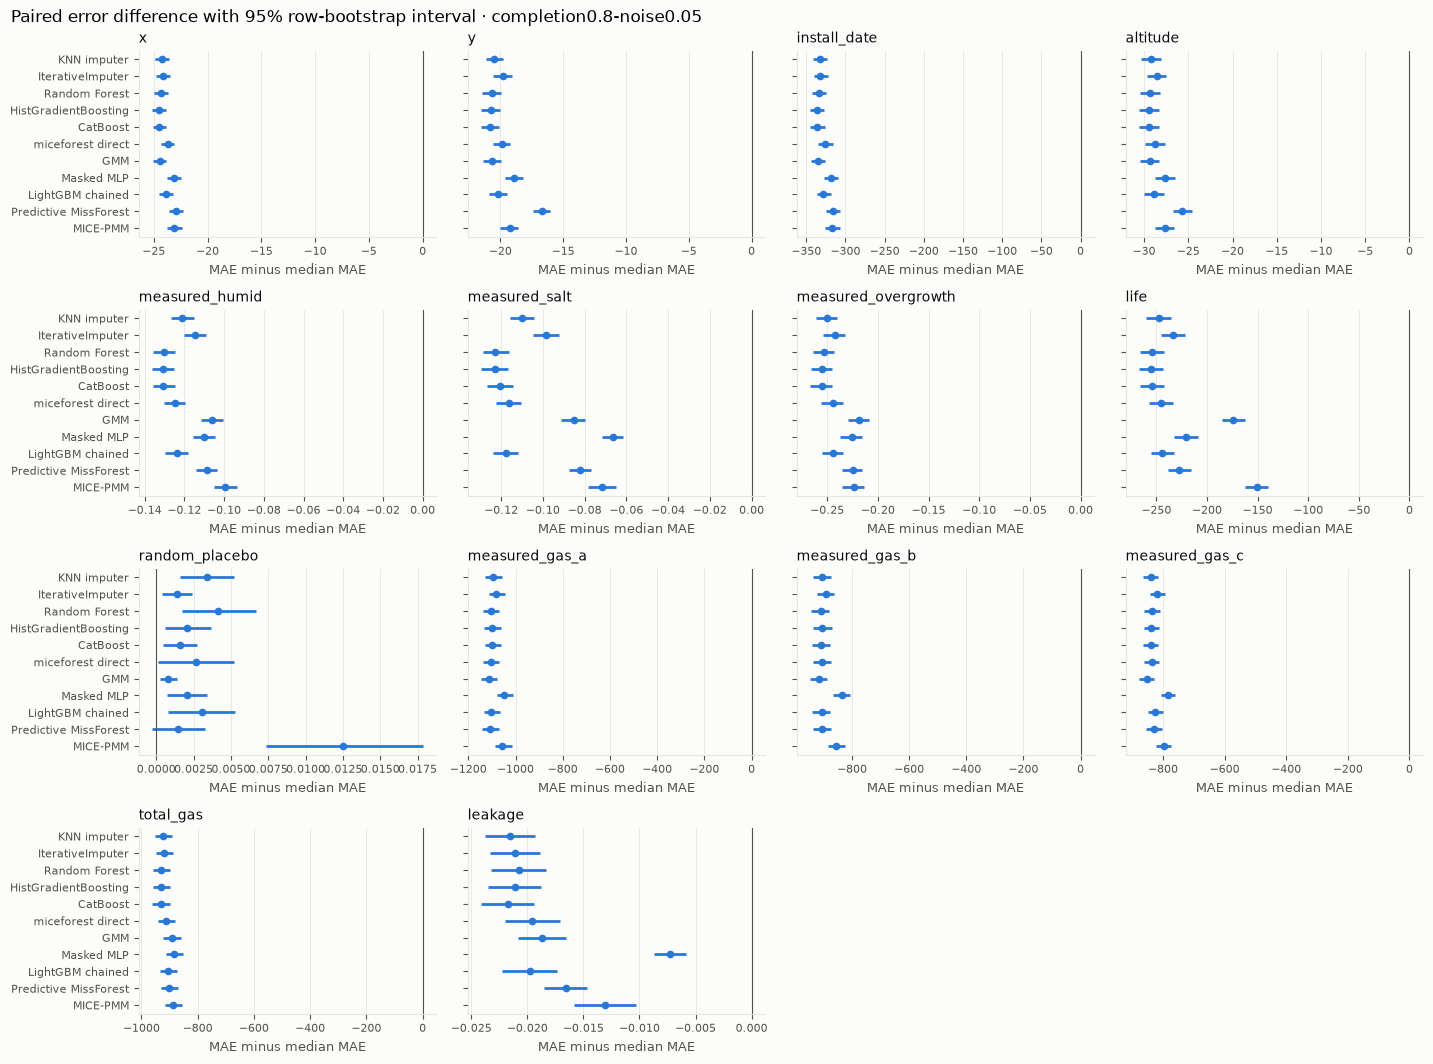

**Figure A.1.** Difference in MAE between every model and the baseline on the same cells, with 95% row-bootstrap intervals, `completion0.8-noise0.05`.

**Table A.1b.** Paired comparison of the best two models for each column, with 95% interval and relative gap.

,target,first,second,metric,difference,low,high,relative gap
0,x,HistGradientBoosting,CatBoost,MAE,0.02965,-0.00352,0.06382,0.07919
1,y,CatBoost,HistGradientBoosting,MAE,0.03434,-0.08491,0.15859,0.00762
2,install_date,HistGradientBoosting,CatBoost,MAE,0.27826,-0.19910,0.73720,0.03977
3,altitude,CatBoost,HistGradientBoosting,MAE,0.03232,-0.08952,0.15321,0.00729
4,measured_humid,HistGradientBoosting,CatBoost,MAE,0.00005,-0.00109,0.00118,0.00116
5,measured_salt,HistGradientBoosting,Random Forest,MAE,0.00033,-0.00176,0.00244,0.00369
6,measured_overgrowth,CatBoost,HistGradientBoosting,MAE,0.00051,-0.00106,0.00212,0.01121
7,life,HistGradientBoosting,CatBoost,MAE,0.54046,-0.82987,1.96934,0.01551
8,random_placebo,GMM,IterativeImputer,MAE,0.00061,-0.00018,0.00149,0.00239
9,measured_gas_a,GMM,Predictive MissForest,MAE,6.65329,-1.86513,14.78587,0.04956


In [48]:
# Best model per column, every model against the baseline, and the best two models per column.
fg.table("Table A.1a", "Best model for each numeric column, the clarity of its lead and the effect of each control.",
         STUDY.targets.round(3))
fg.plot_paired(PAIRS, REPRESENTATIVE, FIGURES)
fg.caption("Figure A.1", f"Difference in MAE between every model and the baseline on the same cells, with 95% "
           f"row-bootstrap intervals, `{REPRESENTATIVE}`.")
closest = PAIRS[PAIRS.scenario.eq(REPRESENTATIVE) & PAIRS.comparison.eq("best two")].copy()
closest["relative gap"] = closest["second error"] / closest["first error"].where(closest["first error"] > 0) - 1
closest = closest.set_index("target").reindex(list(TARGETS)).reset_index()
fg.table("Table A.1b", "Paired comparison of the best two models for each column, with 95% interval and relative gap.",
         closest[["target", "first", "second", "metric", "difference", "low", "high", "relative gap"]].round(5))


### A.2 Fold-seed stability

The representative scenario is repeated with two further fold seeds. The same rows are reused, so this measures sensitivity to the split rather than adding samples. Table A.2a gives the worst rank of each model across seeds and Table A.2b the results on `model_id`.


In [49]:
# Rank and error of every model under three fold seeds.
seed_numeric, seed_labels = STUDY.stability
seed_numeric["relative range"] = seed_numeric["MAE high"] / seed_numeric["MAE low"] - 1
widest = float(seed_numeric["relative range"].max())
fg.table("Table A.2a", f"Worst rank of each model across the three fold seeds; the largest relative MAE range across "
         f"seeds is {widest:.2%}.",
         seed_numeric.pivot(index="target", columns="method", values="worst rank").reindex(list(NUMERIC_TARGETS))[list(NUMERIC_METHODS)])
fg.table("Table A.2b", "Results on `model_id` across the three fold seeds.", seed_labels.round(4))


**Table A.2a.** Worst rank of each model across the three fold seeds; the largest relative MAE range across seeds is 11.98%.

method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct,GMM,Masked MLP,LightGBM chained,Predictive MissForest,MICE-PMM
target,,,,,,,,,,,,
x,12.0,5.0,6.0,4.0,2.0,2.0,8.0,3.0,10.0,7.0,11.0,10.0
y,12.0,5.0,8.0,4.0,2.0,1.0,8.0,4.0,10.0,6.0,11.0,9.0
install_date,12.0,5.0,6.0,4.0,2.0,2.0,8.0,3.0,10.0,7.0,11.0,10.0
altitude,12.0,5.0,8.0,4.0,2.0,1.0,7.0,3.0,10.0,6.0,11.0,10.0
measured_humid,12.0,6.0,7.0,3.0,2.0,3.0,4.0,10.0,9.0,5.0,9.0,11.0
measured_salt,12.0,6.0,7.0,2.0,1.0,4.0,5.0,8.0,11.0,4.0,9.0,10.0
measured_overgrowth,12.0,4.0,7.0,3.0,2.0,2.0,6.0,11.0,8.0,6.0,9.0,10.0
life,12.0,4.0,7.0,3.0,1.0,3.0,5.0,10.0,9.0,6.0,8.0,11.0
random_placebo,1.0,10.0,4.0,11.0,8.0,5.0,11.0,3.0,6.0,9.0,7.0,12.0


**Table A.2b.** Results on `model_id` across the three fold seeds.

,method,accuracy low,accuracy high,best rank,worst rank
0,Mode,0.2799,0.2824,11.0,11.0
1,KNN imputer,0.9766,0.9791,8.0,10.0
2,Random Forest,0.9786,0.9796,6.0,7.0
3,HistGradientBoosting,0.9807,0.9827,2.0,5.0
4,CatBoost,0.9791,0.9817,4.0,6.0
5,miceforest direct,0.9812,0.9837,2.0,5.0
6,GMM,0.9832,0.9842,1.0,2.0
7,Masked MLP,0.9822,0.9852,1.0,3.0
8,LightGBM chained,0.9751,0.9796,7.0,9.0
9,Predictive MissForest,0.9796,0.9817,4.0,6.0


### A.3 Runtime and warnings

Timings are single-threaded fits measured while other workers share the machine, so they are indicative only. A chained task covers many columns, so time is shown per target. Table A.3b lists each kind of warning once.


**Table A.3a.** Fitting and prediction time of every model; a chained task's time is shared between its targets.

,experiment,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,main,Median,630,6.073,0.841,0.011
1,main,Mode,45,0.470,0.057,0.012
2,stability,Median,140,1.336,0.184,0.011
3,stability,Mode,10,0.103,0.013,0.012
4,spatial,Median,70,0.678,0.092,0.011
5,spatial,Mode,5,0.052,0.007,0.012
6,mechanism,Median,420,4.197,0.591,0.011
7,mechanism,Mode,30,0.316,0.036,0.012
8,main,KNN imputer,45,5481.886,6885.535,18.322
9,stability,KNN imputer,10,1215.952,1486.919,18.019


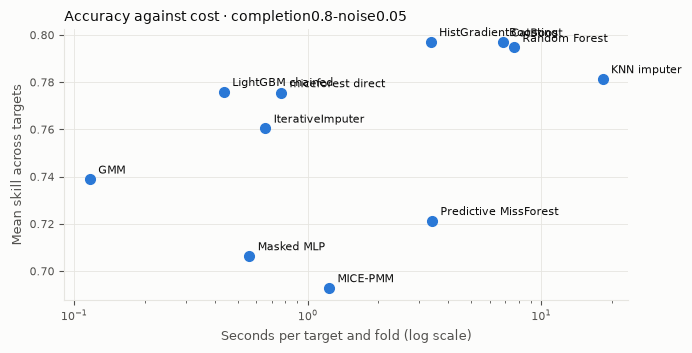

**Figure A.3.** Mean skill over the numeric columns against total fitting time in the main experiment, `completion0.8-noise0.05`.

**Table A.3b.** Kinds of warning raised during fitting, each listed once.

,method,warning_types,tasks,warning_example
0,IterativeImputer,ConvergenceWarning,165,[IterativeImputer] Early stopping criterion not reached.
1,IterativeImputer (5),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.
2,IterativeImputer (30),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.


In [50]:
# Fitting time of every model and the warnings raised during fitting.
fg.table("Table A.3a", "Fitting and prediction time of every model; a chained task's time is shared between its targets.", STUDY.cost.round(3))
fg.plot_cost(STUDY.cost, NUMERIC, REPRESENTATIVE, FIGURES)
fg.caption("Figure A.3", f"Mean skill over the numeric columns against total fitting time in the main experiment, `{REPRESENTATIVE}`.")
with pd.option_context("display.max_colwidth", None):
    fg.table("Table A.3b", "Kinds of warning raised during fitting, each listed once.", ev.warning_table(STUDY.log))


### A.4 Exported tables

The last cell lists the completed table written for each model (Table A.4a) and summarises the run (Table A.4b). Every table of chapters 5 to 9 is also saved in the run folder as a CSV file.


In [51]:
# Completed tables written for each model, and a summary of the run.
fg.table("Table A.4a", "Completed tables written for each model.", STUDY.completed)
fg.table("Table A.4b", "Planned, finished, failed and warned tasks of the run.", ev.run_summary(STUDY.log, STUDY.plan))
print("Run folder:", STUDY.directory)


**Table A.4a.** Completed tables written for each model.

,method,file,cells still missing
0,Median,Median.csv,0
1,KNN imputer,KNN_imputer.csv,0
2,IterativeImputer,IterativeImputer.csv,1965
3,Random Forest,Random_Forest.csv,0
4,HistGradientBoosting,HistGradientBoosting.csv,0
5,CatBoost,CatBoost.csv,0
6,miceforest direct,miceforest_direct.csv,0
7,GMM,GMM.csv,0
8,Masked MLP,Masked_MLP.csv,0
9,LightGBM chained,LightGBM_chained.csv,0


**Table A.4b.** Planned, finished, failed and warned tasks of the run.

,planned tasks,finished tasks,succeeded,failed,tasks with warnings
0,3580,3580,3580,0,175


Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\synthetic-imputation-final\outputs\imputation-study\runs\20261115-121714


### A.5 References

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society: Series B*, 39(1), 1–38.
- Du, T., Melis, L., & Wang, T. (2024). ReMasker: Imputing tabular data with masked autoencoding. *International Conference on Learning Representations (ICLR)*.
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics*, 29(5), 1189–1232.
- Ghahramani, Z., & Jordan, M. I. (1994). Supervised learning from incomplete data via an EM approach. *Advances in Neural Information Processing Systems*, 6, 120–127.
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics*, 12(1), 55–67.
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30.
- Little, R. J. A. (1988). Missing-data adjustments in large surveys. *Journal of Business & Economic Statistics*, 6(3), 287–296.
- Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems*, 31.
- Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913–929.
- Rubin, D. B. (1976). Inference and missing data. *Biometrika*, 63(3), 581–592.
- Stekhoven, D. J., & Bühlmann, P. (2012). MissForest: Non-parametric missing value imputation for mixed-type data. *Bioinformatics*, 28(1), 112–118.
- Troyanskaya, O., Cantor, M., Sherlock, G., Brown, P., Hastie, T., Tibshirani, R., Botstein, D., & Altman, R. B. (2001). Missing value estimation methods for DNA microarrays. *Bioinformatics*, 17(6), 520–525.
- van Buuren, S., & Groothuis-Oudshoorn, K. (2011). mice: Multivariate imputation by chained equations in R. *Journal of Statistical Software*, 45(3), 1–67.
